In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import scipy

# Loading The dataset

In [2]:
train_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/trained/'
not_trained_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/not trained/'
AI_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/trained'
AI_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/2arm/trained'
bl_4arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/4 arm'
bl_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/2 arm'
all_trained_4arm_df = []
all_not_trained_4arm_df = []
all_trained_2arm_df = []
all_not_trained_2arm_df = []
all_AI_4arm_df = []
all_AI_2arm_df = []
all_bl_4arm_df = []
all_bl_2arm_df = []
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_trained_4arm_df.append(pd.read_csv(train_path + main_file))
    all_trained_2arm_df.append(pd.read_csv(train_path + file_2arm))
    
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_not_trained_4arm_df.append(pd.read_csv(not_trained_path + main_file))
    all_not_trained_2arm_df.append(pd.read_csv(not_trained_path + file_2arm))


for sub in range(1, 21):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_AI_4arm_df.append(pd.read_csv(AI_path + main_file))
    all_AI_2arm_df.append(pd.read_csv(AI_2arm_path + file_2arm))
    
for sub in range(1, 41):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_bl_4arm_df.append(pd.read_csv(bl_4arm_path + main_file))
    all_bl_2arm_df.append(pd.read_csv(bl_2arm_path + file_2arm))

In [3]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df + all_bl_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df + all_bl_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
g3 = 'Solo'

# Sample Size Sensitivity Analysis

In [4]:
from statsmodels.stats.power import TTestIndPower, FTestAnovaPower

alpha = 0.05

n_soli = g1_len
n_solu = g2_len
n_solo = g3_len

print("Final sample sizes:")
print(f"SoLI: {n_soli}")
print(f"SoLU: {n_solu}")
print(f"Solo: {n_solo}")
print(f"Total: {n_soli + n_solu + n_solo}")

Final sample sizes:
SoLI: 45
SoLU: 45
Solo: 40
Total: 130


In [5]:
ttest_power = TTestIndPower()

# SoLI vs SoLU
d_80_soli_solu = ttest_power.solve_power(
    effect_size=None,
    nobs1=n_soli,
    alpha=alpha,
    power=0.80,
    ratio=n_solu / n_soli,
    alternative='two-sided'
)

d_90_soli_solu = ttest_power.solve_power(
    effect_size=None,
    nobs1=n_soli,
    alpha=alpha,
    power=0.90,
    ratio=n_solu / n_soli,
    alternative='two-sided'
)

# SoLI vs Solo
d_80_soli_solo = ttest_power.solve_power(
    effect_size=None,
    nobs1=n_soli,
    alpha=alpha,
    power=0.80,
    ratio=n_solo / n_soli,
    alternative='two-sided'
)

d_90_soli_solo = ttest_power.solve_power(
    effect_size=None,
    nobs1=n_soli,
    alpha=alpha,
    power=0.90,
    ratio=n_solo / n_soli,
    alternative='two-sided'
)

# SoLU vs Solo
d_80_solu_solo = ttest_power.solve_power(
    effect_size=None,
    nobs1=n_solu,
    alpha=alpha,
    power=0.80,
    ratio=n_solo / n_solu,
    alternative='two-sided'
)

d_90_solu_solo = ttest_power.solve_power(
    effect_size=None,
    nobs1=n_solu,
    alpha=alpha,
    power=0.90,
    ratio=n_solo / n_solu,
    alternative='two-sided'
)

print("Minimum detectable Cohen's d")
print("--------------------------------")
print(f"SoLI vs SoLU: 80% = {d_80_soli_solu:.3f}, 90% = {d_90_soli_solu:.3f}")
print(f"SoLI vs Solo: 80% = {d_80_soli_solo:.3f}, 90% = {d_90_soli_solo:.3f}")
print(f"SoLU vs Solo: 80% = {d_80_solu_solo:.3f}, 90% = {d_90_solu_solo:.3f}")

Minimum detectable Cohen's d
--------------------------------
SoLI vs SoLU: 80% = 0.597, 90% = 0.691
SoLI vs Solo: 80% = 0.616, 90% = 0.713
SoLU vs Solo: 80% = 0.616, 90% = 0.713


In [6]:
anova_power = FTestAnovaPower()

f_80 = anova_power.solve_power(
    effect_size=None,
    nobs=n_soli + n_solu + n_solo,
    alpha=alpha,
    power=0.80,
    k_groups=3
)

f_90 = anova_power.solve_power(
    effect_size=None,
    nobs=n_soli + n_solu + n_solo,
    alpha=alpha,
    power=0.90,
    k_groups=3
)

print("Three-group omnibus sensitivity:")
print(f"80% power: Cohen's f = {f_80:.3f}")
print(f"90% power: Cohen's f = {f_90:.3f}")

Three-group omnibus sensitivity:
80% power: Cohen's f = 0.275
90% power: Cohen's f = 0.316


# Rewards

In [7]:
def trial_reward(list_subs):
    all_rewards = []
    for sub in list_subs:
        outcome = sub['outcome']
        outcome = outcome.replace('win', 1)
        outcome = outcome.replace('lose', 0)
        all_rewards.append(np.array(outcome.copy()))
    return np.array(all_rewards)

In [8]:
trained_rewards = trial_reward(all_trained_4arm_df)
not_trained_rewards = trial_reward(all_not_trained_4arm_df)
bl_rewards = trial_reward(all_bl_4arm_df)

In [9]:
def mov_avg(data, ws):
    moving_averages = []
    for i in range(len(data)):
        if i < ws - 1:
            moving_averages.append(data[i])
        else:
            window = data[i - ws + 1:i + 1]
            window_average = sum(window) / ws
            moving_averages.append(window_average)

    return moving_averages

In [10]:
mean_trained_rewards = np.mean(trained_rewards, axis=0)
sem_trained_rewards = scipy.stats.sem(trained_rewards, axis=0)
trained_rewards_cl = sem_trained_rewards * scipy.stats.t.ppf((1 + 0.95) / 2., trained_rewards.shape[0] - 1)
trained_x = np.arange(mean_trained_rewards.shape[0])

mean_not_trained_rewards = np.mean(not_trained_rewards, axis=0)
sem_not_trained_rewards = scipy.stats.sem(not_trained_rewards, axis=0)
not_trained_rewards_cl = sem_not_trained_rewards * scipy.stats.t.ppf((1 + 0.95) / 2., not_trained_rewards.shape[0] - 1)
not_trained_x = np.arange(mean_trained_rewards.shape[0])

mean_bl_rewards = np.mean(bl_rewards, axis=0)
sem_bl_rewards = scipy.stats.sem(bl_rewards, axis=0)
bl_rewards_cl = sem_bl_rewards * scipy.stats.t.ppf((1 + 0.95) / 2., bl_rewards.shape[0] - 1)
bl_x = np.arange(mean_trained_rewards.shape[0])

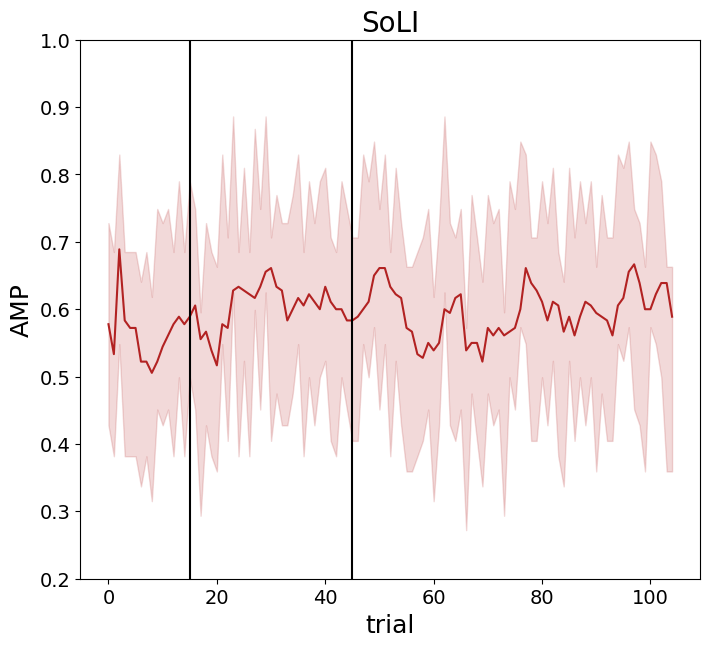

In [11]:
# Solo olivedrab,
# SoLU royalblue,
# SoLI firebrick 

fig, axs = plt.subplots(1, 1, sharey='all', figsize=(8, 7))

av_trained_rewards = mov_avg(mean_trained_rewards, 4)
axs.plot(trained_x, av_trained_rewards, color='firebrick')
axs.fill_between(trained_x, mean_trained_rewards - trained_rewards_cl, mean_trained_rewards + trained_rewards_cl, color='firebrick', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')
axs.set_ylim([0.2, 1])
axs.set_title('SoLI', fontsize=20)
axs.set_xlabel('trial', fontsize=18)
axs.set_ylabel('AMP', fontsize=18)
axs.tick_params(axis='both', labelsize=14)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/soli-rew.svg')

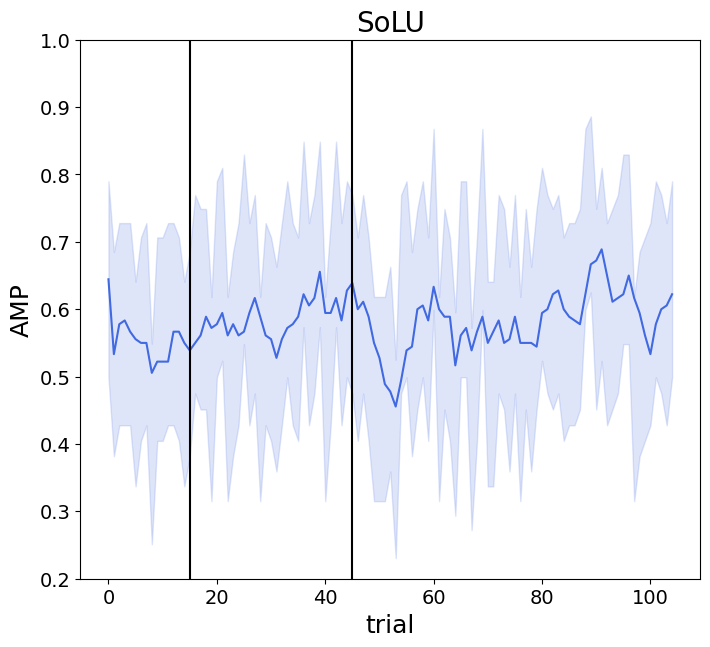

In [12]:
fig, axs = plt.subplots(1, 1, sharey='all', figsize=(8, 7))

av_not_trained_rewards = mov_avg(mean_not_trained_rewards, 4)
axs.plot(not_trained_x, av_not_trained_rewards, color='royalblue')
axs.fill_between(not_trained_x, mean_not_trained_rewards - not_trained_rewards_cl, mean_not_trained_rewards + not_trained_rewards_cl, color='royalblue', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')
axs.set_ylim([0.2, 1])
axs.set_title('SoLU',fontsize=20)
axs.set_xlabel('trial', fontsize=18)
axs.set_ylabel('AMP', fontsize=18)
axs.tick_params(axis='both', labelsize=14)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/solu-rew.svg')

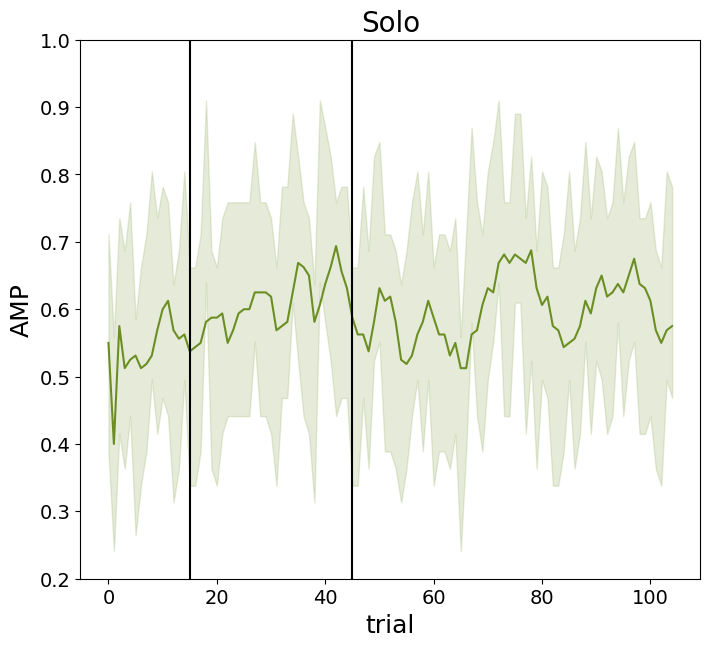

In [13]:
fig, axs = plt.subplots(1, 1, sharey='all', figsize=(8, 7))

av_bl_rewards = mov_avg(mean_bl_rewards, 4)
axs.plot(bl_x, av_bl_rewards, color='olivedrab')
axs.fill_between(bl_x, mean_bl_rewards - bl_rewards_cl, mean_bl_rewards + bl_rewards_cl, color='olivedrab', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')
axs.set_ylim([0.2, 1])
axs.set_title('Solo', fontsize=20)
axs.set_xlabel('trial', fontsize=18)
axs.set_ylabel('AMP', fontsize=18)
axs.tick_params(axis='both', labelsize=14)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/solo-rew.svg')

In [14]:
trained_rewards.shape

(45, 105)

In [15]:
from scipy.stats import f_oneway

def is_sig(p):
    if p < 0.05:
        sig = 1
    else:
        sig = 0
    return sig

f, anova_p = f_oneway(trained_rewards, not_trained_rewards, bl_rewards)
anova_sig = []
for p in anova_p:
    anova_sig.append(is_sig(p))
anova_sig = np.array(anova_sig)
anova_sig


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

# Probability of choosing cards

In [16]:
def sort_choices(all_sub_df):
    all_best_card = []
    all_second_card = []
    all_third_card = []
    all_worst_card = []
    for sub_idx, sub in enumerate(all_sub_df):
        best_card = np.zeros(105)
        second_card = np.zeros(105)
        third_card = np.zeros(105)
        worst_card = np.zeros(105)
        for trial in range(len(all_sub_df[0])):
            cards_type = eval(sub['card probs'][trial])
            best_idx = cards_type.index(0.7)
            second_idx = cards_type.index(0.6)
            third_idx = cards_type.index(0.5)
            worst_idx = cards_type.index(0.4)
            choice = sub['choice'][trial]
            if choice == best_idx:
                best_card[trial] = 1
            elif choice == second_idx: 
                second_card[trial] = 1
            elif choice == third_idx:
                third_card[trial] = 1
            else:
                worst_card[trial] = 1
        all_best_card.append(best_card.copy())
        all_second_card.append(second_card.copy())
        all_third_card.append(third_card.copy())
        all_worst_card.append(worst_card.copy())
    all_best_card = np.array(all_best_card)
    all_second_card = np.array(all_second_card)
    all_third_card = np.array(all_third_card)
    all_worst_card = np.array(all_worst_card)     
    
    return all_best_card, all_second_card, all_third_card, all_worst_card

In [17]:
all_best_card, all_second_card, all_third_card, all_worst_card = sort_choices(all_sub_df)

In [18]:
g3_start = g1_len + g2_len

g1_best_card_mean = np.mean(all_best_card[:g1_len], axis=0)
g1_second_card_mean = np.mean(all_second_card[:g1_len], axis=0)
g1_third_card_mean = np.mean(all_third_card[:g1_len], axis=0)
g1_worst_card_mean = np.mean(all_worst_card[:g1_len], axis=0)

g1_best_card_var = np.var(all_best_card[:g1_len], axis=0)
g1_second_card_var = np.var(all_second_card[:g1_len], axis=0)
g1_third_card_var = np.var(all_third_card[:g1_len], axis=0)
g1_worst_card_var = np.var(all_worst_card[:g1_len], axis=0)


g2_best_card_mean = np.mean(all_best_card[g1_len:g3_start], axis=0)
g2_second_card_mean = np.mean(all_second_card[g1_len:g3_start], axis=0)
g2_third_card_mean = np.mean(all_third_card[g1_len:g3_start], axis=0)
g2_worst_card_mean = np.mean(all_worst_card[g1_len:g3_start], axis=0)

g2_best_card_var = np.var(all_best_card[g1_len:g3_start], axis=0)
g2_second_card_var = np.var(all_second_card[g1_len:g3_start], axis=0)
g2_third_card_var = np.var(all_third_card[g1_len:g3_start], axis=0)
g2_worst_card_var = np.var(all_worst_card[g1_len:g3_start], axis=0)


g3_best_card_mean = np.mean(all_best_card[g3_start:], axis=0)
g3_second_card_mean = np.mean(all_second_card[g3_start:], axis=0)
g3_third_card_mean = np.mean(all_third_card[g3_start:], axis=0)
g3_worst_card_mean = np.mean(all_worst_card[g3_start:], axis=0)

g3_best_card_var = np.var(all_best_card[g3_start:], axis=0)
g3_second_card_var = np.var(all_second_card[g3_start:], axis=0)
g3_third_card_var = np.var(all_third_card[g3_start:], axis=0)
g3_worst_card_var = np.var(all_worst_card[g3_start:], axis=0)

In [19]:
def mov_avg(data, ws):
    moving_averages = []
    for i in range(len(data)):
        if i < ws - 1:
            moving_averages.append(data[i])
        else:
            window = data[i - ws + 1:i + 1]
            window_average = sum(window) / ws
            moving_averages.append(window_average)

    return moving_averages

In [20]:
def smooth_each_block(best_card_mean, second_card_mean, third_card_mean, worst_card_mean, ws):   
    smoothed_best = mov_avg(best_card_mean[:15], ws) + mov_avg(best_card_mean[15:45], ws) + mov_avg(best_card_mean[45:], ws)
    smoothed_second = mov_avg(second_card_mean[:15], ws) + mov_avg(second_card_mean[15:45], ws) + mov_avg(second_card_mean[45:], ws)
    smoothed_third = mov_avg(third_card_mean[:15], ws) + mov_avg(third_card_mean[15:45], ws) + mov_avg(third_card_mean[45:], ws)
    smoothed_worst = mov_avg(worst_card_mean[:15], ws) + mov_avg(worst_card_mean[15:45], ws) + mov_avg(worst_card_mean[45:], ws)
    
    return smoothed_best, smoothed_second, smoothed_third, smoothed_worst

In [21]:
g1_smoothed_best, g1_smoothed_second, g1_smoothed_third, g1_smoothed_worst = smooth_each_block(g1_best_card_mean, g1_second_card_mean, g1_third_card_mean, g1_worst_card_mean, 4)
g2_smoothed_best, g2_smoothed_second, g2_smoothed_third, g2_smoothed_worst = smooth_each_block(g2_best_card_mean, g2_second_card_mean, g2_third_card_mean, g2_worst_card_mean, 4)
g3_smoothed_best, g3_smoothed_second, g3_smoothed_third, g3_smoothed_worst = smooth_each_block(g3_best_card_mean, g3_second_card_mean, g3_third_card_mean, g3_worst_card_mean, 4)

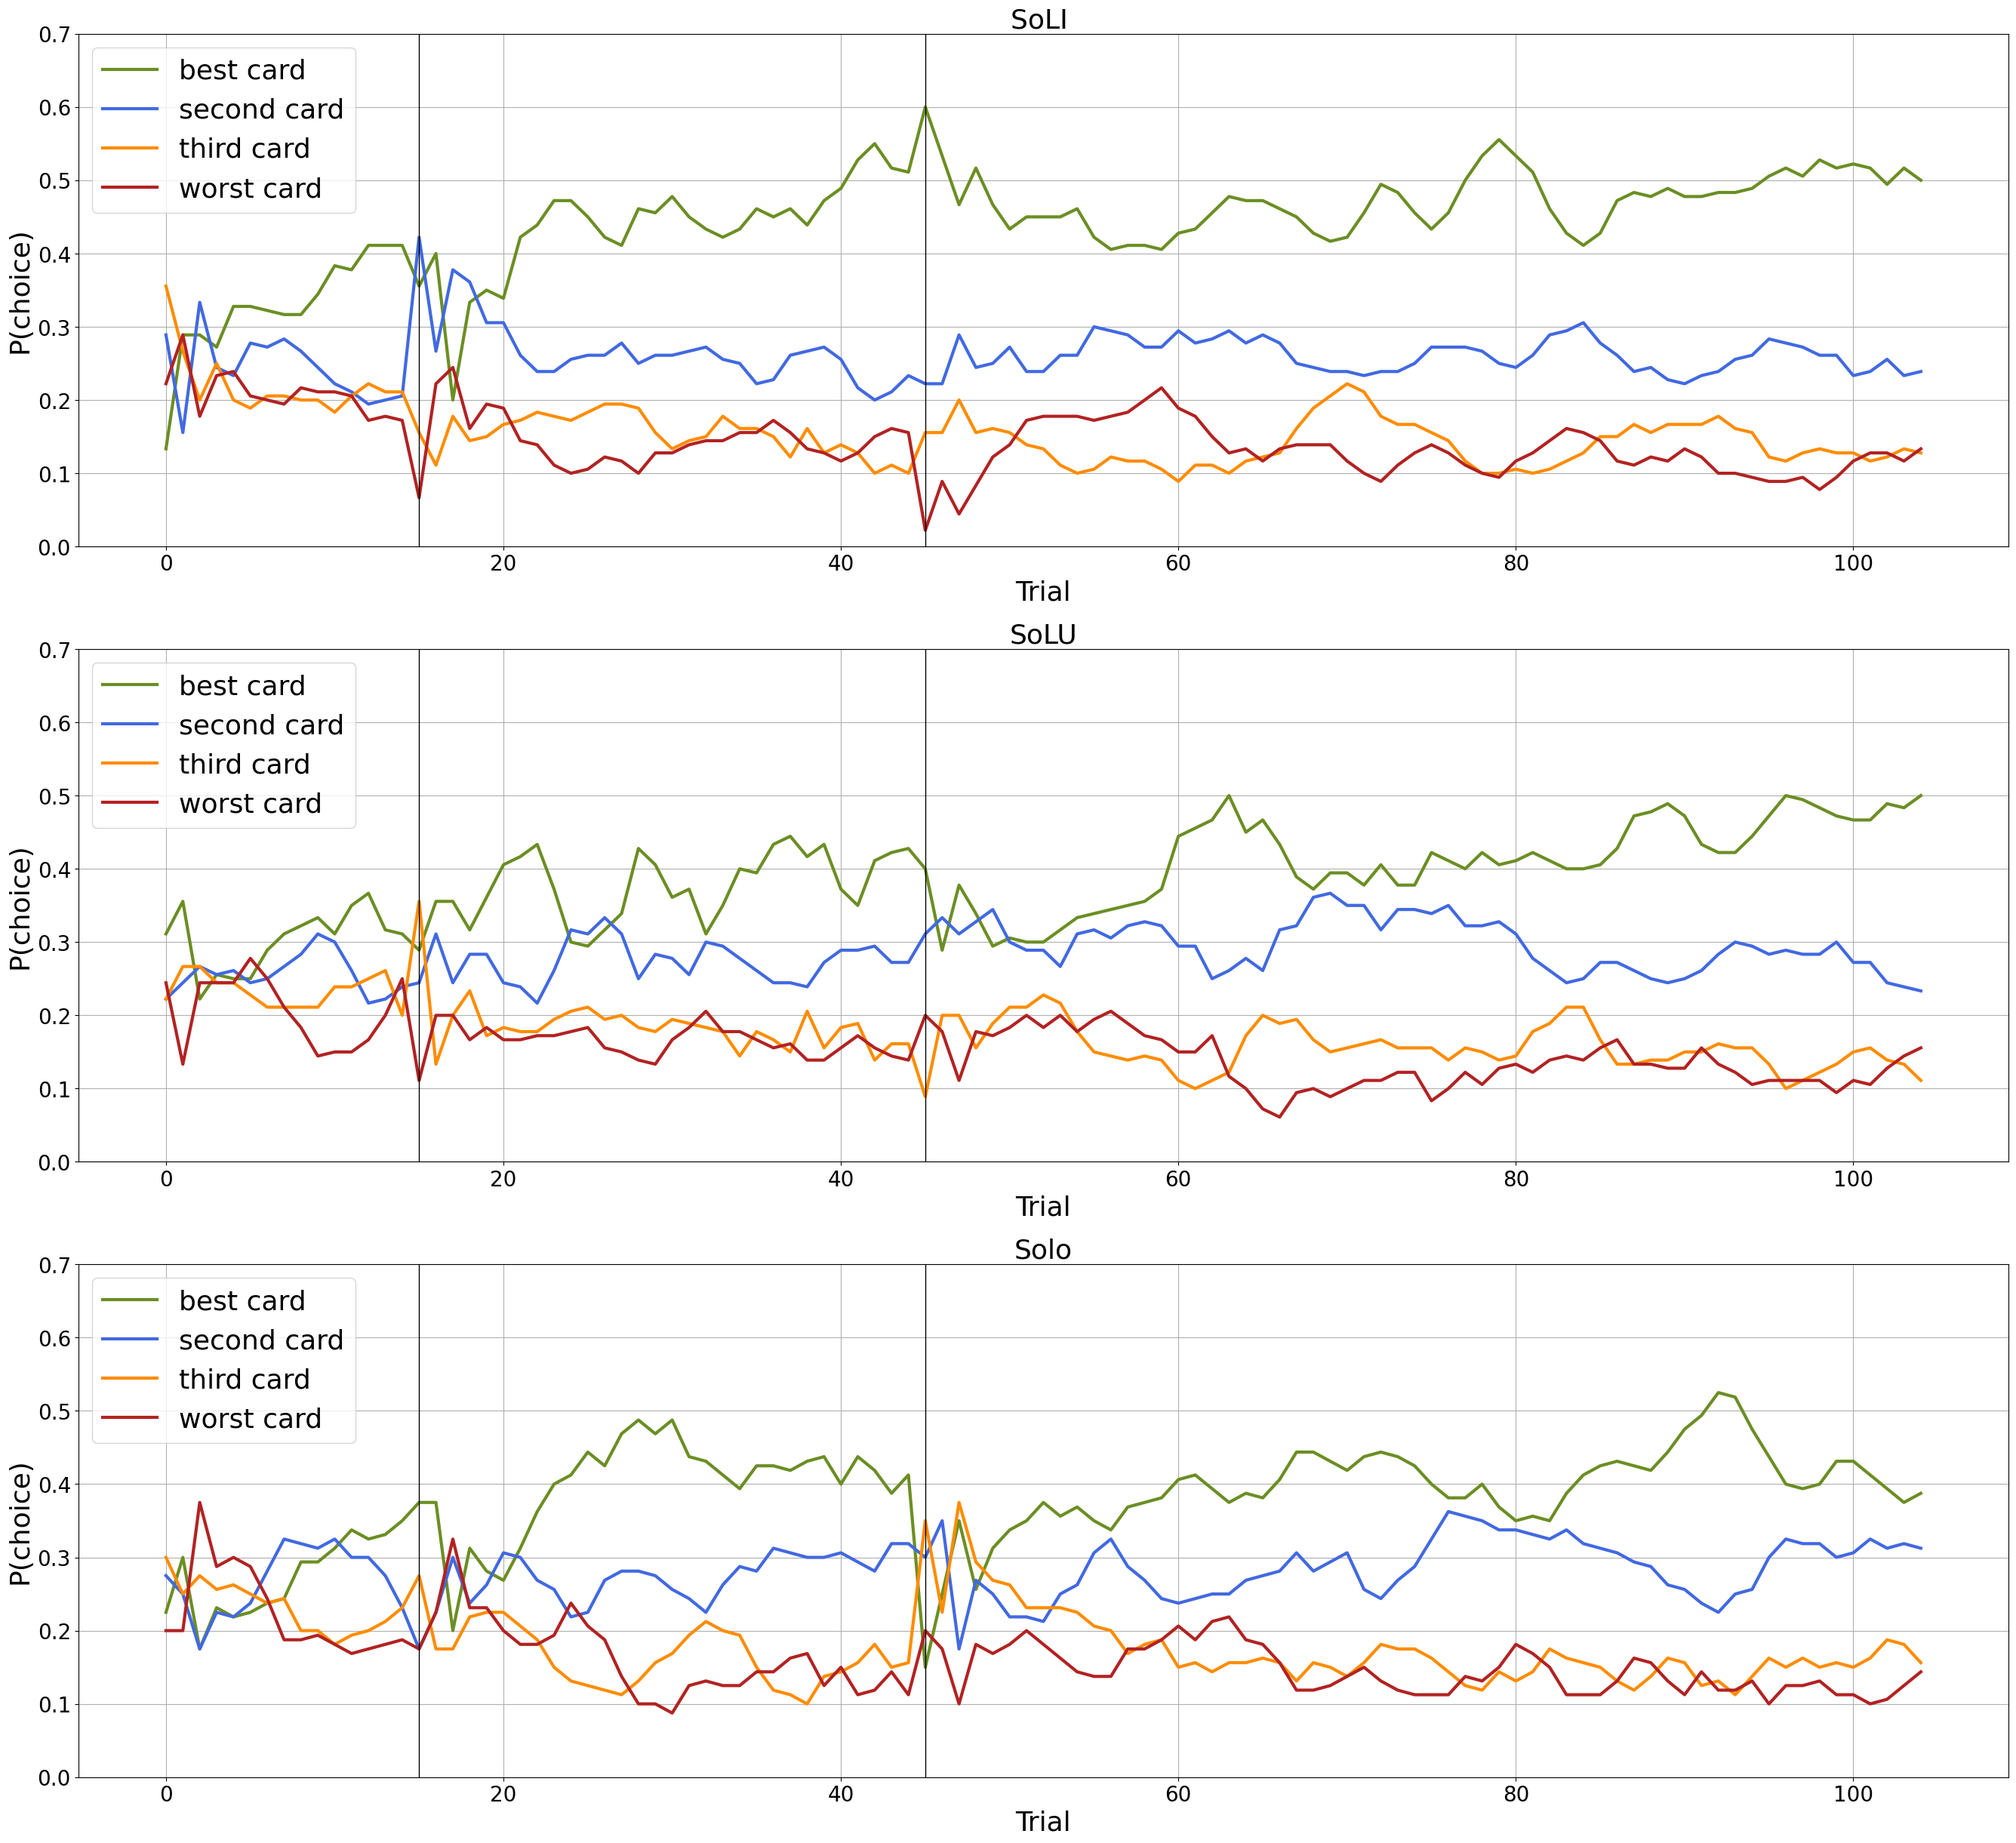

In [22]:
fig, axs = plt.subplots(3, 1, figsize=(33, 30))
# fig.suptitle('Probablity of choosing cards')

fnt_size = 26
lbl_size = 20

axs[0].plot(g1_smoothed_best, color='olivedrab', label='best card', linewidth=3)
axs[0].plot(g1_smoothed_second, color='royalblue', label='second card', linewidth=3)
axs[0].plot(g1_smoothed_third, color='darkorange', label='third card', linewidth=3)
axs[0].plot(g1_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
axs[0].legend()
axs[0].axvline(x=15, color='black', linewidth=1)
axs[0].axvline(x=45, color='black', linewidth=1)
axs[0].set_ylim([0, 0.7])
axs[0].set_title(g1, fontsize=fnt_size)
axs[0].set_xlabel('Trial', fontsize=fnt_size)
axs[0].set_ylabel('P(choice)', fontsize=fnt_size)
axs[0].grid()
axs[0].legend(loc=2, prop={'size': 26})
axs[0].tick_params(axis='both', labelsize=lbl_size)


axs[1].plot(g2_smoothed_best, color='olivedrab', label='best card', linewidth=3)
axs[1].plot(g2_smoothed_second, color='royalblue', label='second card', linewidth=3)
axs[1].plot(g2_smoothed_third, color='darkorange', label='third card', linewidth=3)
axs[1].plot(g2_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
axs[1].legend()
axs[1].axvline(x=15, color='black', linewidth=1)
axs[1].axvline(x=45, color='black', linewidth=1)
axs[1].set_ylim([0, 0.7])
axs[1].grid()
axs[1].set_title(g2, fontsize=fnt_size)
axs[1].set_xlabel('Trial', fontsize=fnt_size)
axs[1].set_ylabel('P(choice)', fontsize=fnt_size)
axs[1].legend(loc=2, prop={'size': 26})
axs[1].tick_params(axis='both', labelsize=lbl_size)


axs[2].plot(g3_smoothed_best, color='olivedrab', label='best card', linewidth=3)
axs[2].plot(g3_smoothed_second, color='royalblue', label='second card', linewidth=3)
axs[2].plot(g3_smoothed_third, color='darkorange', label='third card', linewidth=3)
axs[2].plot(g3_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
# axs[2].plot(g3_smoothed_best, color='darkslategray', label='best card', linewidth=3)
# axs[2].plot(g3_smoothed_second, color='indianred', label='second card', linewidth=3)
# axs[2].plot(g3_smoothed_third, color='darkolivegreen', label='third card', linewidth=3)
# axs[2].plot(g3_smoothed_worst, color='darkgoldenrod', label='worst card', linewidth=3)
axs[2].legend()
axs[2].axvline(x=15, color='black', linewidth=1)
axs[2].axvline(x=45, color='black', linewidth=1)
axs[2].set_ylim([0, 0.7])
axs[2].grid()
axs[2].set_title(g3, fontsize=fnt_size)
axs[2].set_xlabel('Trial', fontsize=fnt_size)
axs[2].set_ylabel('P(choice)', fontsize=fnt_size)
axs[2].legend(loc=2, prop={'size': 26})
axs[2].tick_params(axis='both', labelsize=lbl_size);

# #003f5c -> 'darkslategrey' or 'darkslategray'

# #58508d -> 'darkslateblue' (This is an approximation)

# #8a508f -> 'rebeccapurple' (This is an approximation)

# #ff6361 -> 'tomato'

# Alternative Palette 2: Sophisticated Earth Tones
# Similarly, these are best defined with HEX codes. The closest named colors are:

# #2F4858 -> 'darkslategray'

# #B0413E -> 'firebrick' or 'indianred'

# #687431 -> 'darkolivegreen'

# #D4A25F -> 'peru' or 'darkgoldenrod'


fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/beh.svg')

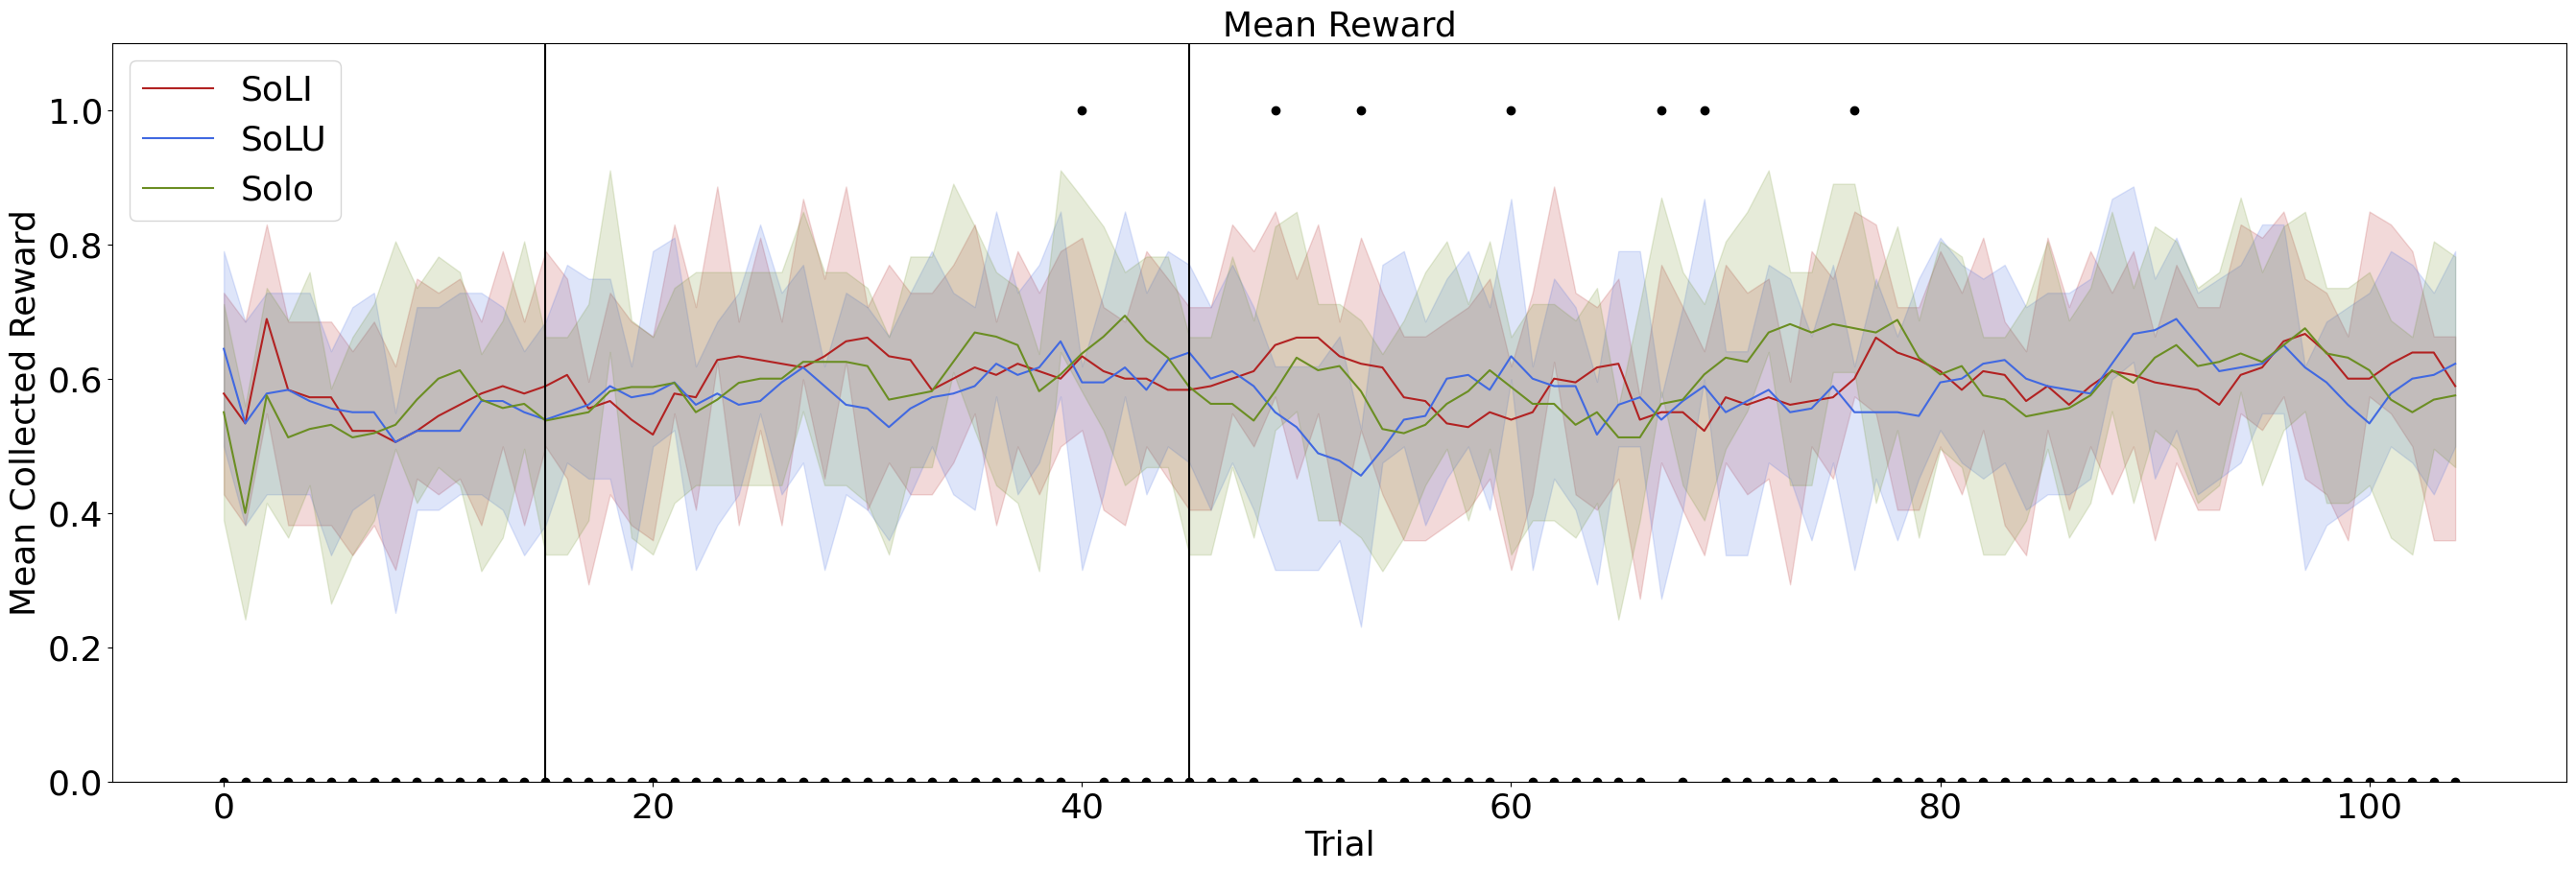

In [27]:
fig, axs = plt.subplots(1, 1, figsize=(33, 10))

x = [i for i in range(105)]

axs.plot(trained_x, av_trained_rewards, color='firebrick', label = 'SoLI')
axs.fill_between(trained_x, mean_trained_rewards - trained_rewards_cl, mean_trained_rewards + trained_rewards_cl, color='firebrick', alpha=0.17)




axs.tick_params(axis='both', labelsize=26)


axs.plot(not_trained_x, av_not_trained_rewards, color='royalblue', label='SoLU')
axs.fill_between(not_trained_x, mean_not_trained_rewards - not_trained_rewards_cl, mean_not_trained_rewards + not_trained_rewards_cl, color='royalblue', alpha=0.17)



axs.tick_params(axis='both', labelsize=26)

av_bl_rewards = mov_avg(mean_bl_rewards, 4)
axs.plot(bl_x, av_bl_rewards, color='olivedrab', label='Solo')
axs.fill_between(bl_x, mean_bl_rewards - bl_rewards_cl, mean_bl_rewards + bl_rewards_cl, color='olivedrab', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')

axs.set_title('Mean Reward', fontsize=26)
axs.set_xlabel('Trial', fontsize=26)
axs.set_ylabel('Mean Collected Reward', fontsize=26)
axs.tick_params(axis='both', labelsize=26)

axs.scatter(x, anova_sig, color='black')
axs.set_ylim([0, 1.1])
axs.legend(loc=2, prop={'size': 26})
axs.tick_params(axis='both', labelsize=26)


fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/all-rew.svg')

# axs[0].plot(g1_smoothed_best, color='olivedrab', label='best card', linewidth=3)
# axs[0].plot(g1_smoothed_second, color='royalblue', label='second card', linewidth=3)
# axs[0].plot(g1_smoothed_third, color='darkorange', label='third card', linewidth=3)
# axs[0].plot(g1_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
# axs[0].legend()
# axs[0].axvline(x=15, color='black', linewidth=1)
# axs[0].axvline(x=45, color='black', linewidth=1)
# axs[0].set_ylim([0, 0.7])
# axs[0].set_title(g1, fontsize=20)
# axs[0].set_xlabel('trial', fontsize=18)
# axs[0].set_ylabel('Probability of choice', fontsize=18)
# axs[0].grid()
# axs[0].legend(loc=2, prop={'size': 20})
# axs[0].tick_params(axis='both', labelsize=18)

## Optimal-card choice across groups

In [28]:
# ============================================================
# Optimal-card choice probability across groups
# ============================================================

# Calculate participant-level smoothed trajectories so that
# confidence intervals reflect between-participant variability.

def smooth_subject_best_choices(data, window=3):
    smoothed = []

    for subject in data:
        subject_smoothed = (
            mov_avg(subject[:15], window)
            + mov_avg(subject[15:45], window)
            + mov_avg(subject[45:], window)
        )

        smoothed.append(subject_smoothed)

    return np.asarray(smoothed)


soli_best_smoothed = smooth_subject_best_choices(
    all_best_card[:g1_len],
    window=4
)

solu_best_smoothed = smooth_subject_best_choices(
    all_best_card[g1_len:g1_len + g2_len],
    window=4
)

solo_best_smoothed = smooth_subject_best_choices(
    all_best_card[g1_len + g2_len:],
    window=4
)


def mean_ci95(data):

    mean = np.mean(data, axis=0)

    sem = scipy.stats.sem(
        data,
        axis=0
    )

    critical = scipy.stats.t.ppf(
        0.975,
        data.shape[0] - 1
    )

    ci = sem * critical

    return mean, ci


soli_mean, soli_ci = mean_ci95(
    soli_best_smoothed
)

solu_mean, solu_ci = mean_ci95(
    solu_best_smoothed
)

solo_mean, solo_ci = mean_ci95(
    solo_best_smoothed
)

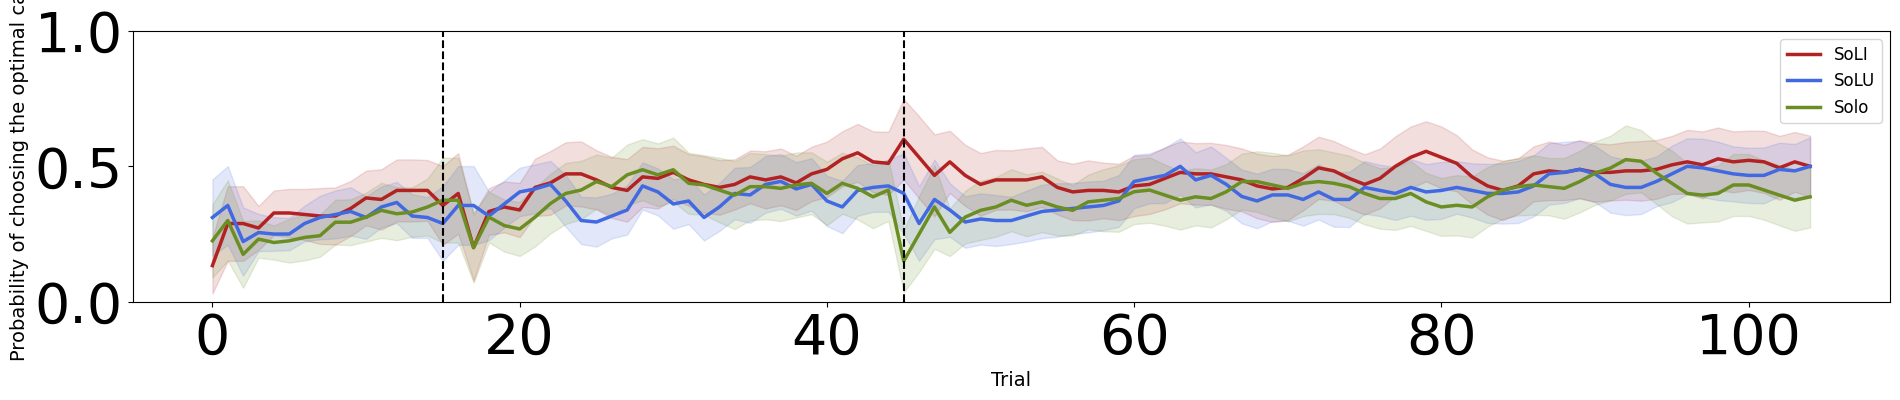

In [29]:
x = np.arange(105)

fig, ax = plt.subplots(
    figsize=(20, 5)
)

ax.plot(
    x,
    soli_mean,
    label='SoLI',
    color='firebrick',
    linewidth=2.5
)

ax.fill_between(
    x,
    soli_mean - soli_ci,
    soli_mean + soli_ci,
    color='firebrick',
    alpha=0.15
)

ax.plot(
    x,
    solu_mean,
    label='SoLU',
    color='royalblue',
    linewidth=2.5
)

ax.fill_between(
    x,
    solu_mean - solu_ci,
    solu_mean + solu_ci,
    color='royalblue',
    alpha=0.15
)

ax.plot(
    x,
    solo_mean,
    label='Solo',
    color='olivedrab',
    linewidth=2.5
)

ax.fill_between(
    x,
    solo_mean - solo_ci,
    solo_mean + solo_ci,
    color='olivedrab',
    alpha=0.15
)

ax.axvline(
    x=15,
    linestyle='--',
    color='black'
)

ax.axvline(
    x=45,
    linestyle='--',
    color='black'
)

ax.set_ylim(
    0,
    1
)

ax.set_xlabel(
    'Trial',
    fontsize=14
)

ax.set_ylabel(
    'Probability of choosing the optimal card',
    fontsize=14
)

ax.legend(
    fontsize=12
)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/allprobs.svg')

plt.tight_layout()
plt.show()

NameError: name 'all_conf' is not defined

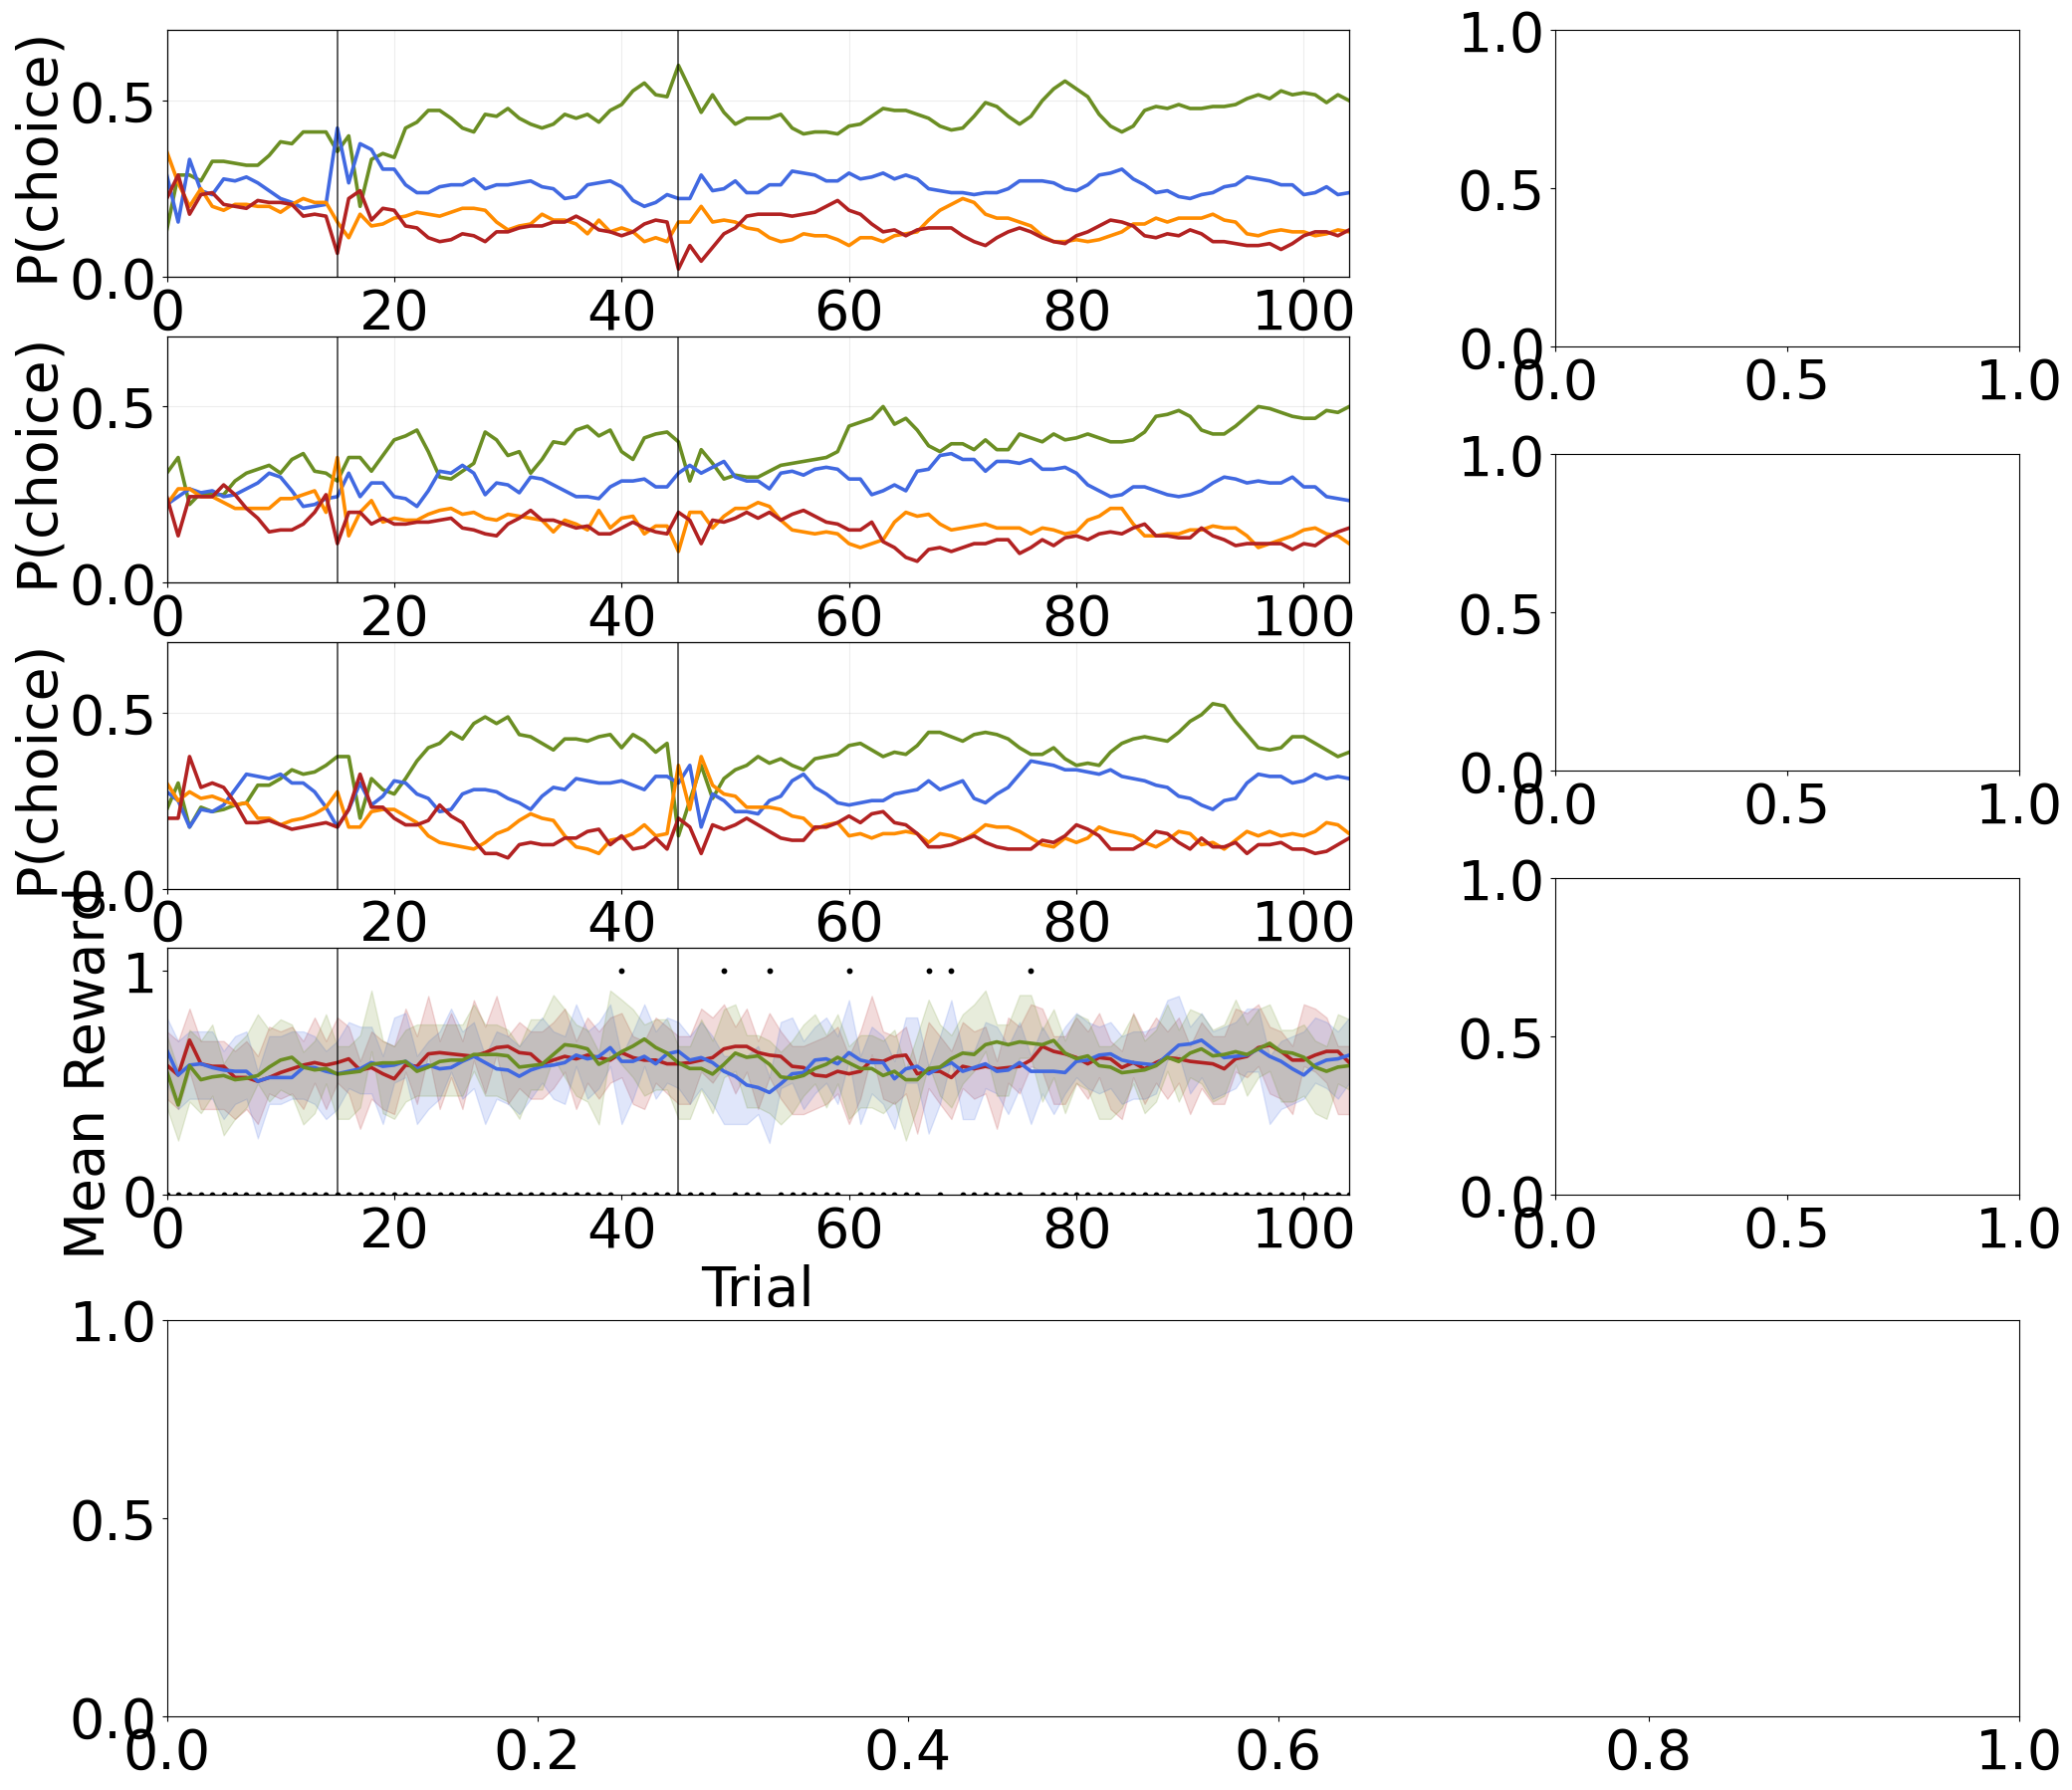

In [30]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy import stats

# ============================================================
# GLOBAL SETTINGS
# ============================================================

FONT_SIZE = 40
CONF_FONT_SIZE = 30
LINE_WIDTH = 2.6
FIGURE_SIZE = (24, 22)

COLORS = {
    'SoLI': 'firebrick',
    'SoLU': 'royalblue',
    'Solo': 'olivedrab',
    'best': 'olivedrab',
    'second': 'royalblue',
    'third': 'darkorange',
    'worst': 'firebrick'
}

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': FONT_SIZE,
    'axes.labelsize': FONT_SIZE,
    'xtick.labelsize': FONT_SIZE,
    'ytick.labelsize': FONT_SIZE,
    'legend.fontsize': FONT_SIZE,
    'svg.fonttype': 'none'
})

# ============================================================
# FIGURE LAYOUT
# ============================================================

fig = plt.figure(figsize=FIGURE_SIZE)

# Reduced vertical spacing between upper and bottom sections
outer = GridSpec(
    2, 1,
    figure=fig,
    height_ratios=[4.4, 1.5],
    hspace=0.16
)

top = outer[0].subgridspec(
    1, 2,
    width_ratios=[2.55, 1.0],
    wspace=0.25
)

# Four plots in the left column
left_gs = top[0, 0].subgridspec(
    4, 1,
    hspace=0.24
)

# Three confidence plots in the right column
right_gs = top[0, 1].subgridspec(
    3, 1,
    hspace=0.34
)

ax_soli = fig.add_subplot(left_gs[0, 0])
ax_solu = fig.add_subplot(left_gs[1, 0])
ax_solo = fig.add_subplot(left_gs[2, 0])
ax_reward = fig.add_subplot(left_gs[3, 0])

ax_conf_1 = fig.add_subplot(right_gs[0, 0])
ax_conf_2 = fig.add_subplot(right_gs[1, 0])
ax_conf_3 = fig.add_subplot(right_gs[2, 0])

# Full-width bottom plot
ax_optimal = fig.add_subplot(outer[1, 0])

x = np.arange(105)


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def add_block_lines(ax, linestyle='-', linewidth=1.2):

    for transition in [15, 45]:
        ax.axvline(
            x=transition,
            color='black',
            linestyle=linestyle,
            linewidth=linewidth,
            alpha=0.8
        )


def clean_axis(ax):

    ax.tick_params(
        axis='both',
        labelsize=FONT_SIZE
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)


def format_axis(
    ax,
    ylabel,
    ylim,
    xlabel=False,
    ylabel_fontsize=None,
    grid=False
):

    # No subplot title
    ax.set_title('')

    # X-axis label only where requested
    if xlabel:
        ax.set_xlabel(
            'Trial',
            fontsize=FONT_SIZE
        )
    else:
        ax.set_xlabel('')

    # Y-axis label
    ax.set_ylabel(
        ylabel,
        fontsize=(
            ylabel_fontsize
            if ylabel_fontsize is not None
            else FONT_SIZE
        )
    )

    ax.set_xlim(0, 104)
    ax.set_ylim(*ylim)

    if grid:
        ax.grid(alpha=0.22)

    clean_axis(ax)


# ============================================================
# PLOTS 1–3: CARD CHOICE PROBABILITIES
# ============================================================

def plot_card_probabilities(
    ax, best, second, third, worst
):

    ax.plot(
        x, best,
        color=COLORS['best'],
        linewidth=LINE_WIDTH
    )

    ax.plot(
        x, second,
        color=COLORS['second'],
        linewidth=LINE_WIDTH
    )

    ax.plot(
        x, third,
        color=COLORS['third'],
        linewidth=LINE_WIDTH
    )

    ax.plot(
        x, worst,
        color=COLORS['worst'],
        linewidth=LINE_WIDTH
    )

    add_block_lines(
        ax,
        linestyle='-',
        linewidth=1.1
    )

    format_axis(
        ax,
        ylabel='P(choice)',
        ylim=(0, 0.7),
        xlabel=False,
        grid=True
    )


# SoLI
plot_card_probabilities(
    ax_soli,
    g1_smoothed_best,
    g1_smoothed_second,
    g1_smoothed_third,
    g1_smoothed_worst
)

# SoLU
plot_card_probabilities(
    ax_solu,
    g2_smoothed_best,
    g2_smoothed_second,
    g2_smoothed_third,
    g2_smoothed_worst
)

# Solo
plot_card_probabilities(
    ax_solo,
    g3_smoothed_best,
    g3_smoothed_second,
    g3_smoothed_third,
    g3_smoothed_worst
)


# ============================================================
# PLOT 4: MEAN REWARD
# ============================================================

reward_groups = [
    (
        trained_x,
        av_trained_rewards,
        mean_trained_rewards,
        trained_rewards_cl,
        'SoLI'
    ),
    (
        not_trained_x,
        av_not_trained_rewards,
        mean_not_trained_rewards,
        not_trained_rewards_cl,
        'SoLU'
    ),
    (
        bl_x,
        mov_avg(mean_bl_rewards, 4),
        mean_bl_rewards,
        bl_rewards_cl,
        'Solo'
    )
]

for xvals, smoothed, raw_mean, ci, name in reward_groups:

    ax_reward.plot(
        xvals,
        smoothed,
        color=COLORS[name],
        linewidth=LINE_WIDTH
    )

    ax_reward.fill_between(
        xvals,
        raw_mean - ci,
        raw_mean + ci,
        color=COLORS[name],
        alpha=0.16
    )


# Significance markers
ax_reward.scatter(
    x,
    anova_sig,
    color='black',
    s=10,
    zorder=5
)

add_block_lines(
    ax_reward,
    linestyle='-',
    linewidth=1.1
)

format_axis(
    ax_reward,
    ylabel='Mean Reward',
    ylim=(0, 1.1),
    xlabel=True
)


# ============================================================
# CONFIDENCE DATA
# ============================================================

confidence = np.asarray(all_conf, dtype=float)

n1 = g1_len
n2 = g2_len

conf_data = {
    'SoLI': confidence[:n1],
    'SoLU': confidence[n1:n1+n2],
    'Solo': confidence[n1+n2:]
}


def calculate_mean_ci(data):

    mean = np.nanmean(
        data,
        axis=0
    )

    sem = stats.sem(
        data,
        axis=0,
        nan_policy='omit'
    )

    critical = stats.t.ppf(
        0.975,
        data.shape[0] - 1
    )

    ci = sem * critical

    return mean, ci


conf_summary = {
    group: calculate_mean_ci(data)
    for group, data in conf_data.items()
}


# ============================================================
# PLOTS 5–7: CONFIDENCE COMPARISONS
# ============================================================

def plot_confidence_comparison(
    ax,
    group_a,
    group_b,
    show_xlabel=False
):

    for group in (group_a, group_b):

        mean, ci = conf_summary[group]

        ax.plot(
            x,
            mean,
            color=COLORS[group],
            linewidth=LINE_WIDTH
        )

        ax.fill_between(
            x,
            mean - ci,
            mean + ci,
            color=COLORS[group],
            alpha=0.18
        )

    # Original trial-wise significance markers
    _, p_values = stats.ttest_ind(
        conf_data[group_a],
        conf_data[group_b],
        axis=0,
        nan_policy='omit'
    )

    significant = np.asarray(p_values) < 0.05

    marker_y = np.where(
        significant,
        0.9,
        0.0
    )

    ax.scatter(
        x,
        marker_y,
        color='black',
        s=8,
        zorder=5
    )

    add_block_lines(
        ax,
        linestyle='-',
        linewidth=1.0
    )

    format_axis(
        ax,
        ylabel='Normalized Confidence',
        ylabel_fontsize=CONF_FONT_SIZE,
        ylim=(0, 1.0),
        xlabel=show_xlabel
    )


# Top confidence plot: no X-axis label
plot_confidence_comparison(
    ax_conf_1,
    'SoLI',
    'Solo',
    show_xlabel=False
)

# Middle confidence plot: no X-axis label
plot_confidence_comparison(
    ax_conf_2,
    'SoLU',
    'Solo',
    show_xlabel=False
)

# Bottom confidence plot: show "Trial"
plot_confidence_comparison(
    ax_conf_3,
    'SoLI',
    'SoLU',
    show_xlabel=True
)


# ============================================================
# PLOT 8: OPTIMAL-CARD CHOICE PROBABILITY
# ============================================================

optimal_groups = [
    ('SoLI', soli_mean, soli_ci),
    ('SoLU', solu_mean, solu_ci),
    ('Solo', solo_mean, solo_ci)
]

for group, mean, ci in optimal_groups:

    ax_optimal.plot(
        x,
        mean,
        color=COLORS[group],
        linewidth=LINE_WIDTH
    )

    ax_optimal.fill_between(
        x,
        mean - ci,
        mean + ci,
        color=COLORS[group],
        alpha=0.16
    )


add_block_lines(
    ax_optimal,
    linestyle='--',
    linewidth=1.2
)

format_axis(
    ax_optimal,
    ylabel='P(best card)',
    ylim=(0, 1.0),
    xlabel=True
)


# ============================================================
# SHARED LEGEND 1: CARD TYPES
# Above left column
# ============================================================

card_handles = [
    Line2D(
        [0], [0],
        color=COLORS['best'],
        lw=LINE_WIDTH,
        label='best card'
    ),
    Line2D(
        [0], [0],
        color=COLORS['second'],
        lw=LINE_WIDTH,
        label='second card'
    ),
    Line2D(
        [0], [0],
        color=COLORS['third'],
        lw=LINE_WIDTH,
        label='third card'
    ),
    Line2D(
        [0], [0],
        color=COLORS['worst'],
        lw=LINE_WIDTH,
        label='worst card'
    )
]

fig.legend(
    handles=card_handles,
    loc='upper center',
    bbox_to_anchor=(0.34, 0.985),
    ncol=4,
    frameon=False,
    fontsize=FONT_SIZE,
    columnspacing=1.2,
    handlelength=1.8
)


# ============================================================
# SHARED LEGEND 2: GROUPS
# Above confidence column
# ============================================================

group_handles = [
    Line2D(
        [0], [0],
        color=COLORS['SoLI'],
        lw=LINE_WIDTH,
        label='SoLI'
    ),
    Line2D(
        [0], [0],
        color=COLORS['SoLU'],
        lw=LINE_WIDTH,
        label='SoLU'
    ),
    Line2D(
        [0], [0],
        color=COLORS['Solo'],
        lw=LINE_WIDTH,
        label='Solo'
    )
]

fig.legend(
    handles=group_handles,
    loc='upper center',
    bbox_to_anchor=(0.83, 0.985),
    ncol=3,
    frameon=False,
    fontsize=FONT_SIZE,
    columnspacing=1.2,
    handlelength=1.8
)


# ============================================================
# SEPARATE LEGEND 3: OPTIMAL-CARD PROBABILITY
# Above bottom plot, outside axes
# ============================================================

ax_optimal.legend(
    handles=group_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
    fontsize=FONT_SIZE,
    columnspacing=1.5,
    handlelength=2.0
)


# ============================================================
# FINAL LAYOUT
# ============================================================

fig.subplots_adjust(
    top=0.92,
    left=0.105,
    right=0.985,
    bottom=0.06
)


# ============================================================
# SAVE FIGURE
# ============================================================

fig.savefig(
    'finalgpt.svg',
    format='svg',
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/migmig.svg', format='svg',
    bbox_inches='tight',
    facecolor='white')


plt.show()

print('Saved successfully: finalgpt.svg')


# Targeted statistical analyses of optimal-card behaviour


In [69]:
# ============================================================
# Create trial-level dataframe for optimal-card choices
# ============================================================

rows = []

for subject_id in range(
    all_best_card.shape[0]
):

    if subject_id < g1_len:
        group = 'SoLI'

    elif subject_id < (
        g1_len + g2_len
    ):
        group = 'SoLU'

    else:
        group = 'Solo'

    for trial in range(105):

        if trial < 15:
            block = 1
            trial_in_block = trial + 1

        elif trial < 45:
            block = 2
            trial_in_block = trial - 14

        else:
            block = 3
            trial_in_block = trial - 44

        rows.append({
            'subject_id':
                subject_id,

            'group':
                group,

            'trial_global':
                trial + 1,

            'block':
                block,

            'trial_in_block':
                trial_in_block,

            'choose_best_card':
                int(
                    all_best_card[
                        subject_id,
                        trial
                    ]
                )
        })


best_choice_df = pd.DataFrame(
    rows
)


print(
    "Dataset shape:",
    best_choice_df.shape
)

print(
    best_choice_df
    .groupby(
        'group'
    )[
        'subject_id'
    ]
    .nunique()
)

Dataset shape: (13650, 6)
group
SoLI    45
SoLU    45
Solo    40
Name: subject_id, dtype: int64


In [70]:
import os
from pathlib import Path

r_home = Path(r"C:/PROGRA~1/R/R-46~1.1")
assert r_home.is_dir(), f"Incorrect R path: {r_home}"

os.environ["R_HOME"] = str(r_home)
os.environ["RPY2_CFFI_MODE"] = "ABI"
os.environ["PATH"] = (
    str(r_home / "bin" / "x64")
    + os.pathsep
    + os.environ["PATH"]
)

from pymer4.models import Lmer
import pandas as pd

from scipy.stats import fisher_exact

from statsmodels.stats.multitest import multipletests

print("Lmer imported successfully")

Lmer imported successfully


## Immediate post-reversal optimal-card choice

In [71]:
# ============================================================
# First trial after Block 2 -> Block 3 reversal
# ============================================================

first_b3 = best_choice_df[
    (best_choice_df['block'] == 3)
    &
    (
        best_choice_df[
            'trial_in_block'
        ] == 1
    )
].copy()


def first_trial_comparison(
    data,
    group1,
    group2
):

    x = data.loc[
        data['group'] == group1,
        'choose_best_card'
    ].values

    y = data.loc[
        data['group'] == group2,
        'choose_best_card'
    ].values

    table = np.array([
        [
            x.sum(),
            len(x) - x.sum()
        ],
        [
            y.sum(),
            len(y) - y.sum()
        ]
    ])

    odds_ratio, p_value = (
        fisher_exact(
            table,
            alternative='two-sided'
        )
    )

    return {
        'comparison':
            f'{group1} vs {group2}',

        f'{group1}_best':
            int(x.sum()),

        f'{group1}_N':
            len(x),

        f'{group2}_best':
            int(y.sum()),

        f'{group2}_N':
            len(y),

        'odds_ratio':
            odds_ratio,

        'p_raw':
            p_value
    }


first_trial_results = pd.DataFrame([
    first_trial_comparison(
        first_b3,
        'SoLI',
        'Solo'
    ),

    first_trial_comparison(
        first_b3,
        'SoLU',
        'Solo'
    ),

    first_trial_comparison(
        first_b3,
        'SoLI',
        'SoLU'
    )
])


first_trial_results[
    'p_holm'
] = multipletests(
    first_trial_results[
        'p_raw'
    ],
    method='holm'
)[1]


first_trial_results

,comparison,SoLI_best,SoLI_N,Solo_best,Solo_N,odds_ratio,p_raw,SoLU_best,SoLU_N,p_holm
0,SoLI vs Solo,27.0,45.0,6.0,40.0,8.500000,0.000021,NaN,NaN,0.000064
1,SoLU vs Solo,NaN,NaN,6.0,40.0,3.777778,0.015264,18.0,45.0,0.030528
2,SoLI vs SoLU,27.0,45.0,NaN,NaN,2.250000,0.091155,18.0,45.0,0.091155


## Immediate performance change across the Block-3 reversal

In [72]:
# ============================================================
# Immediate pre/post reversal dataset
# Last trial of Block 2 vs first trial of Block 3
# ============================================================

pre_reversal = best_choice_df[
    (best_choice_df['block'] == 2)
    &
    (
        best_choice_df[
            'trial_in_block'
        ] == 30
    )
].copy()

pre_reversal[
    'phase_num'
] = 0


post_reversal = best_choice_df[
    (best_choice_df['block'] == 3)
    &
    (
        best_choice_df[
            'trial_in_block'
        ] == 1
    )
].copy()

post_reversal[
    'phase_num'
] = 1


immediate_transition = pd.concat(
    [
        pre_reversal,
        post_reversal
    ],
    ignore_index=True
)


immediate_transition.groupby(
    [
        'group',
        'phase_num'
    ]
)[
    'choose_best_card'
].mean()

group  phase_num
SoLI   0            0.488889
       1            0.600000
SoLU   0            0.288889
       1            0.400000
Solo   0            0.375000
       1            0.150000
Name: choose_best_card, dtype: float64

In [73]:
transition_solo = (
    immediate_transition.copy()
)

transition_solo[
    'group'
] = pd.Categorical(
    transition_solo['group'],
    categories=[
        'Solo',
        'SoLU',
        'SoLI'
    ]
)


transition_formula = (
    'choose_best_card ~ '
    'phase_num * group + '
    '(1 | subject_id)'
)


transition_model_solo = Lmer(
    transition_formula,
    data=transition_solo,
    family='binomial'
)


transition_result_solo = (
    transition_model_solo.fit()
)


print(
    transition_result_solo
)

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: choose_best_card~phase_num*group+(1|subject_id)

Family: binomial	 Inference: parametric

Number of observations: 260	 Groups: {'subject_id': 130.0}

Log-likelihood: -162.091 	 AIC: 338.182

Random effects:

                   Name    Var    Std
subject_id  (Intercept)  0.132  0.363

No random effect correlations specified

Fixed effects:

                     Estimate  2.5_ci  97.5_ci     SE     OR  OR_2.5_ci  \
(Intercept)            -0.528  -1.193    0.138  0.340  0.590      0.303   
phase_num              -1.253  -2.353   -0.153  0.561  0.286      0.095   
groupSoLU              -0.401  -1.337    0.535  0.478  0.670      0.263   
groupSoLI               0.482  -0.416    1.379  0.458  1.619      0.660   
phase_num:groupSoLU     1.763   0.338    3.189  0.727  5.830      1.402   
phase_num:groupSoLI     1.718   0.318    3.118  0.714  5.574      1.374   

                     OR_97.5_ci   Prob  Prob_2.5_ci  Prob_97.5_ci

In [74]:
transition_solu = (
    immediate_transition.copy()
)

transition_solu[
    'group'
] = pd.Categorical(
    transition_solu['group'],
    categories=[
        'SoLU',
        'SoLI',
        'Solo'
    ]
)


transition_model_solu = Lmer(
    transition_formula,
    data=transition_solu,
    family='binomial'
)


transition_result_solu = (
    transition_model_solu.fit()
)


print(
    transition_result_solu
)

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: choose_best_card~phase_num*group+(1|subject_id)

Family: binomial	 Inference: parametric

Number of observations: 260	 Groups: {'subject_id': 130.0}

Log-likelihood: -162.091 	 AIC: 338.182

Random effects:

                   Name    Var    Std
subject_id  (Intercept)  0.132  0.363

No random effect correlations specified

Fixed effects:

                     Estimate  2.5_ci  97.5_ci     SE     OR  OR_2.5_ci  \
(Intercept)            -0.929  -1.606   -0.252  0.346  0.395      0.201   
phase_num               0.510  -0.384    1.404  0.456  1.665      0.681   
groupSoLI               0.883  -0.023    1.789  0.462  2.418      0.977   
groupSolo               0.401  -0.535    1.337  0.478  1.493      0.586   
phase_num:groupSoLI    -0.045  -1.276    1.186  0.628  0.956      0.279   
phase_num:groupSolo    -1.763  -3.188   -0.338  0.727  0.172      0.041   

                     OR_97.5_ci   Prob  Prob_2.5_ci  Prob_97.5_ci

In [75]:
transition_summary = (
    immediate_transition
    .groupby(
        [
            'subject_id',
            'group',
            'phase_num'
        ],
        observed=True
    )[
        'choose_best_card'
    ]
    .mean()
    .unstack()
    .reset_index()
)

transition_summary[
    'post_minus_pre'
] = (
    transition_summary[1]
    -
    transition_summary[0]
)


transition_summary.groupby(
    'group',
    observed=True
)[
    'post_minus_pre'
].agg(
    [
        'mean',
        'std',
        'median'
    ]
)

,mean,std,median
group,,,
SoLI,0.111111,0.647450,0.0
SoLU,0.111111,0.714214,0.0
Solo,-0.225000,0.576795,0.0


## Early post-reversal performance: first five trials

In [76]:
early5 = best_choice_df[
    (best_choice_df['block'] == 3)
    &
    (
        best_choice_df[
            'trial_in_block'
        ] <= 5
    )
].copy()

In [77]:
early5_summary = (
    early5
    .groupby(
        [
            'subject_id',
            'group'
        ],
        observed=True
    )[
        'choose_best_card'
    ]
    .mean()
    .reset_index(
        name=
        'optimal_choice_probability'
    )
)


early5_summary.groupby(
    'group',
    observed=True
)[
    'optimal_choice_probability'
].agg(
    [
        'mean',
        'std',
        'median'
    ]
)

,mean,std,median
group,,,
SoLI,0.493333,0.365812,0.6
SoLU,0.315556,0.308924,0.2
Solo,0.280000,0.267179,0.2


In [78]:
early5_solo = early5.copy()

early5_solo[
    'group'
] = pd.Categorical(
    early5_solo['group'],
    categories=[
        'Solo',
        'SoLU',
        'SoLI'
    ]
)


early5_model_solo = Lmer(
    'choose_best_card ~ '
    'group + '
    '(1 | subject_id)',
    data=early5_solo,
    family='binomial'
)


early5_result_solo = (
    early5_model_solo.fit()
)


print(
    early5_result_solo
)

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: choose_best_card~group+(1|subject_id)

Family: binomial	 Inference: parametric

Number of observations: 650	 Groups: {'subject_id': 130.0}

Log-likelihood: -378.834 	 AIC: 765.667

Random effects:

                   Name    Var    Std
subject_id  (Intercept)  2.253  1.501

No random effect correlations specified

Fixed effects:

             Estimate  2.5_ci  97.5_ci     SE     OR  OR_2.5_ci  OR_97.5_ci  \
(Intercept)    -1.288  -1.901   -0.676  0.312  0.276      0.149       0.509   
groupSoLU       0.201  -0.625    1.027  0.421  1.223      0.535       2.793   
groupSoLI       1.239   0.415    2.062  0.420  3.451      1.515       7.861   

              Prob  Prob_2.5_ci  Prob_97.5_ci  Z-stat  P-val  Sig  
(Intercept)  0.216        0.130         0.337  -4.124  0.000  ***  
groupSoLU    0.550        0.349         0.736   0.478  0.633       
groupSoLI    0.775        0.602         0.887   2.948  0.003   **  


In [79]:
early5_solu = early5.copy()

early5_solu[
    'group'
] = pd.Categorical(
    early5_solu['group'],
    categories=[
        'SoLU',
        'SoLI',
        'Solo'
    ]
)


early5_model_solu = Lmer(
    'choose_best_card ~ '
    'group + '
    '(1 | subject_id)',
    data=early5_solu,
    family='binomial'
)


early5_result_solu = (
    early5_model_solu.fit()
)


print(
    early5_result_solu
)

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: choose_best_card~group+(1|subject_id)

Family: binomial	 Inference: parametric

Number of observations: 650	 Groups: {'subject_id': 130.0}

Log-likelihood: -378.834 	 AIC: 765.667

Random effects:

                   Name    Var    Std
subject_id  (Intercept)  2.253  1.501

No random effect correlations specified

Fixed effects:

             Estimate  2.5_ci  97.5_ci     SE     OR  OR_2.5_ci  OR_97.5_ci  \
(Intercept)    -1.087  -1.661   -0.513  0.293  0.337      0.190       0.599   
groupSoLI       1.037   0.242    1.833  0.406  2.821      1.273       6.251   
groupSolo      -0.201  -1.027    0.625  0.421  0.818      0.358       1.868   

              Prob  Prob_2.5_ci  Prob_97.5_ci  Z-stat  P-val  Sig  
(Intercept)  0.252        0.160         0.375  -3.711  0.000  ***  
groupSoLI    0.738        0.560         0.862   2.555  0.011    *  
groupSolo    0.450        0.264         0.651  -0.478  0.633       


In [80]:
early5_pairwise = pd.DataFrame({
    'comparison': [
        'SoLI vs Solo',
        'SoLU vs Solo',
        'SoLI vs SoLU'
    ],

    'beta': [
        early5_result_solo.loc[
            'groupSoLI',
            'Estimate'
        ],

        early5_result_solo.loc[
            'groupSoLU',
            'Estimate'
        ],

        early5_result_solu.loc[
            'groupSoLI',
            'Estimate'
        ]
    ],

    'ci_low': [
        early5_result_solo.loc[
            'groupSoLI',
            '2.5_ci'
        ],

        early5_result_solo.loc[
            'groupSoLU',
            '2.5_ci'
        ],

        early5_result_solu.loc[
            'groupSoLI',
            '2.5_ci'
        ]
    ],

    'ci_high': [
        early5_result_solo.loc[
            'groupSoLI',
            '97.5_ci'
        ],

        early5_result_solo.loc[
            'groupSoLU',
            '97.5_ci'
        ],

        early5_result_solu.loc[
            'groupSoLI',
            '97.5_ci'
        ]
    ],

    'p_raw': [
        early5_result_solo.loc[
            'groupSoLI',
            'P-val'
        ],

        early5_result_solo.loc[
            'groupSoLU',
            'P-val'
        ],

        early5_result_solu.loc[
            'groupSoLI',
            'P-val'
        ]
    ]
})


early5_pairwise[
    'p_holm'
] = multipletests(
    early5_pairwise[
        'p_raw'
    ],
    method='holm'
)[1]


early5_pairwise

,comparison,beta,ci_low,ci_high,p_raw,p_holm
0,SoLI vs Solo,1.239,0.415,2.062,0.003,0.009
1,SoLU vs Solo,0.201,-0.625,1.027,0.633,0.633
2,SoLI vs SoLU,1.037,0.242,1.833,0.011,0.022


## Cluster-based permutation analysis across Block 3

In [81]:
from scipy import stats


def welch_t_vectorized(
    group_a,
    group_b
):

    n_a = group_a.shape[0]
    n_b = group_b.shape[0]

    mean_a = group_a.mean(
        axis=0
    )

    mean_b = group_b.mean(
        axis=0
    )

    var_a = group_a.var(
        axis=0,
        ddof=1
    )

    var_b = group_b.var(
        axis=0,
        ddof=1
    )

    se = np.sqrt(
        var_a / n_a
        +
        var_b / n_b
    )

    t_values = np.divide(
        mean_a - mean_b,
        se,
        out=np.zeros_like(
            mean_a,
            dtype=float
        ),
        where=se > 0
    )

    df = (
        var_a / n_a
        +
        var_b / n_b
    ) ** 2 / (
        (
            var_a / n_a
        ) ** 2
        /
        (
            n_a - 1
        )
        +
        (
            var_b / n_b
        ) ** 2
        /
        (
            n_b - 1
        )
        +
        1e-30
    )

    p_values = (
        2
        *
        stats.t.sf(
            np.abs(
                t_values
            ),
            df
        )
    )

    return (
        t_values,
        p_values
    )

In [82]:
def find_temporal_clusters(
    t_values,
    p_values,
    threshold=0.05
):

    significant = (
        p_values < threshold
    )

    clusters = []

    i = 0

    while i < len(
        significant
    ):

        if significant[i]:

            start = i

            while (
                i + 1
                < len(
                    significant
                )
                and
                significant[
                    i + 1
                ]
            ):
                i += 1

            end = i

            cluster_mass = np.sum(
                np.abs(
                    t_values[
                        start:end + 1
                    ]
                )
            )

            clusters.append(
                (
                    start,
                    end,
                    cluster_mass
                )
            )

        i += 1

    return clusters

In [83]:
def cluster_permutation_test(
    group_a,
    group_b,
    n_permutations=5000,
    seed=42,
    cluster_threshold=0.05
):

    rng = np.random.default_rng(
        seed
    )

    n_a = group_a.shape[0]

    pooled = np.vstack(
        [
            group_a,
            group_b
        ]
    )

    t_observed, p_observed = (
        welch_t_vectorized(
            group_a,
            group_b
        )
    )

    observed_clusters = (
        find_temporal_clusters(
            t_observed,
            p_observed,
            threshold=
                cluster_threshold
        )
    )

    max_cluster_masses = (
        np.zeros(
            n_permutations
        )
    )

    for permutation in range(
        n_permutations
    ):

        indices = (
            rng.permutation(
                pooled.shape[0]
            )
        )

        perm_a = pooled[
            indices[:n_a]
        ]

        perm_b = pooled[
            indices[n_a:]
        ]

        t_perm, p_perm = (
            welch_t_vectorized(
                perm_a,
                perm_b
            )
        )

        perm_clusters = (
            find_temporal_clusters(
                t_perm,
                p_perm,
                threshold=
                    cluster_threshold
            )
        )

        if len(
            perm_clusters
        ) > 0:

            max_cluster_masses[
                permutation
            ] = max(
                cluster[2]
                for cluster
                in perm_clusters
            )

    results = []

    for (
        start,
        end,
        mass
    ) in observed_clusters:

        corrected_p = (
            1
            +
            np.sum(
                max_cluster_masses
                >= mass
            )
        ) / (
            n_permutations
            + 1
        )

        results.append({
            'start_trial':
                start + 1,

            'end_trial':
                end + 1,

            'cluster_mass':
                mass,

            'cluster_corrected_p':
                corrected_p
        })

    return pd.DataFrame(
        results
    )

In [84]:
soli_block3 = (
    all_best_card[
        :g1_len,
        45:
    ]
)

solu_block3 = (
    all_best_card[
        g1_len:
        g1_len + g2_len,
        45:
    ]
)

solo_block3 = (
    all_best_card[
        g1_len + g2_len:,
        45:
    ]
)

In [85]:
cluster_soli_vs_solo = (
    cluster_permutation_test(
        soli_block3,
        solo_block3,
        n_permutations=5000,
        seed=42
    )
)

cluster_soli_vs_solo

,start_trial,end_trial,cluster_mass,cluster_corrected_p
0,1,2,7.587696,0.040992
1,35,35,2.489418,0.573485


In [86]:
cluster_soli_vs_solu = (
    cluster_permutation_test(
        soli_block3,
        solu_block3,
        n_permutations=5000,
        seed=42
    )
)

cluster_soli_vs_solu

,start_trial,end_trial,cluster_mass,cluster_corrected_p
0,2,2,2.405609,0.576885
1,32,32,2.138645,0.870226


In [87]:
cluster_solu_vs_solo = (
    cluster_permutation_test(
        solu_block3,
        solo_block3,
        n_permutations=5000,
        seed=42
    )
)

cluster_solu_vs_solo

,start_trial,end_trial,cluster_mass,cluster_corrected_p
0,1,1,2.676626,0.488502
1,19,19,2.933030,0.380124


# Confidence

In [88]:
def get_coloumn(all_sub_df, coloumn_name, start, end, normalization : bool):
    all_col = []
    
    for sub in all_sub_df:
        col = np.zeros(end - start)
        for trial in range(start, end):
            try:
                col[trial - start] = sub[coloumn_name][trial]
            except: 
                col[trial - start] = np.nan
        if normalization:
            min_col = np.nanmin(col)
            max_col = np.nanmax(col)
            normalized_col = (col - min_col) / (max_col - min_col)
            final_col = normalized_col
        else:
            final_col = col
        
        all_col.append(final_col.copy())
    return np.array(all_col)

In [89]:
all_conf = get_coloumn(all_sub_df, 'confidence_level', start=0, end=105, normalization=True)

In [90]:
from scipy.stats import ttest_ind

def is_sig(p):
    if p < 0.05:
        sig = 1
    else:
        sig = 0
    return sig

def all_trials_ttest(data, s1, s2, s3, s4, start, end):
    all_pval = np.zeros(end - start)
    all_stat = np.zeros(end - start)
    all_sig = np.zeros(end - start)
    for trial in range(start, end):
        t_stat, p_val = ttest_ind(data[s1:s2, trial], data[s3:s4, trial])
        all_pval[trial] = p_val
        all_stat[trial] = t_stat
        all_sig[trial] = is_sig(p_val)
    return all_pval, all_stat, all_sig

In [91]:
def plot_conf(conf, g1_length, g2_length, lim, scale, start, end):
    
    
    fnt_size = 26
    lbl_size = 26
    g3_st = g1_length + g2_length
    
    # nameis = 'Normalized Confidence'
    nameis = 'Normalized RT'
    
    IO_conf_pval, IO_conf_stat, IO_conf_sig = all_trials_ttest(conf, 0, g1_length, g3_st, 130, start, end)
    UO_conf_pval, UO_conf_stat, UO_conf_sig = all_trials_ttest(conf, g1_length, g3_st, g3_st, 130, start, end)
    IU_conf_pval, IU_conf_stat, IU_conf_sig = all_trials_ttest(conf, 0, g1_length, g1_length, g3_st, start, end)
    
    conf_g1_mean = np.mean(conf[:g1_length], axis=0)
    conf_g1_sem = scipy.stats.sem(conf[:g1_length], axis=0)
    conf_g1_confidence_interval = conf_g1_sem * scipy.stats.t.ppf((1 + 0.95) / 2., conf[:g1_length].shape[0] - 1)
    conf_g1_x = np.arange(conf_g1_mean.shape[0])
    
    conf_g2_mean = np.mean(conf[g1_length:g3_st], axis=0)
    conf_g2_sem = scipy.stats.sem(conf[g1_length:g3_st], axis=0)
    conf_g2_confidence_interval = conf_g2_sem * scipy.stats.t.ppf((1 + 0.95) / 2., conf[g1_length:g3_st].shape[0] - 1)
    conf_g2_x = np.arange(conf_g2_mean.shape[0])
    
    conf_g3_mean = np.mean(conf[g3_st:], axis=0)
    conf_g3_sem = scipy.stats.sem(conf[g3_st:], axis=0)
    conf_g3_confidence_interval = conf_g3_sem * scipy.stats.t.ppf((1 + 0.95) / 2., conf[g3_st:].shape[0] - 1)
    conf_g3_x = np.arange(conf_g3_mean.shape[0])
    
    fig, axs = plt.subplots(3, 1, figsize=(10, 35))
    
    
    axs[0].plot(conf_g1_x, conf_g1_mean, color='firebrick', label=g1, linewidth = 3)
    axs[0].fill_between(conf_g1_x, conf_g1_mean - conf_g1_confidence_interval, conf_g1_mean + conf_g1_confidence_interval, color='firebrick', alpha=0.2)
    axs[0].plot(conf_g3_x, conf_g3_mean, color='olivedrab', label=g3, linewidth = 3)
    axs[0].fill_between(conf_g3_x, conf_g3_mean - conf_g3_confidence_interval, conf_g3_mean + conf_g3_confidence_interval, color='olivedrab', alpha=0.2)
    axs[0].axvline(x=15, color='black')
    axs[0].axvline(x=45, color='black')
    axs[0].scatter(conf_g1_x, IO_conf_sig * scale, color='black')
    axs[0].set_ylim(lim)
    axs[0].set_xlabel('Trial', fontsize=fnt_size)
    axs[0].set_ylabel(nameis, fontsize=fnt_size)
    axs[0].set_title(g1+ ' vs '+ g3, fontsize=fnt_size)
    axs[0].legend()
    axs[0].legend(loc=4, prop={'size': 26})
    axs[0].tick_params(axis='both', labelsize=lbl_size)
    
    axs[1].plot(conf_g2_x, conf_g2_mean, color='royalblue', label=g2, linewidth = 3)
    axs[1].fill_between(conf_g2_x, conf_g2_mean - conf_g2_confidence_interval, conf_g2_mean + conf_g2_confidence_interval, color='royalblue', alpha=0.2)
    axs[1].plot(conf_g3_x, conf_g3_mean, color='olivedrab', label=g3, linewidth = 3)
    axs[1].fill_between(conf_g3_x, conf_g3_mean - conf_g3_confidence_interval, conf_g3_mean + conf_g3_confidence_interval, color='olivedrab', alpha=0.2)
    axs[1].axvline(x=15, color='black')
    axs[1].axvline(x=45, color='black')
    axs[1].scatter(conf_g2_x, UO_conf_sig * scale, color='black')
    axs[1].set_ylim(lim)
    axs[1].set_xlabel('Trial', fontsize=fnt_size)
    axs[1].set_ylabel(nameis, fontsize=fnt_size)
    axs[1].set_title(g2+ ' vs '+ g3, fontsize=fnt_size)
    axs[1].legend()
    axs[1].legend(loc=4, prop={'size': 26})
    axs[1].tick_params(axis='both', labelsize=lbl_size)
    
    axs[2].plot(conf_g1_x, conf_g1_mean, color='firebrick', label=g1, linewidth = 3)
    axs[2].fill_between(conf_g1_x, conf_g1_mean - conf_g1_confidence_interval, conf_g1_mean + conf_g1_confidence_interval, color='firebrick', alpha=0.2)
    axs[2].plot(conf_g2_x, conf_g2_mean, color='royalblue', label=g2, linewidth = 3)
    axs[2].fill_between(conf_g2_x, conf_g2_mean - conf_g2_confidence_interval, conf_g2_mean + conf_g2_confidence_interval, color='royalblue', alpha=0.2)
    axs[2].axvline(x=15, color='black')
    axs[2].axvline(x=45, color='black')
    axs[2].scatter(conf_g1_x, IU_conf_sig * scale, color='black')
    axs[2].set_ylim(lim)
    axs[2].set_xlabel('Trial', fontsize=fnt_size)
    axs[2].set_ylabel(nameis, fontsize=fnt_size)
    axs[2].set_title(g1+ ' vs '+ g2, fontsize=fnt_size)
    axs[2].legend()
    axs[2].legend(loc=4, prop={'size': 26})
    axs[2].tick_params(axis='both', labelsize=lbl_size);
    
    plt.show()
    fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/conf.svg')
    
    

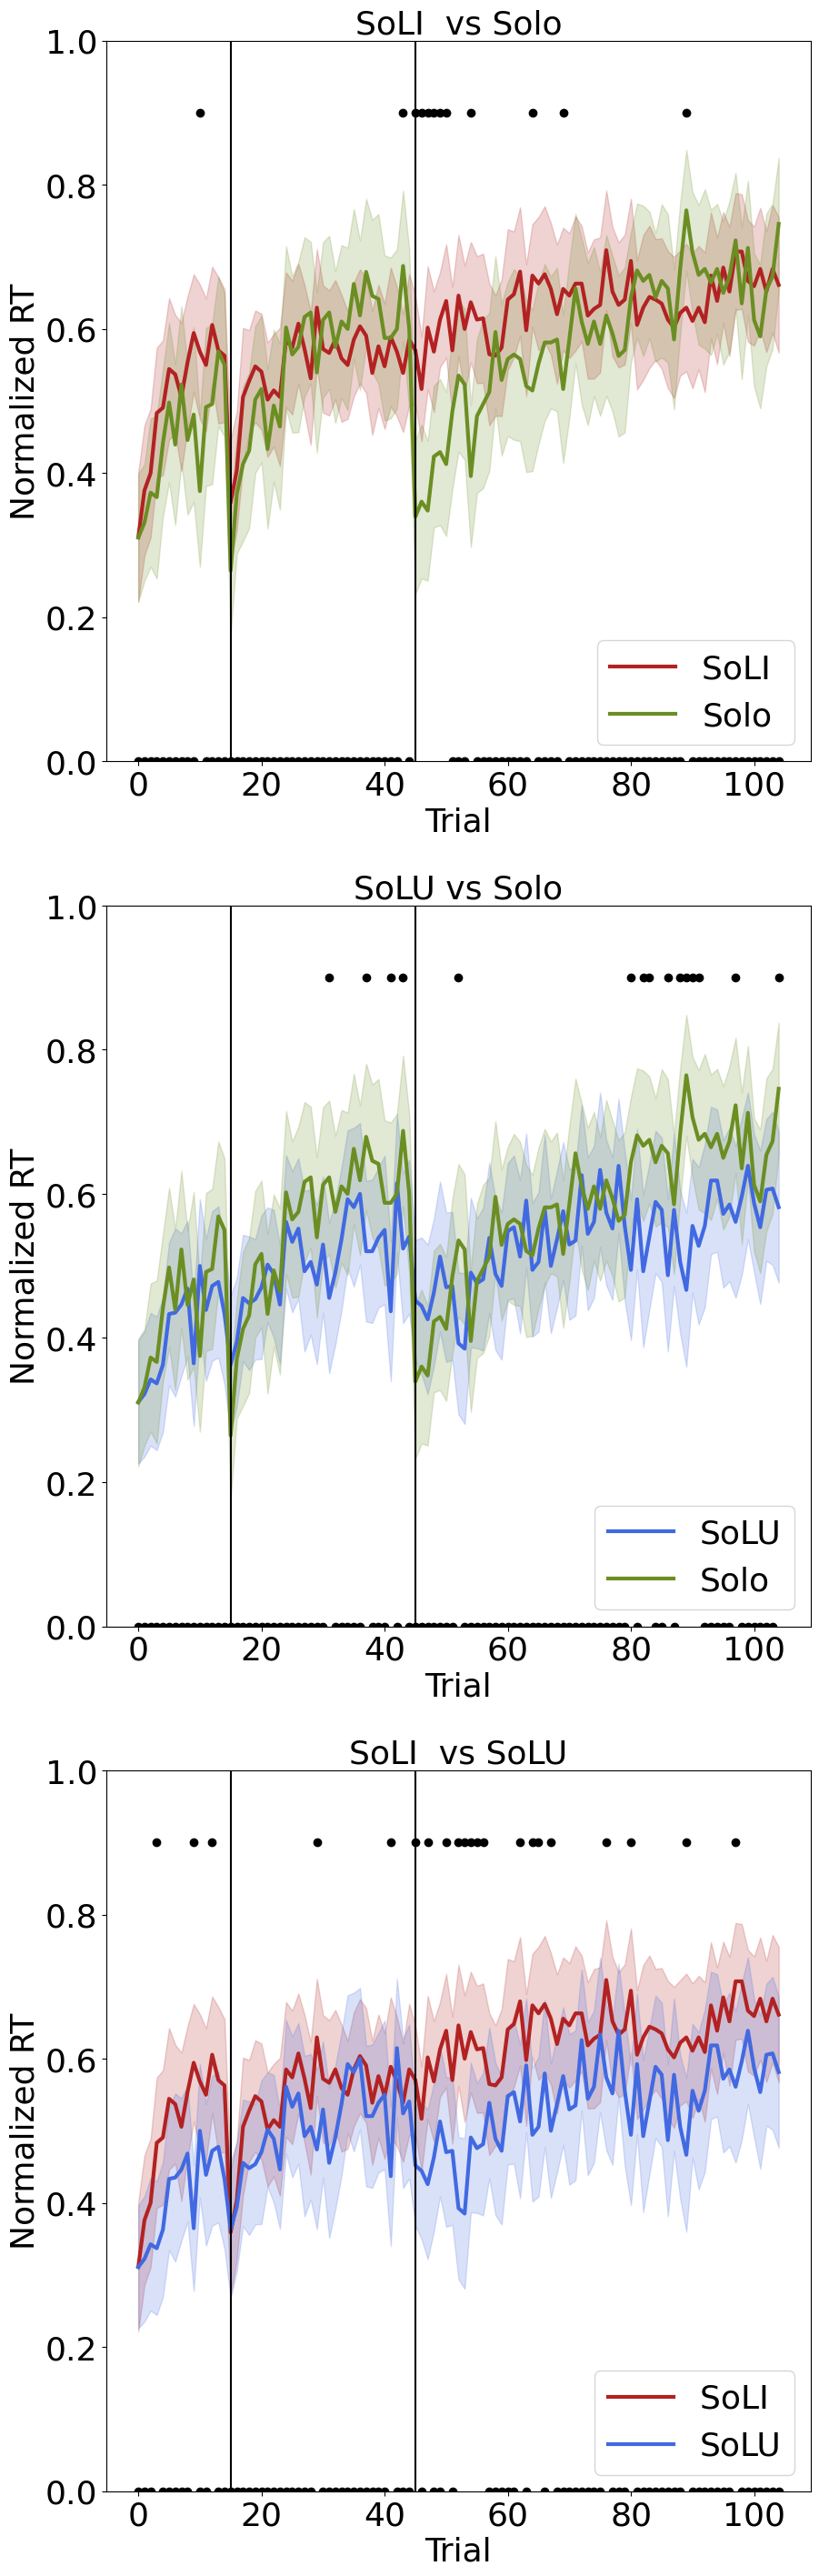

In [92]:
plot_conf(all_conf, g1_len, g2_len, [0, 1], 0.9, 0, 105)


In [93]:
all_rt = get_coloumn(all_sub_df, 'choice_rt', start=0, end=105, normalization=True)

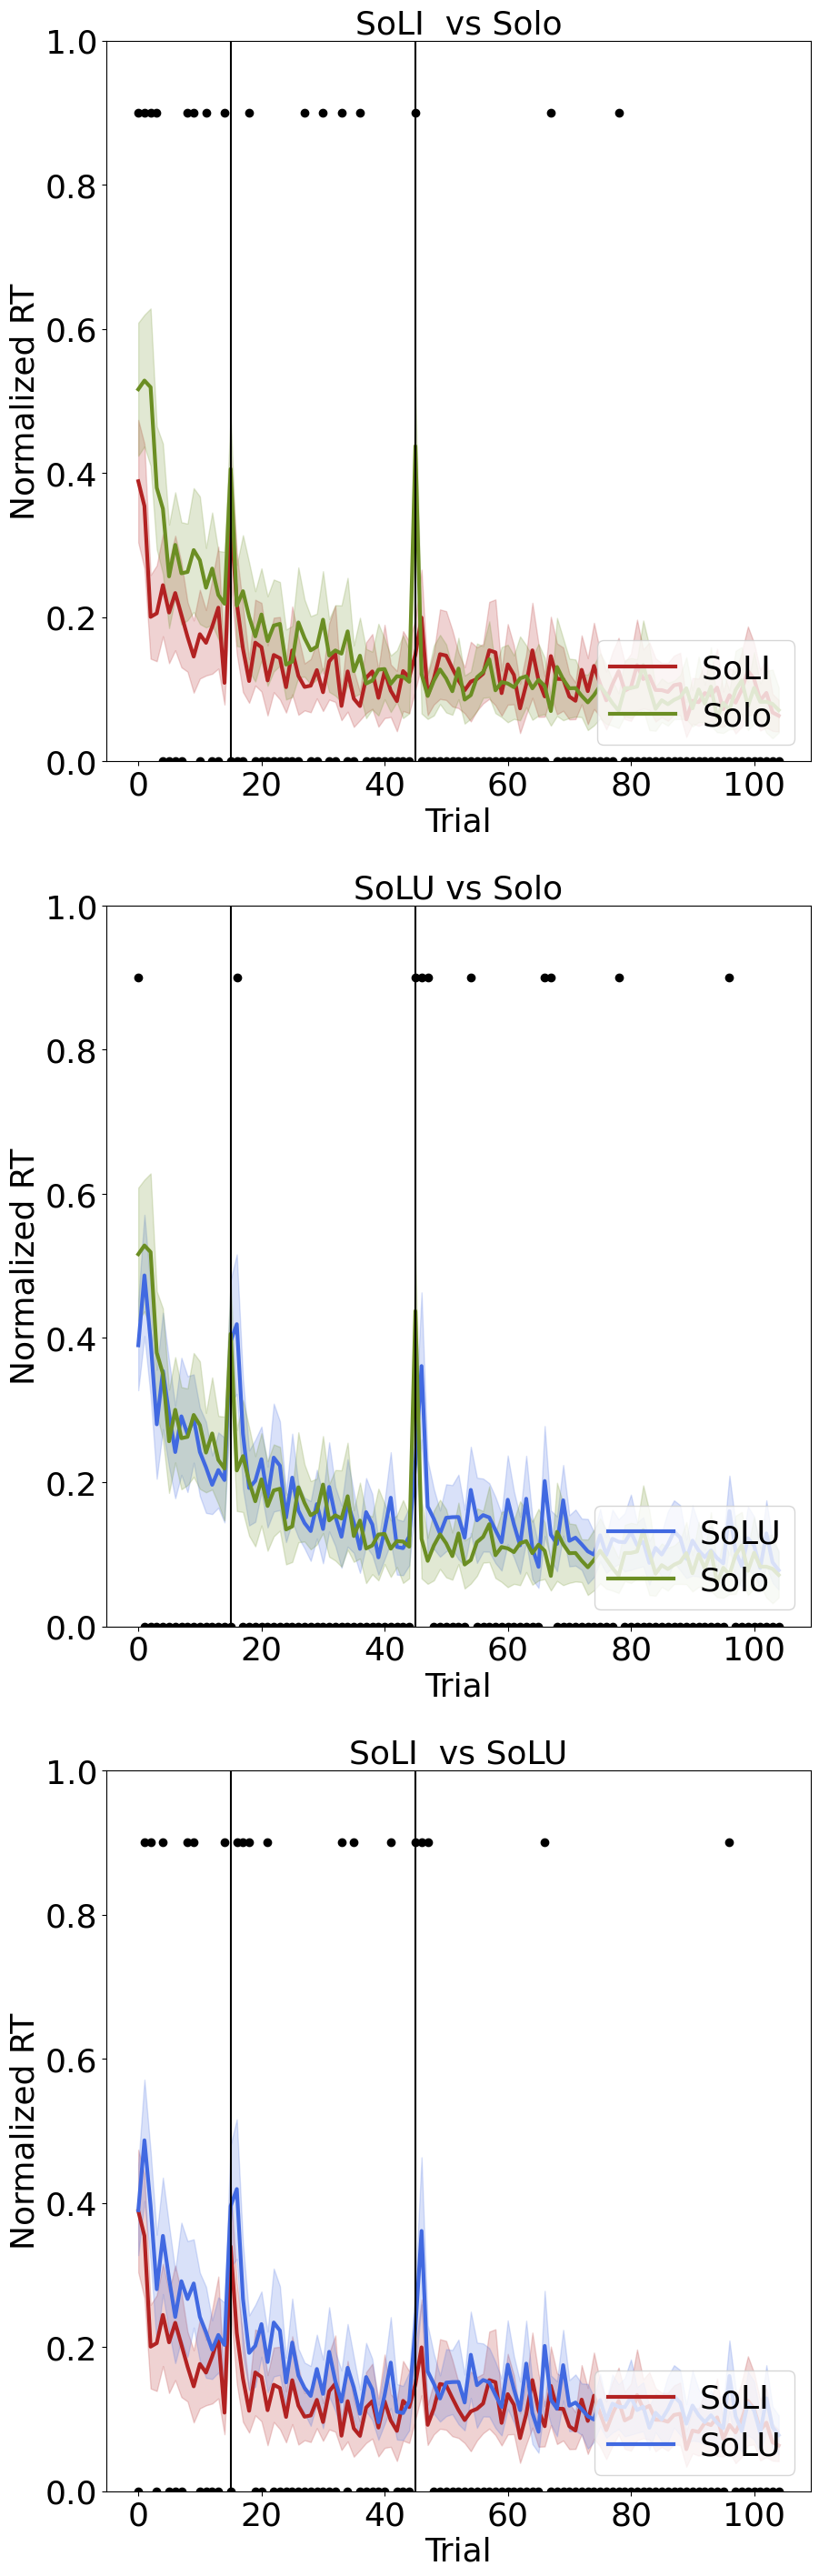

In [94]:
plot_conf(all_rt, g1_len, g2_len, [0, 1], 0.9, 0, 105)

In [95]:
IO_conf_pval, IO_conf_stat, IO_conf_sig = all_trials_ttest(all_conf, 0, g1_len, g1_len + g2_len, 130, 0, 105)
UO_conf_pval, UO_conf_stat, UO_conf_sig = all_trials_ttest(all_conf, g1_len, g1_len + g2_len, g1_len + g2_len, 130, 0, 105)
IU_conf_pval, IU_conf_stat, IU_conf_sig = all_trials_ttest(all_conf, 0, g1_len, g1_len, g1_len + g2_len, 0, 105)

Conf drop

In [96]:
soli_conf = all_conf[0:45]
solu_conf = all_conf[45:90]
solo_conf = all_conf[90:]

In [97]:
soli_conf[0].shape

(105,)

In [98]:
soli_b1_drop = []
soli_b2_drop = []
solu_b1_drop = []
solu_b2_drop = []
solo_b1_drop = []
solo_b2_drop = []
for idx in range(45):
    soli_b1_drop.append(soli_conf[idx][14] - soli_conf[idx][15])
    soli_b2_drop.append(soli_conf[idx][44] - soli_conf[idx][45])
    solu_b1_drop.append(solu_conf[idx][14] - solu_conf[idx][15])
    solu_b2_drop.append(solu_conf[idx][44] - solu_conf[idx][45])
soli_b1_drop = np.array(soli_b1_drop)
soli_b2_drop = np.array(soli_b2_drop)   
solu_b1_drop = np.array(solu_b1_drop)
solu_b2_drop = np.array(solu_b2_drop)

for idx in range(40):
    solo_b1_drop.append(solo_conf[idx][14] - solo_conf[idx][15])
    solo_b2_drop.append(solo_conf[idx][44] - solo_conf[idx][45])
solo_b1_drop = np.array(solo_b1_drop)
solo_b2_drop = np.array(solo_b2_drop) 

## Omnibus analysis of confidence change at the Block 2–3 transition

In [99]:
# ============================================================
# Omnibus test of Block 2 -> Block 3 confidence change
# ============================================================


from scipy.stats import f_oneway, levene, shapiro

confidence_drop_df = pd.DataFrame({
    'confidence_drop': np.concatenate([
        soli_b2_drop,
        solu_b2_drop,
        solo_b2_drop
    ]),
    'group': (
        ['SoLI'] * len(soli_b2_drop)
        + ['SoLU'] * len(solu_b2_drop)
        + ['Solo'] * len(solo_b2_drop)
    )
})

print("Descriptive statistics")
print(
    confidence_drop_df
    .groupby('group')['confidence_drop']
    .agg(['count', 'mean', 'std', 'median'])
)

Descriptive statistics
       count      mean       std  median
group                                   
SoLI      45  0.014815  0.335828    0.00
SoLU      45  0.088889  0.392641    0.00
Solo      40  0.260417  0.414390    0.25


In [100]:
# ============================================================
# Assumption checks
# ============================================================

print("\nShapiro-Wilk tests")
print("------------------")

for group_name, values in [
    ('SoLI', soli_b2_drop),
    ('SoLU', solu_b2_drop),
    ('Solo', solo_b2_drop)
]:
    shapiro_result = shapiro(values)

    print(
        f"{group_name}: "
        f"W = {shapiro_result.statistic:.4f}, "
        f"p = {shapiro_result.pvalue:.6f}"
    )


levene_result = levene(
    soli_b2_drop,
    solu_b2_drop,
    solo_b2_drop
)

print("\nLevene's test")
print("-------------")

print(
    f"F = {levene_result.statistic:.4f}, "
    f"p = {levene_result.pvalue:.6f}"
)


Shapiro-Wilk tests
------------------
SoLI: W = 0.9282, p = 0.008085
SoLU: W = 0.9416, p = 0.024589
Solo: W = 0.9402, p = 0.035034

Levene's test
-------------
F = 2.0035, p = 0.139101


In [101]:
# ============================================================
# Omnibus one-way ANOVA
# ============================================================

anova_result = f_oneway(
    soli_b2_drop,
    solu_b2_drop,
    solo_b2_drop
)

df_between = 2

df_within = (
    len(soli_b2_drop)
    + len(solu_b2_drop)
    + len(solo_b2_drop)
    - 3
)

print("\nOmnibus ANOVA")
print("-------------")

print(
    f"F({df_between}, {df_within}) = "
    f"{anova_result.statistic:.4f}, "
    f"p = {anova_result.pvalue:.6f}"
)


Omnibus ANOVA
-------------
F(2, 127) = 4.5726, p = 0.012089


In [102]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

comparisons = [
    (
        'SoLI vs Solo',
        soli_b2_drop,
        solo_b2_drop
    ),
    (
        'SoLU vs Solo',
        solu_b2_drop,
        solo_b2_drop
    ),
    (
        'SoLI vs SoLU',
        soli_b2_drop,
        solu_b2_drop
    )
]

pairwise_rows = []

for name, x, y in comparisons:

    test = ttest_ind(
        x,
        y,
        equal_var=True
    )

    df = len(x) + len(y) - 2

    pairwise_rows.append({
        'comparison': name,
        'mean_group_1': np.mean(x),
        'mean_group_2': np.mean(y),
        'mean_difference': np.mean(x) - np.mean(y),
        't': test.statistic,
        'df': df,
        'p_raw': test.pvalue
    })

pairwise_results = pd.DataFrame(
    pairwise_rows
)

pairwise_results['p_holm'] = multipletests(
    pairwise_results['p_raw'],
    method='holm'
)[1]

pairwise_results

,comparison,mean_group_1,mean_group_2,mean_difference,t,df,p_raw,p_holm
0,SoLI vs Solo,0.014815,0.260417,-0.245602,-3.015501,83,0.003404,0.010211
1,SoLU vs Solo,0.088889,0.260417,-0.171528,-1.958616,83,0.053516,0.107032
2,SoLI vs SoLU,0.014815,0.088889,-0.074074,-0.961745,88,0.338813,0.338813


In [103]:
# ============================================================
# Eta-squared effect size
# ============================================================

grand_mean = confidence_drop_df['confidence_drop'].mean()

ss_between = 0

for _, group_df in confidence_drop_df.groupby('group'):

    ss_between += (
        len(group_df)
        *
        (
            group_df['confidence_drop'].mean()
            - grand_mean
        ) ** 2
    )

ss_total = np.sum(
    (
        confidence_drop_df['confidence_drop']
        - grand_mean
    ) ** 2
)

eta_squared = ss_between / ss_total

print(
    f"Eta squared (η²) = {eta_squared:.4f}"
)

Eta squared (η²) = 0.0672


In [104]:
# ============================================================
# Confidence trajectory across early, middle, and late Block 3
# ============================================================

confidence_phase_rows = []

g3_start = g1_len + g2_len

for subject_id in range(all_conf.shape[0]):

    if subject_id < g1_len:
        group = 'SoLI'

    elif subject_id < g3_start:
        group = 'SoLU'

    else:
        group = 'Solo'

    # Global trials:
    # Early  = 46-60
    # Middle = 61-80
    # Late   = 81-105

    early_conf = np.mean(
        all_conf[subject_id, 45:60]
    )

    middle_conf = np.mean(
        all_conf[subject_id, 60:80]
    )

    late_conf = np.mean(
        all_conf[subject_id, 80:105]
    )

    confidence_phase_rows.append({
        'subject_id': subject_id,
        'group': group,
        'early_confidence': early_conf,
        'middle_confidence': middle_conf,
        'late_confidence': late_conf,
        'late_minus_middle':
            late_conf - middle_conf
    })


confidence_phase_df = pd.DataFrame(
    confidence_phase_rows
)


print(
    confidence_phase_df
    .groupby('group')[
        [
            'early_confidence',
            'middle_confidence',
            'late_confidence',
            'late_minus_middle'
        ]
    ]
    .agg(['mean', 'std'])
)

      early_confidence           middle_confidence           late_confidence  \
                  mean       std              mean       std            mean   
group                                                                          
SoLI          0.592840  0.155617          0.649907  0.203413        0.649481   
SoLU          0.464444  0.246110          0.557407  0.230230        0.563556   
Solo          0.457639  0.215503          0.575000  0.214264        0.669917   

                late_minus_middle            
            std              mean       std  
group                                        
SoLI   0.202111         -0.000426  0.145965  
SoLU   0.252016          0.006148  0.122871  
Solo   0.171981          0.094917  0.156625  


In [105]:
from scipy.stats import f_oneway

soli_late_change = (
    confidence_phase_df.loc[
        confidence_phase_df['group'] == 'SoLI',
        'late_minus_middle'
    ].values
)

solu_late_change = (
    confidence_phase_df.loc[
        confidence_phase_df['group'] == 'SoLU',
        'late_minus_middle'
    ].values
)

solo_late_change = (
    confidence_phase_df.loc[
        confidence_phase_df['group'] == 'Solo',
        'late_minus_middle'
    ].values
)


late_change_anova = f_oneway(
    soli_late_change,
    solu_late_change,
    solo_late_change
)

print(
    f"F(2, 127) = "
    f"{late_change_anova.statistic:.4f}, "
    f"p = {late_change_anova.pvalue:.6f}"
)

F(2, 127) = 5.8486, p = 0.003718


In [106]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

comparisons = [
    (
        'SoLI vs Solo',
        soli_late_change,
        solo_late_change
    ),
    (
        'SoLU vs Solo',
        solu_late_change,
        solo_late_change
    ),
    (
        'SoLI vs SoLU',
        soli_late_change,
        solu_late_change
    )
]

rows = []

for name, x, y in comparisons:

    result = ttest_ind(
        x,
        y,
        equal_var=True
    )

    rows.append({
        'comparison': name,
        'mean_1': np.mean(x),
        'mean_2': np.mean(y),
        'difference':
            np.mean(x) - np.mean(y),
        't': result.statistic,
        'df': len(x) + len(y) - 2,
        'p_raw': result.pvalue
    })


late_change_pairwise = pd.DataFrame(
    rows
)

late_change_pairwise[
    'p_holm'
] = multipletests(
    late_change_pairwise['p_raw'],
    method='holm'
)[1]

late_change_pairwise

,comparison,mean_1,mean_2,difference,t,df,p_raw,p_holm
0,SoLI vs Solo,-0.000426,0.094917,-0.095343,-2.904303,83,0.004715,0.013398
1,SoLU vs Solo,0.006148,0.094917,-0.088769,-2.923025,83,0.004466,0.013398
2,SoLI vs SoLU,-0.000426,0.006148,-0.006574,-0.231138,88,0.817744,0.817744


In [107]:
values = np.concatenate([
    soli_late_change,
    solu_late_change,
    solo_late_change
])

grand_mean = np.mean(values)

ss_between = (
    len(soli_late_change)
    *
    (np.mean(soli_late_change) - grand_mean)**2
    +
    len(solu_late_change)
    *
    (np.mean(solu_late_change) - grand_mean)**2
    +
    len(solo_late_change)
    *
    (np.mean(solo_late_change) - grand_mean)**2
)

ss_total = np.sum(
    (values - grand_mean)**2
)

eta_squared = ss_between / ss_total

print(
    f"Eta squared = {eta_squared:.4f}"
)

Eta squared = 0.0843


## Prospective confidence and metacognition

In [108]:
from pathlib import Path
import zipfile, io, re, ast, unicodedata
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import roc_auc_score
import statsmodels.api as sm
from statsmodels.discrete.conditional_models import ConditionalLogit

BASE = Path.cwd()
DATA_ZIP = BASE / 'data(2).zip'

# When running the .py from another working directory,
# locate data beside the script.
if not DATA_ZIP.exists() and '__file__' in globals():
    DATA_ZIP = Path(__file__).resolve().parent / 'data(2).zip'

if not DATA_ZIP.exists():
    raise FileNotFoundError(
        'Put data(2).zip next to this script/notebook, '
        'or set DATA_ZIP above.'
    )

OUTPUT = DATA_ZIP.parent / 'metacognition_results'
OUTPUT.mkdir(parents=True, exist_ok=True)

GROUP_FOLDERS = {
    'SoLI': 'trained/4 arm/',
    'SoLU': 'not trained/4 arm/',
    'Solo': 'base-line/4 arm/'
}

ROLE_NAMES = ['Best', 'Second', 'Random']


def decode_role(label, agent_map):
    raw = ''.join(
        ch for ch in unicodedata.normalize('NFKD', str(label))
        if not unicodedata.combining(ch)
    ).strip().lower()

    if raw in ('a', 'b', 'c'):
        return ROLE_NAMES[agent_map['abc'.index(raw)]]

    if raw in ('no agent', 'no_agent', 'none'):
        return 'None'

    if raw == '-':
        return 'Missing'

    raise ValueError(f'Unknown agent label {label!r}')


def private_q_before_trial(data, trial):
    """
    Descriptive private reward-based card-value proxy from
    PRIOR Block-3 data only.

    Four independent Beta(1,1) priors.
    NOT the fitted social RL Q-values.
    """
    successes = np.ones(4)
    attempts = np.ones(4)

    for past_t in range(45, trial):
        card = int(data['choice'].iat[past_t])
        attempts[card] += 1
        successes[card] += (
            str(data['outcome'].iat[past_t])
            .strip()
            .lower() == 'win'
        )

    return successes / (attempts + 1)


selection_rows = []
monitoring_rows = []
choice_rows = []

with zipfile.ZipFile(DATA_ZIP) as archive:

    for group, folder in GROUP_FOLDERS.items():

        members = sorted(
            [
                p for p in archive.namelist()
                if p.startswith(folder) and p.endswith('.csv')
            ],
            key=lambda p: int(
                re.search(r'subject(\d+)', p).group(1)
            )
        )

        print(f'{group}: {len(members)} participants')

        for index, filename in enumerate(members, start=1):

            d = pd.read_csv(
                io.BytesIO(archive.read(filename))
            )

            assert len(d) == 105
            assert np.array_equal(
                d['trial'].to_numpy(),
                np.arange(105)
            ), filename

            subject = f'{group}_{index:02d}'

            cards = d['choice'].astype(int).to_numpy()

            reward = (
                d['outcome']
                .astype(str)
                .str.strip()
                .str.lower() == 'win'
            ).astype(int).to_numpy()

            confidence = (
                d['confidence_level']
                .astype(float)
                .to_numpy()
            )

            probabilities = np.array(
                [
                    ast.literal_eval(s)
                    for s in d['card probs']
                ],
                dtype=float
            )

            optimal_card = np.argmax(
                probabilities,
                axis=1
            )

            # [C] Participant-level metacognitive monitoring.
            # Use Block 3.

            acc = (
                cards[45:105] == optimal_card[45:105]
            ).astype(int)

            conf_b3 = confidence[45:105]

            if (
                len(np.unique(acc)) < 2
                or len(np.unique(conf_b3)) < 2
            ):
                auc = np.nan
            else:
                auc = roc_auc_score(acc, conf_b3)

            monitoring_rows.append(
                dict(
                    subject=subject,
                    group=group,
                    auc=auc
                )
            )

            # [D] Non-greedy behavior using only
            # preceding private reward history.

            for t in range(45, 105):

                private_q = private_q_before_trial(d, t)

                unique_best = int(
                    np.sum(
                        np.isclose(
                            private_q,
                            private_q.max()
                        )
                    ) == 1
                )

                choice_rows.append(
                    dict(
                        subject=subject,
                        group=group,
                        trial=t,
                        conf_prior=confidence[t-1],
                        private_unique=unique_best,
                        nongreedy=int(
                            private_q[cards[t]]
                            < private_q.max() - 1e-12
                        ),
                        q_gap=(
                            np.sort(private_q)[-1]
                            - np.sort(private_q)[-2]
                        ),
                        win_prior=reward[t-1]
                    )
                )

            if group == 'Solo':
                continue

            agent_map = ast.literal_eval(
                d['agent types'].iat[45]
            )

            assert sorted(agent_map) == [0, 1, 2]

            # Twenty selection opportunities in Block 3.

            for k in range(1, 21):

                t = 45 + 3 * (k - 1)

                agent = decode_role(
                    d['chosen_agent'].iat[t],
                    agent_map
                )

                if k == 1:
                    prev = 'Missing'
                else:
                    prev = decode_role(
                        d['chosen_agent'].iat[t-3],
                        agent_map
                    )

                private_q = private_q_before_trial(d, t)

                selection_rows.append(
                    dict(
                        subject=subject,
                        group=group,
                        is_solu=int(group == 'SoLU'),
                        opp=k,
                        best=int(agent == 'Best'),
                        seek=int(agent != 'None'),
                        conf_last=confidence[t-1],
                        conf_mean3=confidence[t-3:t].mean(),
                        recent_reward3=reward[t-3:t].mean(),
                        q_topgap=(
                            np.sort(private_q)[-1]
                            - np.sort(private_q)[-2]
                        ),
                        prev_best=int(prev == 'Best'),
                        prev_seek=int(
                            prev not in ('Missing', 'None')
                        )
                    )
                )


selection = pd.DataFrame(selection_rows)
monitoring = pd.DataFrame(monitoring_rows)
choices = pd.DataFrame(choice_rows)

# Exclude the first social-selection opportunity in Block 3:
# its preceding confidence rating was recorded in Block 2.

selection = selection.query('opp >= 2').copy()

selection['opp_c'] = (
    selection['opp'] - 2
) / 18

# Separate within-person and between-person confidence.

for col in ('conf_last', 'conf_mean3'):

    selection[col + '_within'] = (
        selection[col]
        - selection.groupby('subject')[col].transform('mean')
    )

    selection[col + '_between'] = (
        selection.groupby('subject')[col].transform('mean')
    )

choices['conf_prior_within'] = (
    choices['conf_prior']
    - choices.groupby('subject')['conf_prior'].transform('mean')
)

choices['conf_prior_between'] = (
    choices.groupby('subject')['conf_prior'].transform('mean')
)

assert len(selection) == 1710
assert selection['subject'].nunique() == 90


def gee_binomial(frame, formula, filename):
    """
    Population-averaged binomial GEE with
    subject-clustered robust uncertainty.
    """

    fitted = sm.GEE.from_formula(
        formula,
        groups='subject',
        data=frame,
        family=sm.families.Binomial(),
        cov_struct=sm.cov_struct.Exchangeable()
    ).fit(maxiter=150)

    ci = fitted.conf_int()

    table = pd.DataFrame({
        'term': fitted.params.index,
        'beta': fitted.params.values,
        'robust_SE': fitted.bse.values,
        'p': fitted.pvalues.values,
        'CI_low': ci.iloc[:, 0].values,
        'CI_high': ci.iloc[:, 1].values
    })

    table.to_csv(
        OUTPUT / filename,
        index=False
    )

    print(
        f'\n{filename} '
        f'N={len(frame)}, '
        f'subjects={frame.subject.nunique()}'
    )

    print(
        table.round(5).to_string(index=False)
    )

    return fitted

SoLI: 45 participants
SoLU: 45 participants
Solo: 40 participants


In [109]:
FORMULA_BEST = (
    'best ~ is_solu + conf_last_within + conf_last_within:is_solu '
    '+ conf_last_between + opp_c + recent_reward3 + q_topgap '
    '+ prev_best + prev_seek'
)

best_model = gee_binomial(
    selection,
    FORMULA_BEST,
    '01_best_agent_previous_confidence.csv'
)

print(
    '\nSoLI best-agent confidence OR:',
    round(
        np.exp(best_model.params['conf_last_within']),
        3
    )
)


# Conditional on seeking social information:
# controls for best-vs-none conflation.

best_given_seek = gee_binomial(
    selection.query('seek == 1'),
    FORMULA_BEST,
    '02_best_agent_among_seekers.csv'
)


# Participant fixed-effects check:
# excludes subjects with no variation in 'best'.

fe_frame = selection.copy()

fe_frame['conf_x_solu'] = (
    fe_frame['conf_last_within']
    * fe_frame['is_solu']
)

fe_terms = [
    'conf_last_within',
    'conf_x_solu',
    'opp_c',
    'recent_reward3',
    'q_topgap',
    'prev_best',
    'prev_seek'
]

fe_fit = ConditionalLogit(
    fe_frame['best'],
    fe_frame[fe_terms],
    groups=fe_frame['subject']
).fit(
    disp=False,
    maxiter=160
)

fe_table = pd.DataFrame({
    'beta': fe_fit.params,
    'SE': fe_fit.bse,
    'p': fe_fit.pvalues
})

fe_table.to_csv(
    OUTPUT / '02b_best_agent_participant_fixed_effects.csv'
)

print(
    '\nPARTICIPANT FIXED EFFECTS '
    '(best-agent selection):'
)

print(
    fe_table.round(5).to_string()
)


# Essential sensitivity:
# use mean confidence across previous three decisions,
# instead of confidence immediately before agent selection.

FORMULA_MEAN3 = (
    'best ~ is_solu + conf_mean3_within '
    '+ conf_mean3_within:is_solu '
    '+ conf_mean3_between + opp_c '
    '+ recent_reward3 + q_topgap '
    '+ prev_best + prev_seek'
)

best_three_rating_mean = gee_binomial(
    selection,
    FORMULA_MEAN3,
    '03_best_agent_three_rating_mean_sensitivity.csv'
)


01_best_agent_previous_confidence.csv N=1710, subjects=90
                    term     beta  robust_SE       p   CI_low  CI_high
               Intercept -2.60279    0.59343 0.00001 -3.76590 -1.43968
                 is_solu -0.24255    0.24539 0.32294 -0.72351  0.23840
        conf_last_within  0.18021    0.05750 0.00173  0.06750  0.29291
conf_last_within:is_solu -0.16574    0.08948 0.06398 -0.34111  0.00963
       conf_last_between  0.34541    0.15801 0.02881  0.03572  0.65510
                   opp_c -0.11625    0.17859 0.51507 -0.46629  0.23378
          recent_reward3 -0.08222    0.17229 0.63319 -0.41991  0.25546
                q_topgap  0.76314    0.70101 0.27632 -0.61082  2.13709
               prev_best  0.36854    0.18096 0.04169  0.01386  0.72321
               prev_seek  0.85205    0.22258 0.00013  0.41579  1.28830

SoLI best-agent confidence OR: 1.197

02_best_agent_among_seekers.csv N=1437, subjects=88
                    term     beta  robust_SE       p   CI_low  CI_hig

c:\Users\AsusIran\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\discrete\conditional_models.py:80: UserWarning: Dropped 18 groups and 342 observations for having no within-group variance
  warnings.warn(msg)



PARTICIPANT FIXED EFFECTS (best-agent selection):
                     beta       SE        p
conf_last_within  0.24439  0.09637  0.01121
conf_x_solu      -0.22696  0.13489  0.09245
opp_c            -0.19610  0.21419  0.35990
recent_reward3   -0.05846  0.23885  0.80664
q_topgap          1.05249  0.83356  0.20672
prev_best         0.07226  0.14653  0.62190
prev_seek         1.00094  0.26691  0.00018

03_best_agent_three_rating_mean_sensitivity.csv N=1710, subjects=90
                     term     beta  robust_SE       p   CI_low  CI_high
                Intercept -2.80012    0.68862 0.00005 -4.14978 -1.45045
                  is_solu -0.27510    0.24354 0.25865 -0.75244  0.20223
        conf_mean3_within  0.11648    0.08833 0.18725 -0.05664  0.28960
conf_mean3_within:is_solu  0.00532    0.14561 0.97085 -0.28007  0.29071
       conf_mean3_between  0.39759    0.19092 0.03730  0.02339  0.77180
                    opp_c -0.13343    0.18168 0.46270 -0.48951  0.22266
           recent_reward

In [110]:
monitoring_results = []

rng = np.random.default_rng(1519)

for group in ('SoLI', 'SoLU', 'Solo'):

    subset = monitoring.loc[
        monitoring['group'] == group,
        'auc'
    ].dropna().to_numpy()

    p_one_sided = wilcoxon(
        subset - 0.5,
        alternative='greater'
    ).pvalue

    bootstrap_means = np.array([
        rng.choice(
            subset,
            size=len(subset),
            replace=True
        ).mean()
        for _ in range(6000)
    ])

    low, high = np.quantile(
        bootstrap_means,
        [0.025, 0.975]
    )

    monitoring_results.append(
        dict(
            group=group,
            valid_subjects=len(subset),
            mean_AUC=subset.mean(),
            bootstrap95_low=low,
            bootstrap95_high=high,
            p_one_sided=p_one_sided
        )
    )

monitoring_results = pd.DataFrame(
    monitoring_results
)

monitoring_results.to_csv(
    OUTPUT / '04_confidence_monitoring_AUC.csv',
    index=False
)

print(
    '\nBLOCK-3 METACOGNITIVE MONITORING '
    '(not causal regulation):'
)

print(
    monitoring_results.round(5).to_string(index=False)
)


BLOCK-3 METACOGNITIVE MONITORING (not causal regulation):
group  valid_subjects  mean_AUC  bootstrap95_low  bootstrap95_high  p_one_sided
 SoLI              45   0.60151          0.54548           0.65624      0.00012
 SoLU              44   0.57764          0.51912           0.63245      0.00249
 Solo              40   0.56451          0.49609           0.63324      0.02654


In [111]:
private_trials = choices.query(
    'trial >= 55 and private_unique == 1'
).copy()

private_trials['soli'] = (
    private_trials.group == 'SoLI'
).astype(int)

private_trials['solu'] = (
    private_trials.group == 'SoLU'
).astype(int)

private_trials['trial_center'] = (
    private_trials.trial - 55
) / 49

assert len(private_trials) == 6183

private_model = gee_binomial(
    private_trials,
    'nongreedy ~ conf_prior_within + conf_prior_between '
    '+ soli + solu + trial_center + q_gap + win_prior',
    '05_confidence_predicts_private_nongreedy.csv'
)

print(
    '\nPrivate non-greedy choice OR:',
    round(
        np.exp(
            private_model.params['conf_prior_within']
        ),
        3
    )
)

print(
    '\nCAVEATS: Prospective observational associations only; '
    'no causal confidence manipulation.'
)

print(
    'The SoLI vs SoLU confidence-slope interaction and '
    'the 3-rating sensitivity may be nonsignificant.'
)

print(
    'Best-agent selection is exploratory; include its '
    'sensitivity qualification in any manuscript.'
)

print('Output:', OUTPUT)


05_confidence_predicts_private_nongreedy.csv N=6183, subjects=130
              term     beta  robust_SE       p   CI_low  CI_high
         Intercept  1.30858    0.38779 0.00074  0.54853  2.06864
 conf_prior_within -0.15597    0.03627 0.00002 -0.22706 -0.08489
conf_prior_between -0.17878    0.10582 0.09113 -0.38619  0.02863
              soli  0.16511    0.20022 0.40958 -0.22732  0.55754
              solu  0.17755    0.20085 0.37671 -0.21611  0.57120
      trial_center -0.24422    0.12766 0.05575 -0.49444  0.00600
             q_gap -2.83707    0.60737 0.00000 -4.02749 -1.64665
         win_prior -0.29836    0.06314 0.00000 -0.42211 -0.17461

Private non-greedy choice OR: 0.856

CAVEATS: Prospective observational associations only; no causal confidence manipulation.
The SoLI vs SoLU confidence-slope interaction and the 3-rating sensitivity may be nonsignificant.
Best-agent selection is exploratory; include its sensitivity qualification in any manuscript.
Output: d:\University\Univers

# Behavioral figure

In [128]:
behfigdir = 'D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Final version figures/Beh/'

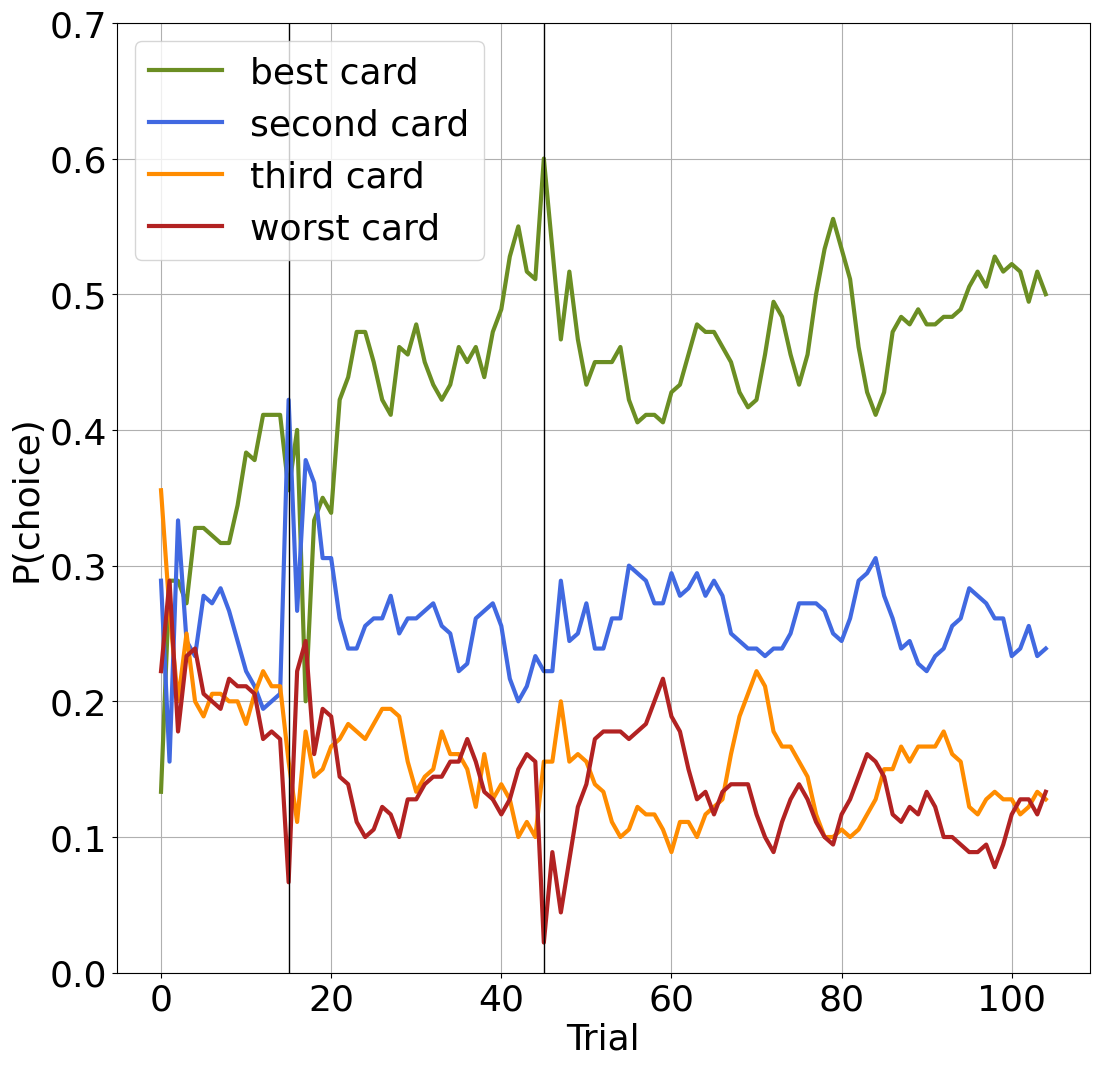

In [138]:

# Probability of choosing cards — SoLI

fig, ax = plt.subplots(figsize=(12, 35/3))

ax.plot(g1_smoothed_best, color='olivedrab', label='best card', linewidth=3)
ax.plot(g1_smoothed_second, color='royalblue', label='second card', linewidth=3)
ax.plot(g1_smoothed_third, color='darkorange', label='third card', linewidth=3)
ax.plot(g1_smoothed_worst, color='firebrick', label='worst card', linewidth=3)

ax.axvline(x=15, color='black', linewidth=1)
ax.axvline(x=45, color='black', linewidth=1)

ax.set_ylim([0, 0.7])
# ax.set_title('SoLI', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('P(choice)', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.grid()
ax.legend(loc=2, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'behavior_SoLI.svg'
fig.savefig(fignam, format='svg')
plt.show()


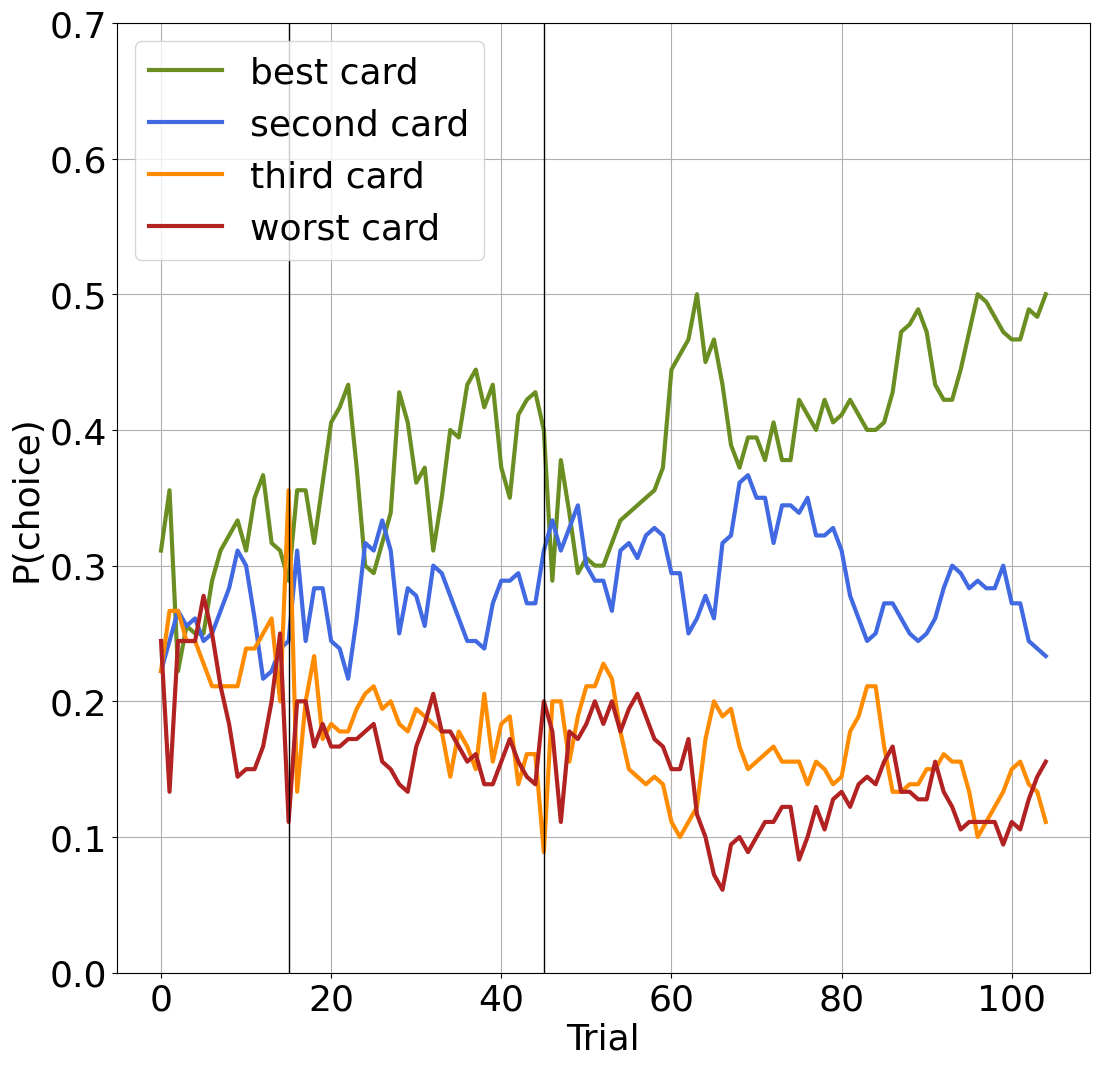

In [139]:

# Probability of choosing cards — SoLU

fig, ax = plt.subplots(figsize=(12, 35/3))

ax.plot(g2_smoothed_best, color='olivedrab', label='best card', linewidth=3)
ax.plot(g2_smoothed_second, color='royalblue', label='second card', linewidth=3)
ax.plot(g2_smoothed_third, color='darkorange', label='third card', linewidth=3)
ax.plot(g2_smoothed_worst, color='firebrick', label='worst card', linewidth=3)

ax.axvline(x=15, color='black', linewidth=1)
ax.axvline(x=45, color='black', linewidth=1)

ax.set_ylim([0, 0.7])
# ax.set_title('SoLU', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('P(choice)', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.grid()
ax.legend(loc=2, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'behavior_SoLU.svg'
fig.savefig(fignam, format='svg')
# fig.savefig('behavior_SoLU.svg', format='svg')
plt.show()


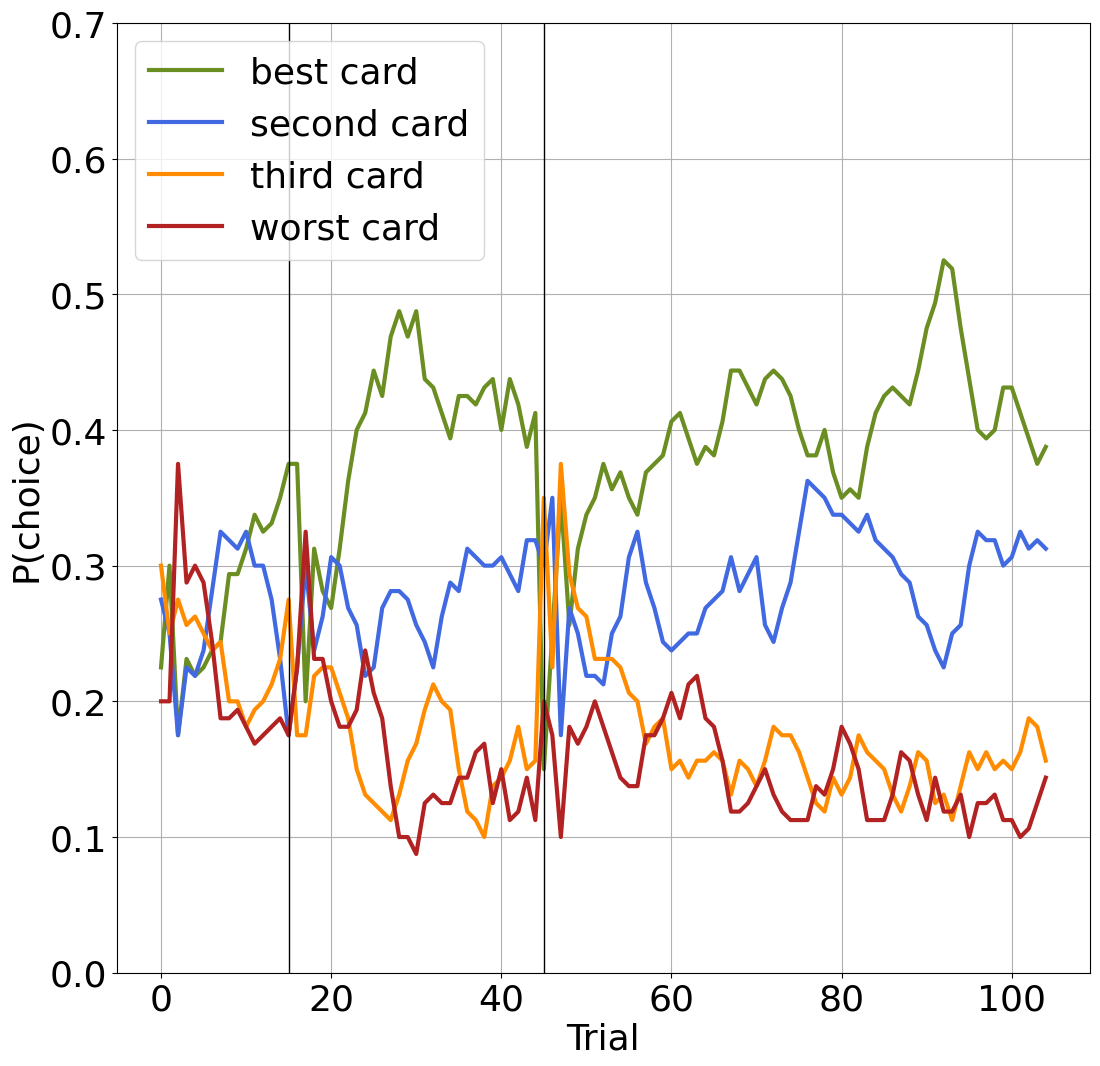

In [140]:

# Probability of choosing cards — Solo

fig, ax = plt.subplots(figsize=(12, 35/3))

ax.plot(g3_smoothed_best, color='olivedrab', label='best card', linewidth=3)
ax.plot(g3_smoothed_second, color='royalblue', label='second card', linewidth=3)
ax.plot(g3_smoothed_third, color='darkorange', label='third card', linewidth=3)
ax.plot(g3_smoothed_worst, color='firebrick', label='worst card', linewidth=3)

ax.axvline(x=15, color='black', linewidth=1)
ax.axvline(x=45, color='black', linewidth=1)

ax.set_ylim([0, 0.7])
# ax.set_title('Solo', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('P(choice)', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.grid()
ax.legend(loc=2, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'behavior_Solo.svg'
fig.savefig(fignam, format='svg')
# fig.savefig('behavior_Solo.svg', format='svg')
plt.show()


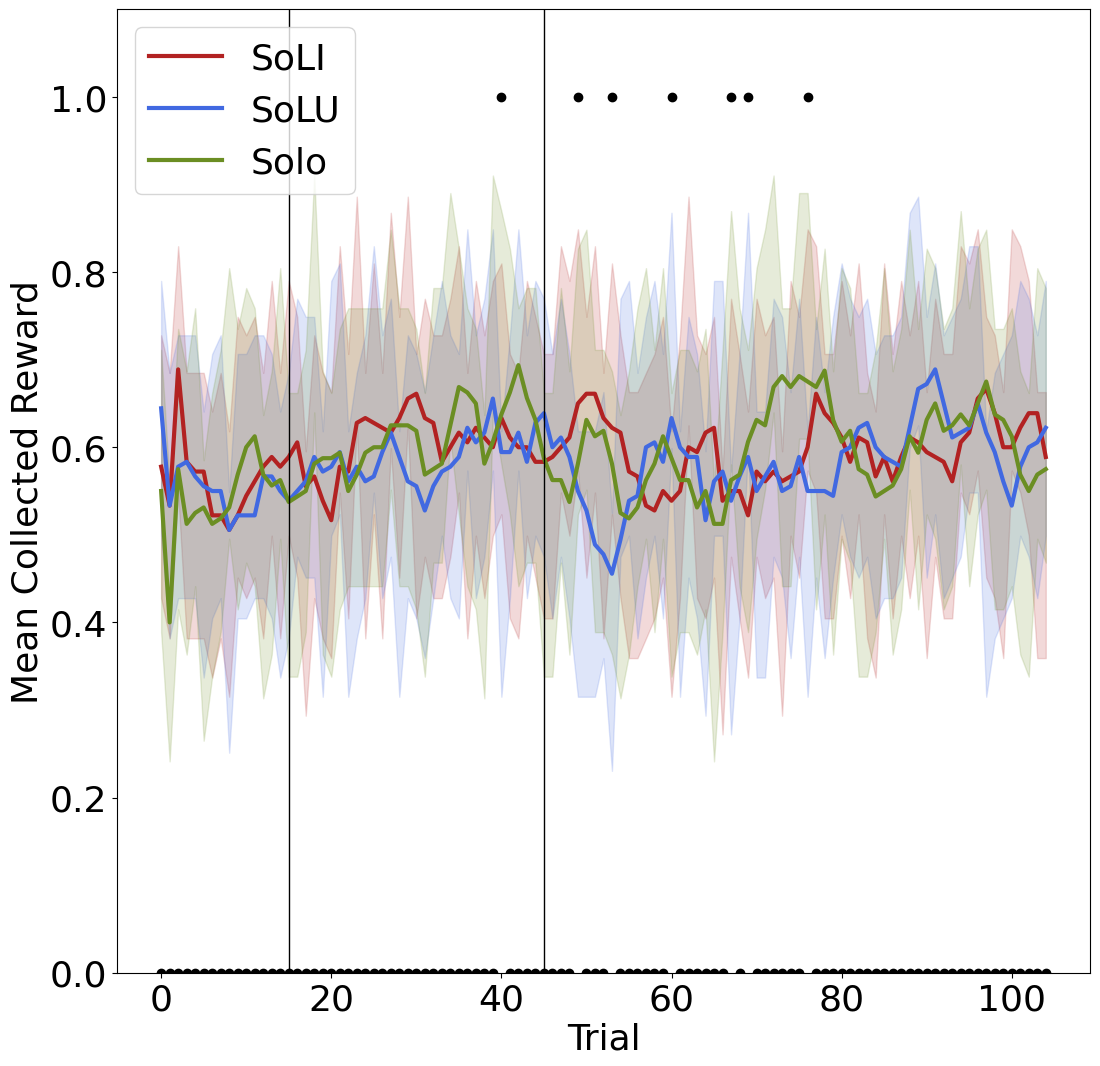

In [142]:

# Mean reward across groups

fig, ax = plt.subplots(figsize=(12, 35/3))

av_trained_rewards = mov_avg(mean_trained_rewards, 4)
av_not_trained_rewards = mov_avg(mean_not_trained_rewards, 4)
av_bl_rewards = mov_avg(mean_bl_rewards, 4)

ax.plot(trained_x, av_trained_rewards, color='firebrick', label='SoLI', linewidth=3)
ax.fill_between(
    trained_x,
    mean_trained_rewards - trained_rewards_cl,
    mean_trained_rewards + trained_rewards_cl,
    color='firebrick', alpha=0.17
)

ax.plot(not_trained_x, av_not_trained_rewards, color='royalblue', label='SoLU', linewidth=3)
ax.fill_between(
    not_trained_x,
    mean_not_trained_rewards - not_trained_rewards_cl,
    mean_not_trained_rewards + not_trained_rewards_cl,
    color='royalblue', alpha=0.17
)

ax.plot(bl_x, av_bl_rewards, color='olivedrab', label='Solo', linewidth=3)
ax.fill_between(
    bl_x,
    mean_bl_rewards - bl_rewards_cl,
    mean_bl_rewards + bl_rewards_cl,
    color='olivedrab', alpha=0.17
)

ax.axvline(x=15, color='black', linewidth=1)
ax.axvline(x=45, color='black', linewidth=1)

x = np.arange(105)
ax.scatter(x, anova_sig, color='black')

ax.set_ylim([0, 1.1])
# ax.set_title('Mean Reward', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('Mean Collected Reward', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.legend(loc=2, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'behavior_mean_reward.svg'
fig.savefig(fignam, format='svg')
# fig.savefig('behavior_mean_reward.svg', format='svg')
plt.show()


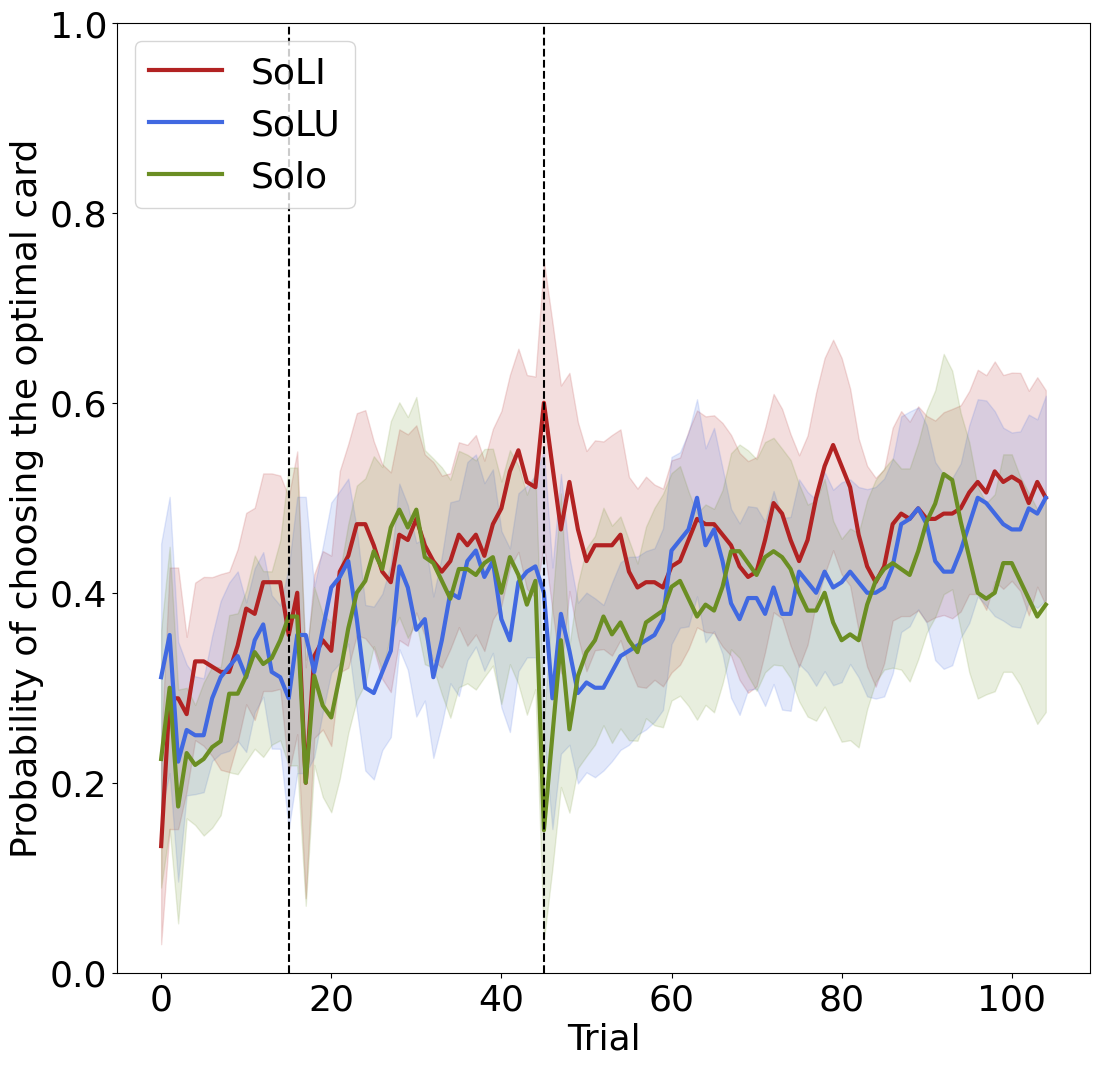

In [143]:

# Optimal-card choice probability across groups

x = np.arange(105)

fig, ax = plt.subplots(figsize=(12, 35/3))

ax.plot(x, soli_mean, label='SoLI', color='firebrick', linewidth=3)
ax.fill_between(
    x,
    soli_mean - soli_ci,
    soli_mean + soli_ci,
    color='firebrick', alpha=0.15
)

ax.plot(x, solu_mean, label='SoLU', color='royalblue', linewidth=3)
ax.fill_between(
    x,
    solu_mean - solu_ci,
    solu_mean + solu_ci,
    color='royalblue', alpha=0.15
)

ax.plot(x, solo_mean, label='Solo', color='olivedrab', linewidth=3)
ax.fill_between(
    x,
    solo_mean - solo_ci,
    solo_mean + solo_ci,
    color='olivedrab', alpha=0.15
)

ax.axvline(x=15, linestyle='--', color='black')
ax.axvline(x=45, linestyle='--', color='black')

ax.set_ylim([0, 1])
# ax.set_title('Optimal-card choice across groups', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('Probability of choosing the optimal card', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.legend(loc=2, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'behavior_optimal_card.svg'
fig.savefig(fignam, format='svg')
# fig.savefig('behavior_optimal_card.svg', format='svg')
plt.show()


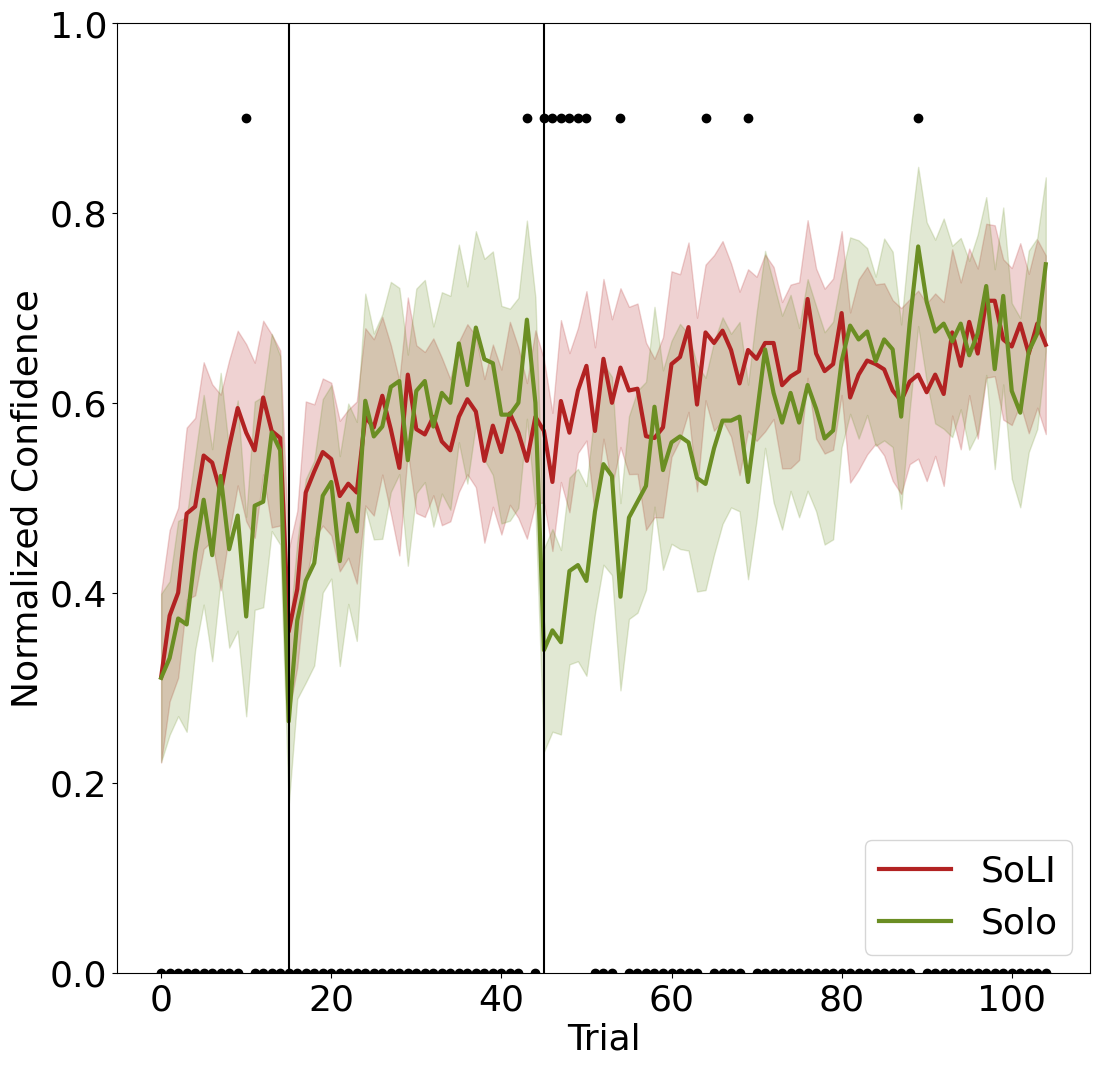

In [144]:

# Confidence — SoLI vs Solo

g3_start = g1_len + g2_len

conf_g1 = all_conf[:g1_len]
conf_g3 = all_conf[g3_start:]

conf_g1_mean = np.mean(conf_g1, axis=0)
conf_g1_sem = scipy.stats.sem(conf_g1, axis=0)
conf_g1_ci = conf_g1_sem * scipy.stats.t.ppf(0.975, conf_g1.shape[0] - 1)

conf_g3_mean = np.mean(conf_g3, axis=0)
conf_g3_sem = scipy.stats.sem(conf_g3, axis=0)
conf_g3_ci = conf_g3_sem * scipy.stats.t.ppf(0.975, conf_g3.shape[0] - 1)

x = np.arange(105)

IO_conf_pval, IO_conf_stat, IO_conf_sig = all_trials_ttest(
    all_conf, 0, g1_len, g3_start, len(all_conf), 0, 105
)

fig, ax = plt.subplots(figsize=(12, 35/3))

ax.plot(x, conf_g1_mean, color='firebrick', label='SoLI', linewidth=3)
ax.fill_between(
    x, conf_g1_mean - conf_g1_ci, conf_g1_mean + conf_g1_ci,
    color='firebrick', alpha=0.2
)

ax.plot(x, conf_g3_mean, color='olivedrab', label='Solo', linewidth=3)
ax.fill_between(
    x, conf_g3_mean - conf_g3_ci, conf_g3_mean + conf_g3_ci,
    color='olivedrab', alpha=0.2
)

ax.axvline(x=15, color='black')
ax.axvline(x=45, color='black')
ax.scatter(x, IO_conf_sig * 0.9, color='black')

ax.set_ylim([0, 1])
# ax.set_title('SoLI vs Solo', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('Normalized Confidence', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.legend(loc=4, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'confidence_SoLI_vs_Solo.svg'
fig.savefig(fignam, format='svg')
# fig.savefig('confidence_SoLI_vs_Solo.svg', format='svg')
plt.show()


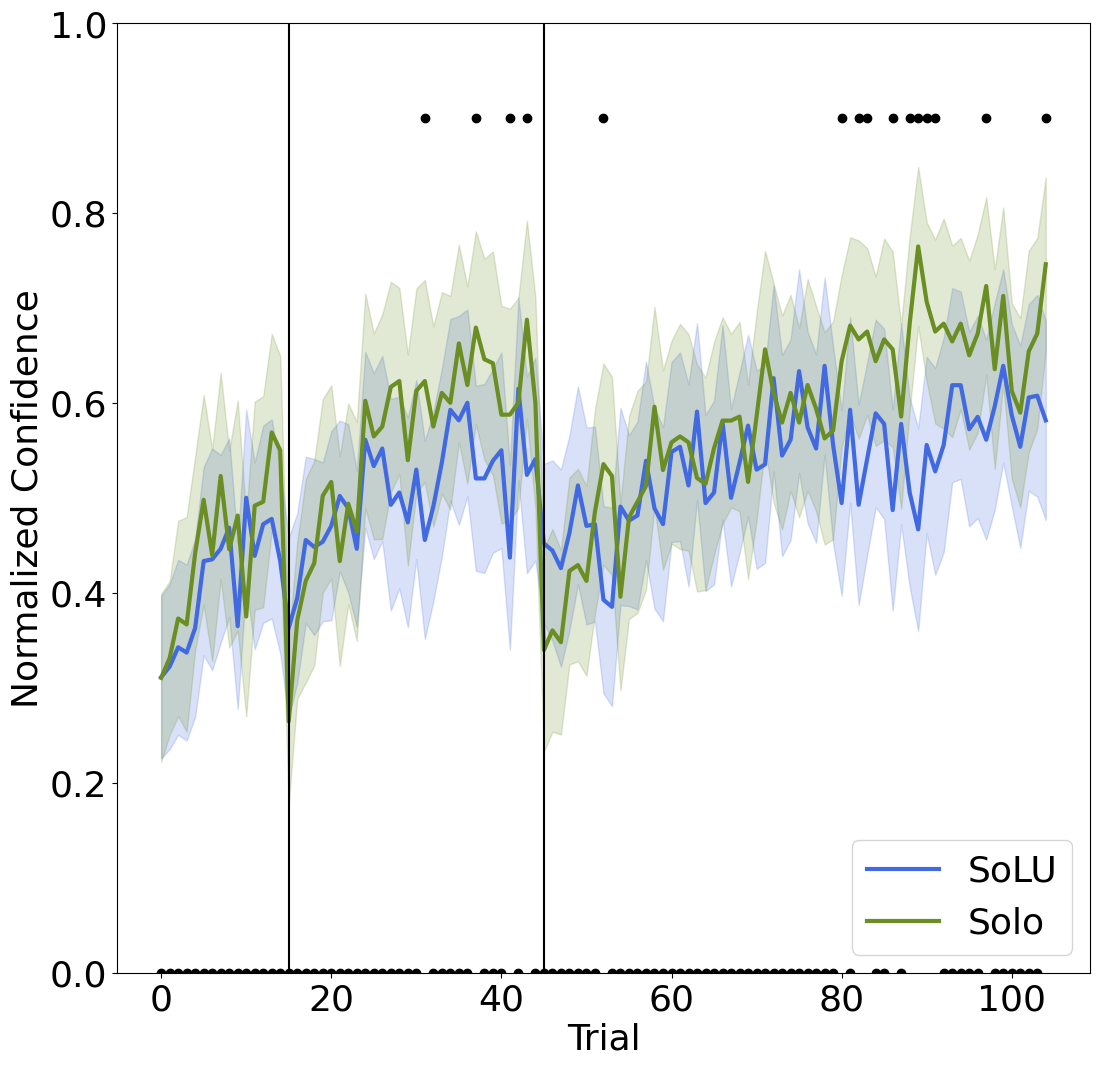

In [145]:

# Confidence — SoLU vs Solo

g3_start = g1_len + g2_len

conf_g2 = all_conf[g1_len:g3_start]
conf_g3 = all_conf[g3_start:]

conf_g2_mean = np.mean(conf_g2, axis=0)
conf_g2_sem = scipy.stats.sem(conf_g2, axis=0)
conf_g2_ci = conf_g2_sem * scipy.stats.t.ppf(0.975, conf_g2.shape[0] - 1)

conf_g3_mean = np.mean(conf_g3, axis=0)
conf_g3_sem = scipy.stats.sem(conf_g3, axis=0)
conf_g3_ci = conf_g3_sem * scipy.stats.t.ppf(0.975, conf_g3.shape[0] - 1)

x = np.arange(105)

UO_conf_pval, UO_conf_stat, UO_conf_sig = all_trials_ttest(
    all_conf, g1_len, g3_start, g3_start, len(all_conf), 0, 105
)

fig, ax = plt.subplots(figsize=(12, 35/3))

ax.plot(x, conf_g2_mean, color='royalblue', label='SoLU', linewidth=3)
ax.fill_between(
    x, conf_g2_mean - conf_g2_ci, conf_g2_mean + conf_g2_ci,
    color='royalblue', alpha=0.2
)

ax.plot(x, conf_g3_mean, color='olivedrab', label='Solo', linewidth=3)
ax.fill_between(
    x, conf_g3_mean - conf_g3_ci, conf_g3_mean + conf_g3_ci,
    color='olivedrab', alpha=0.2
)

ax.axvline(x=15, color='black')
ax.axvline(x=45, color='black')
ax.scatter(x, UO_conf_sig * 0.9, color='black')

ax.set_ylim([0, 1])
# ax.set_title('SoLU vs Solo', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('Normalized Confidence', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.legend(loc=4, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'confidence_SoLU_vs_Solo.svg'
fig.savefig(fignam, format='svg')
# fig.savefig('confidence_SoLU_vs_Solo.svg', format='svg')
plt.show()


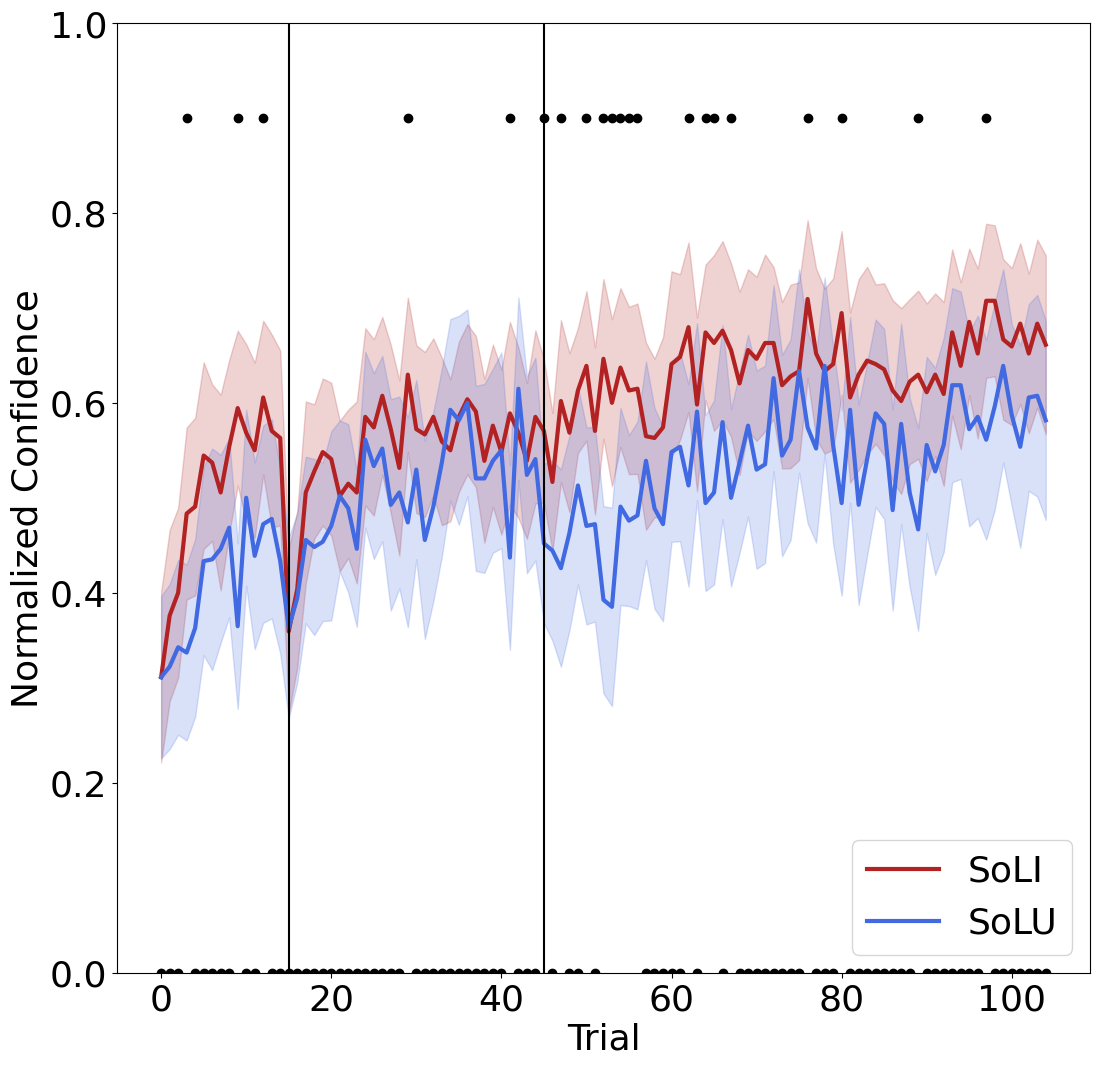

In [146]:

# Confidence — SoLI vs SoLU

g3_start = g1_len + g2_len

conf_g1 = all_conf[:g1_len]
conf_g2 = all_conf[g1_len:g3_start]

conf_g1_mean = np.mean(conf_g1, axis=0)
conf_g1_sem = scipy.stats.sem(conf_g1, axis=0)
conf_g1_ci = conf_g1_sem * scipy.stats.t.ppf(0.975, conf_g1.shape[0] - 1)

conf_g2_mean = np.mean(conf_g2, axis=0)
conf_g2_sem = scipy.stats.sem(conf_g2, axis=0)
conf_g2_ci = conf_g2_sem * scipy.stats.t.ppf(0.975, conf_g2.shape[0] - 1)

x = np.arange(105)

IU_conf_pval, IU_conf_stat, IU_conf_sig = all_trials_ttest(
    all_conf, 0, g1_len, g1_len, g3_start, 0, 105
)

fig, ax = plt.subplots(figsize=(12, 35/3))

ax.plot(x, conf_g1_mean, color='firebrick', label='SoLI', linewidth=3)
ax.fill_between(
    x, conf_g1_mean - conf_g1_ci, conf_g1_mean + conf_g1_ci,
    color='firebrick', alpha=0.2
)

ax.plot(x, conf_g2_mean, color='royalblue', label='SoLU', linewidth=3)
ax.fill_between(
    x, conf_g2_mean - conf_g2_ci, conf_g2_mean + conf_g2_ci,
    color='royalblue', alpha=0.2
)

ax.axvline(x=15, color='black')
ax.axvline(x=45, color='black')
ax.scatter(x, IU_conf_sig * 0.9, color='black')

ax.set_ylim([0, 1])
# ax.set_title('SoLI vs SoLU', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('Normalized Confidence', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.legend(loc=4, prop={'size': 26})

plt.tight_layout()
fignam = behfigdir + 'confidence_SoLI_vs_SoLU.svg'
fig.savefig(fignam, format='svg')
# fig.savefig('confidence_SoLI_vs_SoLU.svg', format='svg')
plt.show()


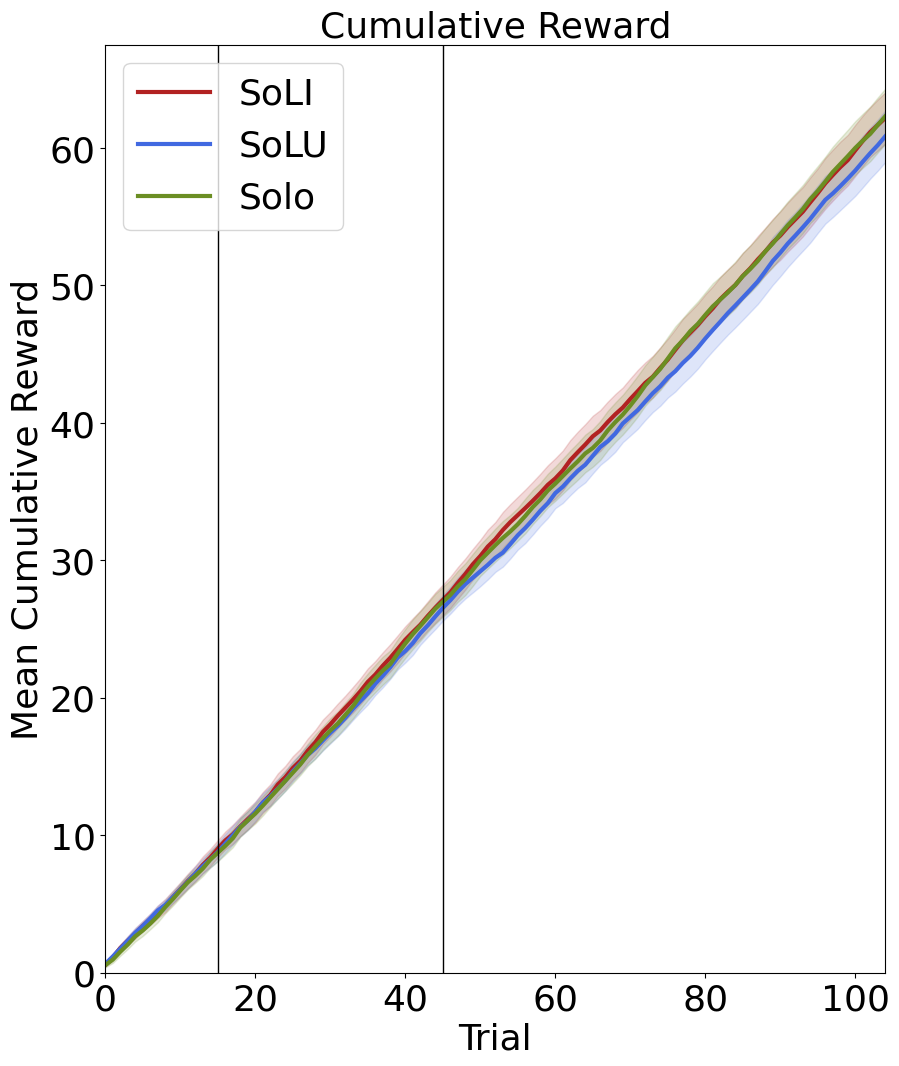

In [147]:

# ============================================================
# Cumulative Reward Across Groups
# ============================================================

# Step 1: Calculate cumulative rewards for each participant
soli_cumulative = np.cumsum(trained_rewards, axis=1)
solu_cumulative = np.cumsum(not_trained_rewards, axis=1)
solo_cumulative = np.cumsum(bl_rewards, axis=1)

# Step 2: Calculate group means and 95% confidence intervals
def cumulative_mean_ci(data):
    mean = np.mean(data, axis=0)
    sem = stats.sem(data, axis=0)
    ci = sem * stats.t.ppf(0.975, data.shape[0] - 1)
    return mean, ci

soli_mean_cum, soli_ci_cum = cumulative_mean_ci(soli_cumulative)
solu_mean_cum, solu_ci_cum = cumulative_mean_ci(solu_cumulative)
solo_mean_cum, solo_ci_cum = cumulative_mean_ci(solo_cumulative)

# Step 3: Create figure
x = np.arange(105)

fig, ax = plt.subplots(figsize=(10, 35/3))

# SoLI
ax.plot(
    x, soli_mean_cum,
    color='firebrick',
    label='SoLI',
    linewidth=3
)
ax.fill_between(
    x,
    soli_mean_cum - soli_ci_cum,
    soli_mean_cum + soli_ci_cum,
    color='firebrick',
    alpha=0.17
)

# SoLU
ax.plot(
    x, solu_mean_cum,
    color='royalblue',
    label='SoLU',
    linewidth=3
)
ax.fill_between(
    x,
    solu_mean_cum - solu_ci_cum,
    solu_mean_cum + solu_ci_cum,
    color='royalblue',
    alpha=0.17
)

# Solo
ax.plot(
    x, solo_mean_cum,
    color='olivedrab',
    label='Solo',
    linewidth=3
)
ax.fill_between(
    x,
    solo_mean_cum - solo_ci_cum,
    solo_mean_cum + solo_ci_cum,
    color='olivedrab',
    alpha=0.17
)

# Phase boundaries
ax.axvline(x=15, color='black', linewidth=1)
ax.axvline(x=45, color='black', linewidth=1)

# Formatting
ax.set_xlim([0, 104])
ax.set_ylim(bottom=0)

ax.set_title('Cumulative Reward', fontsize=26)
ax.set_xlabel('Trial', fontsize=26)
ax.set_ylabel('Mean Cumulative Reward', fontsize=26)

ax.tick_params(axis='both', labelsize=26)
ax.legend(loc=2, prop={'size': 26})

plt.tight_layout()

# fig.savefig('behavior_cumulative_reward.svg', format='svg')
plt.show()


# RL Model Fitting

In [95]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
# g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
# g3 = 'Solo'

## Value Based Models

$2arm$

In [96]:
def llik_td(x, *args):
    alpha, beta = x
    actions, rewards = args

    Q = np.zeros(2) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        Q_ = Q * beta
        logp_action = Q_ - scipy.special.logsumexp(Q_)

        logp_actions[t] = logp_action[a]

        Q[a] = Q[a] + alpha * (r - Q[a])

    return -np.sum(logp_actions[1:])

$4 arm$

In [97]:
def Q_4arms(x, *args):
    alpha, beta = x
    actions, rewards = args

    Q = np.zeros(4) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        Q_ = Q * beta
        logp_action = Q_ - scipy.special.logsumexp(Q_)

        logp_actions[t] = logp_action[a]

        Q[a] = Q[a] + alpha * (r - Q[a])

    return -np.sum(logp_actions[1:])

*Social Models*

In [98]:
def first_model_Qm(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
        if t > 14 and t < 45 and t % 3 == 0:
            obs_impact = np.zeros(4)
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact[ag_choice[0]] += gm1
            obs_impact[ag_choice[1]] += gm2
            obs_impact[ag_choice[2]] += gm3
            
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45 and t % 3 == 0:
            gamma = 0
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact = np.zeros(4)
            if chosen_ag == 'A':
                gamma = gm1
            elif chosen_ag == 'B':
                gamma = gm2
            elif chosen_ag == 'C':
                gamma = gm3
            else:
                gamma = 0
            try:
                obs_impact[ag_choice] += gamma
            except:
                obs_impact = np.zeros(4)
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        else:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
    return -np.sum(logp_actions[1:])
            

In [99]:
def first_model_Q0(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.zeros(4)
        if t > 14 and t < 45 and t % 3 == 0:
            obs_impact = np.zeros(4)
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact[ag_choice[0]] += gm1
            obs_impact[ag_choice[1]] += gm2
            obs_impact[ag_choice[2]] += gm3
            
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45 and t % 3 == 0:
            gamma = 0
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact = np.zeros(4)
            if chosen_ag == 'A':
                gamma = gm1
            elif chosen_ag == 'B':
                gamma = gm2
            elif chosen_ag == 'C':
                gamma = gm3
            else:
                gamma = 0
            try:
                obs_impact[ag_choice] += gamma
            except:
                obs_impact = np.zeros(4)
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        else:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
    return -np.sum(logp_actions[1:])
            

2 arm fitting

In [100]:
import os
import scipy
all_2arm_alpha = []
all_2arm_epsilon = []
for sub in all_sub_2arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta]
  result = scipy.optimize.minimize(llik_td, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_2arm_alpha.append(result.x[0])
  all_2arm_epsilon.append(result.x[1])
  

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 8.067594936864998
        x: [ 3.787e-01  4.506e+00]
      nit: 13
      jac: [ 1.137e-05  1.954e-06]
     nfev: 51
     njev: 17
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.38
MLE: epsilon = 4.51
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 3.298200785321147
        x: [ 9.931e-01  1.000e+02]
      nit: 31
      jac: [ 8.882e-08 -2.327e-05]
     nfev: 117
     njev: 39
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.99
MLE: epsilon = 100.00
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 20.10158995025867
        x: [ 1.000e-02  1.000e-02]
      nit: 2
      jac: [ 2.948e-02  3.220e-02]
     nfev: 15
     njev: 5
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 0.01
  message: CONVERGENCE: N

Base Line Model Fitting

In [101]:
import os
import scipy
all_bl_alpha = []
all_bl_epsilon = []
all_bl_neg_ll = []
for sub in all_bl_4arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta]
  result = scipy.optimize.minimize(Q_4arms, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_bl_alpha.append(result.x[0])
  all_bl_epsilon.append(result.x[1])
  all_bl_neg_ll.append(result.fun)

  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 73.76548614448213
        x: [ 3.864e-01  5.882e+00]
      nit: 8
      jac: [ 1.421e-06 -1.421e-06]
     nfev: 33
     njev: 11
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.39
MLE: epsilon = 5.88
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 126.07571439207986
        x: [ 1.000e+00  1.438e+00]
      nit: 7
      jac: [-3.085e-01 -1.421e-06]
     nfev: 30
     njev: 10
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 1.00
MLE: epsilon = 1.44
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 144.17681179004938
        x: [ 1.000e-02  1.000e-02]
      nit: 1
      jac: [ 1.966e-01  2.199e-01]
     nfev: 6
     njev: 2
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 0.01
  message: CONVERGENCE: NORM

Value Based model with Q mean

In [72]:
import os
import scipy
all_alpha_Qmean = []
all_gamma_Qmean = []
all_epsilon_Qmean = []
all_neg_ll_Qmean = []



for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_model_Qm, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_Qmean.append(result.x[0])
  all_gamma_Qmean.append([result.x[2], result.x[3], result.x[4]])
  all_epsilon_Qmean.append(result.x[1])
  all_neg_ll_Qmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 107.90235780371572
        x: [ 8.245e-01  2.284e+00  1.000e+00  3.070e-01  3.904e-01]
      nit: 15
      jac: [-3.212e-04  4.832e-05 -1.977e+01  3.411e-05  4.974e-05]
     nfev: 108
     njev: 18
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.82
MLE: epsilon = 2.28
MLE: gamma1 = 1.00
MLE: gamma2 = 0.31
MLE: gamma3 = 0.39
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 54.25903096353359
        x: [ 4.447e-01  4.997e+00  1.541e-01 -2.947e-01  8.659e-02]
      nit: 25
      jac: [-1.802e-03  2.082e-04  2.476e-03 -2.156e-03 -3.919e-03]
     nfev: 174
     njev: 29
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.44
MLE: epsilon = 5.00
MLE: gamma1 = 0.15
MLE: gamma2 = -0.29
MLE: gamma3 = 0.09
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 79.

Value Based Model with Q 0

In [73]:
all_alpha_Q0 = []
all_gamma_Q0 = []
all_epsilon_Q0 = []
all_neg_ll_Q0 = []
all_Q0 = []
for sub in all_sub_df:
  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_model_Q0, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_Q0.append(result.x[0])
  all_gamma_Q0.append([result.x[2], result.x[3], result.x[4]])
  all_epsilon_Q0.append(result.x[1])
  all_neg_ll_Q0.append(result.fun)
print(result)


MLE: alpha = 0.80
MLE: epsilon = 2.26
MLE: gamma1 = 1.00
MLE: gamma2 = 0.30
MLE: gamma3 = 0.39

MLE: alpha = 0.38
MLE: epsilon = 5.59
MLE: gamma1 = 0.12
MLE: gamma2 = -0.16
MLE: gamma3 = 0.16

MLE: alpha = 0.11
MLE: epsilon = 2.54
MLE: gamma1 = 0.52
MLE: gamma2 = 0.16
MLE: gamma3 = 0.28

MLE: alpha = 0.42
MLE: epsilon = 5.10
MLE: gamma1 = 0.22
MLE: gamma2 = 0.07
MLE: gamma3 = 0.05

MLE: alpha = 0.14
MLE: epsilon = 2.66
MLE: gamma1 = 0.39
MLE: gamma2 = 0.32
MLE: gamma3 = 0.19

MLE: alpha = 0.53
MLE: epsilon = 5.82
MLE: gamma1 = 0.01
MLE: gamma2 = -0.06
MLE: gamma3 = 0.42

MLE: alpha = 0.18
MLE: epsilon = 5.02
MLE: gamma1 = 0.04
MLE: gamma2 = 0.04
MLE: gamma3 = -0.05

MLE: alpha = 0.70
MLE: epsilon = 4.72
MLE: gamma1 = 0.17
MLE: gamma2 = 0.33
MLE: gamma3 = 0.02

MLE: alpha = 0.33
MLE: epsilon = 3.18
MLE: gamma1 = 1.00
MLE: gamma2 = 0.13
MLE: gamma3 = 0.69

MLE: alpha = 0.50
MLE: epsilon = 1.58
MLE: gamma1 = -0.22
MLE: gamma2 = 1.00
MLE: gamma3 = -0.03

MLE: alpha = 0.22
MLE: epsilon = 5

Sorting Gammas

In [74]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [75]:
sorted_g_0 = []
sorted_g_m = []
for idx, sub in enumerate(all_sub_ag_type):
    gamma_Q0 = [0, 0, 0]
    gamma_Qm = [0, 0, 0]
    ag_type = eval(sub)
    gamma_Q0[0] = all_gamma_Q0[idx][ag_type.index(0)]
    gamma_Q0[1] = all_gamma_Q0[idx][ag_type.index(1)]
    gamma_Q0[2] = all_gamma_Q0[idx][ag_type.index(2)]
    
    gamma_Qm[0] = all_gamma_Qmean[idx][ag_type.index(0)]
    gamma_Qm[1] = all_gamma_Qmean[idx][ag_type.index(1)]
    gamma_Qm[2] = all_gamma_Qmean[idx][ag_type.index(2)]
    sorted_g_0.append(gamma_Q0.copy())
    sorted_g_m.append(gamma_Qm.copy())
sorted_g_0 = np.array(sorted_g_0)
sorted_g_m = np.array(sorted_g_m)

## Policy Based Models

In [76]:
def first_policy_based_model_Qmean(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
            
        if t > 14 and t < 45:
            if t % 3 == 0:
                obs_impact = np.zeros(4)
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact[ag_choice[0]] += gm1
                obs_impact[ag_choice[1]] += gm2
                obs_impact[ag_choice[2]] += gm3
                   
            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45:
            if t % 3 == 0:
                gamma = 0
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact = np.zeros(4)
                if chosen_ag == 'A':
                    gamma = gm1
                elif chosen_ag == 'B':
                    gamma = gm2
                elif chosen_ag == 'C':
                    gamma = gm3
                else:
                    gamma = 0
                try:
                    obs_impact[ag_choice] += gamma
                except:
                    obs_impact = np.zeros(4)

            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
        else: 
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        
        
    return -np.sum(logp_actions[1:])

In [77]:
def first_policy_based_model_Q0(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.zeros(4)
            
        if t > 14 and t < 45:
            if t % 3 == 0:
                obs_impact = np.zeros(4)
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact[ag_choice[0]] += gm1
                obs_impact[ag_choice[1]] += gm2
                obs_impact[ag_choice[2]] += gm3
                   
            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45:
            if t % 3 == 0:
                gamma = 0
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact = np.zeros(4)
                if chosen_ag == 'A':
                    gamma = gm1
                elif chosen_ag == 'B':
                    gamma = gm2
                elif chosen_ag == 'C':
                    gamma = gm3
                else:
                    gamma = 0
                try:
                    obs_impact[ag_choice] += gamma
                except:
                    obs_impact = np.zeros(4)

            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
        else: 
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        
        
    return -np.sum(logp_actions[1:])

In [78]:
import os
import scipy
all_alpha_pQmean = []
all_gamma_pQmean = []
all_beta_pQmean = []
all_neg_ll_pQmean = []

for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_policy_based_model_Qmean, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_pQmean.append(result.x[0])
  all_gamma_pQmean.append([result.x[2], result.x[3], result.x[4]])
  all_beta_pQmean.append(result.x[1])
  all_neg_ll_pQmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 113.9676909957781
        x: [ 1.206e-01  4.265e+00  2.714e-01  1.712e-01  1.750e-02]
      nit: 15
      jac: [ 4.604e-04  2.558e-05 -4.178e-04  1.791e-04  5.784e-04]
     nfev: 108
     njev: 18
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.12
MLE: epsilon = 4.26
MLE: gamma1 = 0.27
MLE: gamma2 = 0.17
MLE: gamma3 = 0.02
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 49.96479762852634
        x: [ 2.382e-01  9.144e+00  1.569e-01 -9.683e-04  2.657e-01]
      nit: 14
      jac: [ 0.000e+00  0.000e+00  1.421e-06 -4.263e-06 -4.974e-06]
     nfev: 108
     njev: 18
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.24
MLE: epsilon = 9.14
MLE: gamma1 = 0.16
MLE: gamma2 = -0.00
MLE: gamma3 = 0.27
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 51.

In [79]:
import os
import scipy
all_alpha_pQ0 = []
all_gamma_pQ0 = []
all_beta_pQ0 = []
all_neg_ll_pQ0 = []

for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_policy_based_model_Q0, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_pQ0.append(result.x[0])
  all_gamma_pQ0.append([result.x[2], result.x[3], result.x[4]])
  all_beta_pQ0.append(result.x[1])
  all_neg_ll_pQ0.append(result.fun)


  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 114.04012013155847
        x: [ 1.683e-01  3.312e+00  3.559e-01  2.015e-01  4.927e-02]
      nit: 12
      jac: [-1.009e-04  0.000e+00  5.826e-05 -5.116e-05 -1.421e-06]
     nfev: 90
     njev: 15
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.17
MLE: epsilon = 3.31
MLE: gamma1 = 0.36
MLE: gamma2 = 0.20
MLE: gamma3 = 0.05
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 48.551102439063484
        x: [ 3.295e-01  6.337e+00  1.771e-01 -4.579e-02  3.574e-01]
      nit: 15
      jac: [-1.492e-05 -5.684e-06 -1.137e-05  4.974e-06  2.274e-05]
     nfev: 114
     njev: 19
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.33
MLE: epsilon = 6.34
MLE: gamma1 = 0.18
MLE: gamma2 = -0.05
MLE: gamma3 = 0.36
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 51.

Sorting Gammas

In [80]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [81]:
sorted_pg_m = []
sorted_pg_0 = []
for idx, sub in enumerate(all_sub_ag_type):
    gamma_pQm = [0, 0, 0]
    gamma_pQ0 = [0, 0, 0]
    ag_type = eval(sub)
    gamma_pQm[0] = all_gamma_pQmean[idx][ag_type.index(0)]
    gamma_pQm[1] = all_gamma_pQmean[idx][ag_type.index(1)]
    gamma_pQm[2] = all_gamma_pQmean[idx][ag_type.index(2)]
    
    gamma_pQ0[0] = all_gamma_pQ0[idx][ag_type.index(0)]
    gamma_pQ0[1] = all_gamma_pQ0[idx][ag_type.index(1)]
    gamma_pQ0[2] = all_gamma_pQ0[idx][ag_type.index(2)]
    
    

    sorted_pg_m.append(gamma_pQm.copy())
    sorted_pg_0.append(gamma_pQ0.copy())

sorted_pg_m = np.array(sorted_pg_m)
sorted_pg_0 = np.array(sorted_pg_0)

## Comparing Value Based and Policy Based Models

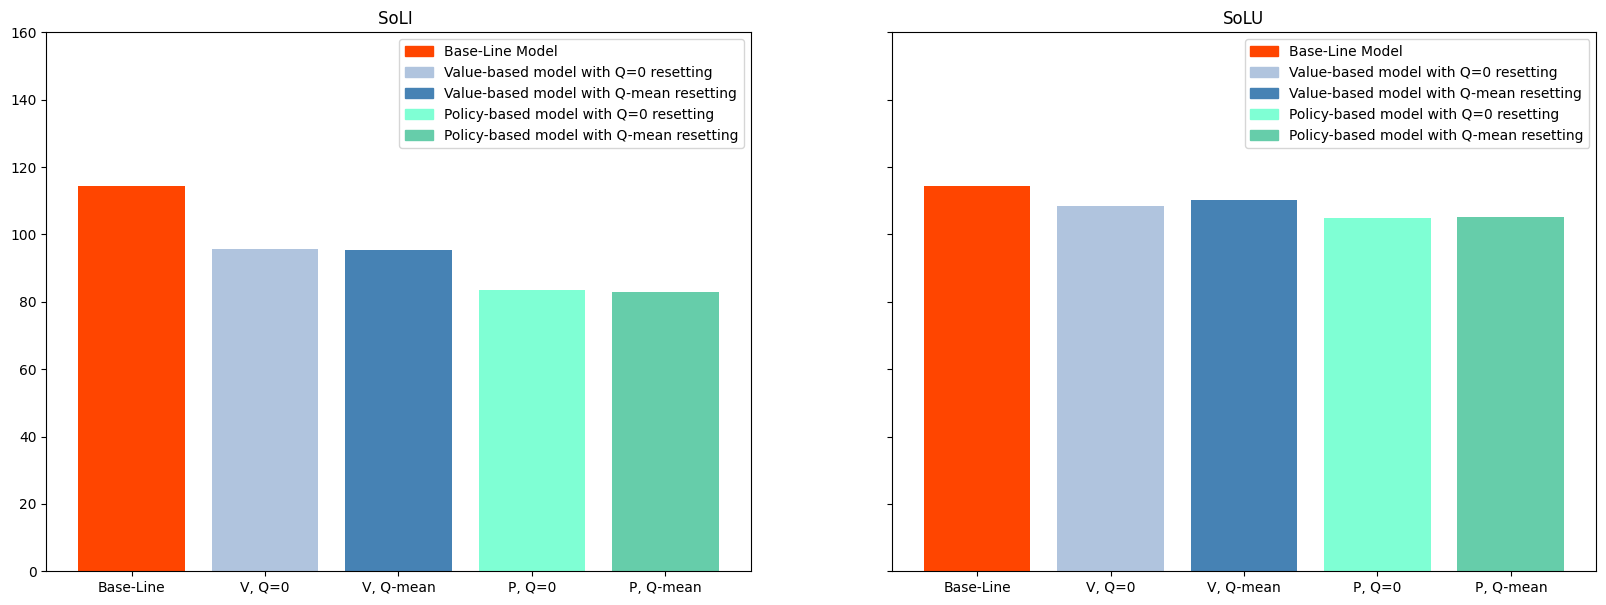

In [82]:
x = ['Base-Line', 'V, Q=0', 'V, Q-mean', 'P, Q=0', 'P, Q-mean']
trained_mean_nll = [np.mean(all_bl_neg_ll), np.mean(all_neg_ll_Q0[:g1_len]), np.mean(all_neg_ll_Qmean[:g1_len]), np.mean(all_neg_ll_pQ0[:g1_len]), np.mean(all_neg_ll_pQmean[:g1_len])]
not_trained_mean_nll = [np.mean(all_bl_neg_ll), np.mean(all_neg_ll_Q0[g1_len:]), np.mean(all_neg_ll_Qmean[g1_len:]), np.mean(all_neg_ll_pQ0[g1_len:]), np.mean(all_neg_ll_pQmean[g1_len:])]
clr = ['orangered', 'lightsteelblue', 'steelblue', 'aquamarine', 'mediumaquamarine']
labels = ['Base-Line Model', 'Value-based model with Q=0 resetting', 'Value-based model with Q-mean resetting', 'Policy-based model with Q=0 resetting', 'Policy-based model with Q-mean resetting']
fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 7))
# fig.suptitle('Bar plot of mean NLL of all models for each group')

axs[0].set_ylim([0, 160])
axs[0].bar(x, trained_mean_nll, color=clr)
axs[0].set_title(g1)

axs[1].bar(x, not_trained_mean_nll, color=clr)
axs[1].set_title(g2)

from matplotlib.patches import Patch
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
axs[0].legend(handles=handles, loc='best')
axs[1].legend(handles=handles, loc='best')

plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/RL-both-NLL.svg')

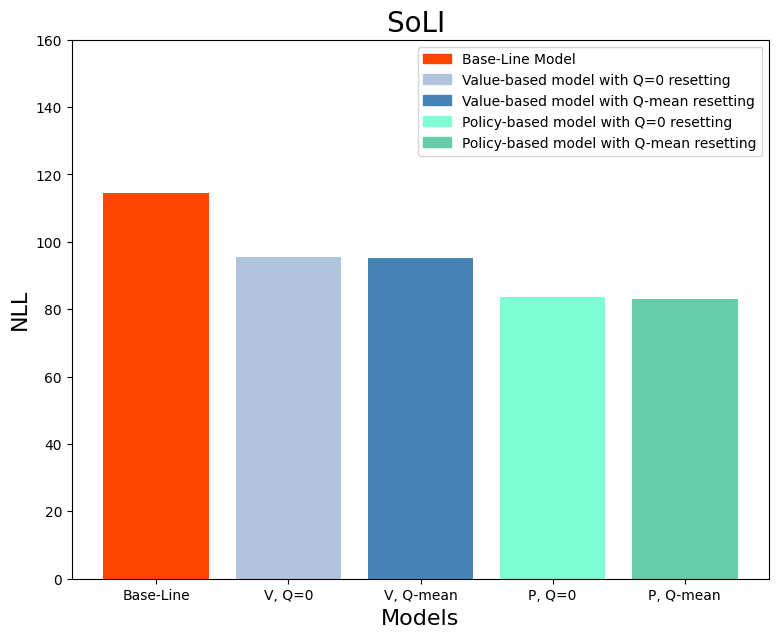

In [83]:
x = ['Base-Line', 'V, Q=0', 'V, Q-mean', 'P, Q=0', 'P, Q-mean']
trained_mean_nll = [np.mean(all_bl_neg_ll), np.mean(all_neg_ll_Q0[:g1_len]), np.mean(all_neg_ll_Qmean[:g1_len]), np.mean(all_neg_ll_pQ0[:g1_len]), np.mean(all_neg_ll_pQmean[:g1_len])]
clr = ['orangered', 'lightsteelblue', 'steelblue', 'aquamarine', 'mediumaquamarine']
labels = ['Base-Line Model', 'Value-based model with Q=0 resetting', 'Value-based model with Q-mean resetting', 'Policy-based model with Q=0 resetting', 'Policy-based model with Q-mean resetting']
fig, axs = plt.subplots(1, 1, sharey='all', figsize=(9, 7))
# fig.suptitle('Bar plot of mean NLL of all models for each group')

axs.set_ylim([0, 160])
axs.bar(x, trained_mean_nll, color=clr)
axs.set_title(g1, fontsize=20)
axs.set_xlabel('Models', fontsize=16)
axs.set_ylabel('NLL', fontsize=16)



from matplotlib.patches import Patch
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
axs.legend(handles=handles, loc='best')

plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/RL-NLL.svg')


In [84]:
from scipy.stats import ttest_ind

t_stat, pval = ttest_ind(all_neg_ll_Qmean[:g1_len], all_neg_ll_pQmean[:g1_len])
print('The result of t-test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('t-stat:', t_stat, ' P-value:', pval)

The result of t-test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
t-stat: 1.962364895883123  P-value: 0.05287953711314385


In [85]:
from scipy.stats import mannwhitneyu

u_stat, pval = mannwhitneyu(all_neg_ll_Qmean[:g1_len], all_neg_ll_pQmean[:g1_len])
print('The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('u-stat:', u_stat, ' P-value:', pval)

The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
u-stat: 1264.0  P-value: 0.04281658092357167


In [86]:
from scipy.stats import mannwhitneyu

u_stat, pval = mannwhitneyu(all_bl_neg_ll, all_neg_ll_pQmean[:g1_len])
print('The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('u-stat:', u_stat, ' P-value:', pval)

The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
u-stat: 1389.0  P-value: 1.700270056375422e-05


In [87]:
from scipy.stats import mannwhitneyu

u_stat, pval = mannwhitneyu(all_neg_ll_Qmean[:g1_len], all_neg_ll_pQmean[:g1_len])
print('The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('u-stat:', u_stat, ' P-value:', pval)

The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
u-stat: 1264.0  P-value: 0.04281658092357167


## Distributions

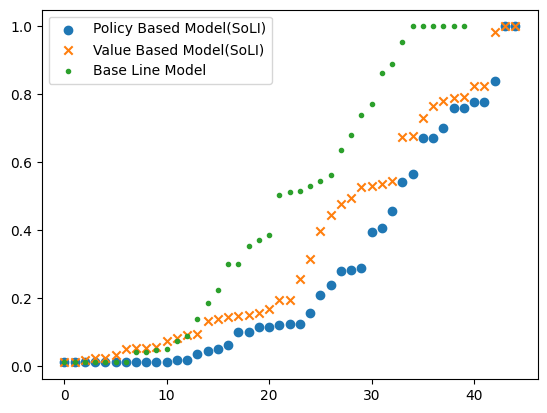

In [88]:
x = [i for i in range(g1_len)]
x2 = [i for i in range(40)]
plt.scatter(x, np.sort(np.array(all_alpha_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
plt.scatter(x, np.sort(np.array(all_alpha_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
plt.scatter(x2, np.sort(np.array(all_bl_alpha)), marker='.', label='Base Line Model')
plt.legend()


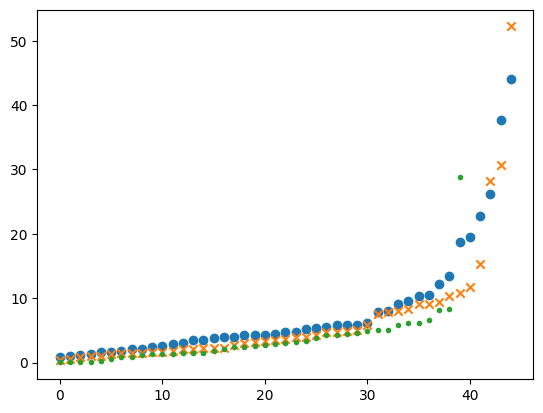

In [89]:
plt.scatter(x, np.sort(np.array(all_beta_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
plt.scatter(x, np.sort(np.array(all_epsilon_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
plt.scatter(x2, np.sort(np.array(all_bl_epsilon)), marker='.', label='Base Line Model')


Gammas

best

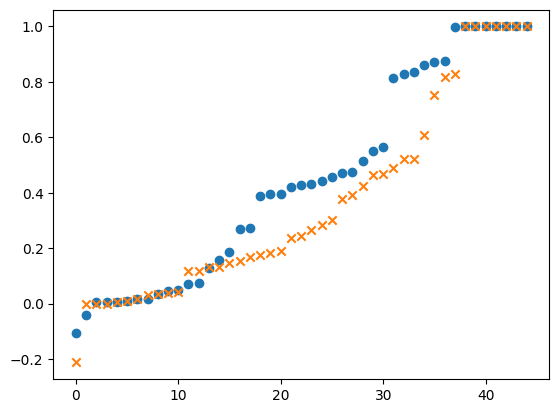

In [90]:
plt.scatter(x, np.sort(sorted_pg_m[:g1_len, 0]), marker='o')
plt.scatter(x, np.sort(sorted_g_m[:g1_len, 0]), marker = 'x')

Second

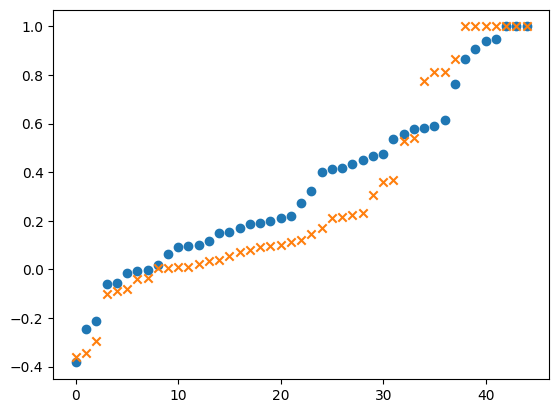

In [91]:
plt.scatter(x, np.sort(sorted_pg_m[:g1_len, 1]), marker='o')
plt.scatter(x, np.sort(sorted_g_m[:g1_len, 1]), marker = 'x')

worst

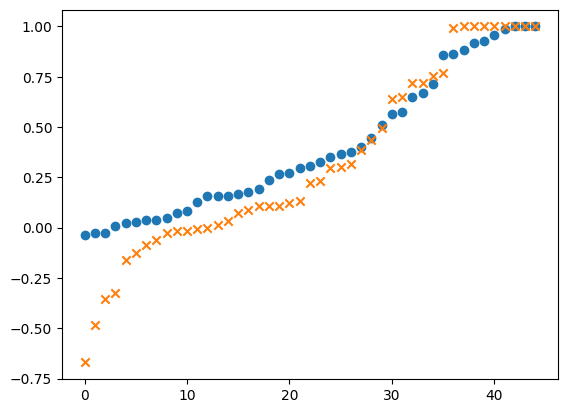

In [92]:
plt.scatter(x, np.sort(sorted_pg_m[:g1_len, 2]), marker='o')
plt.scatter(x, np.sort(sorted_g_m[:g1_len, 2]), marker = 'x')

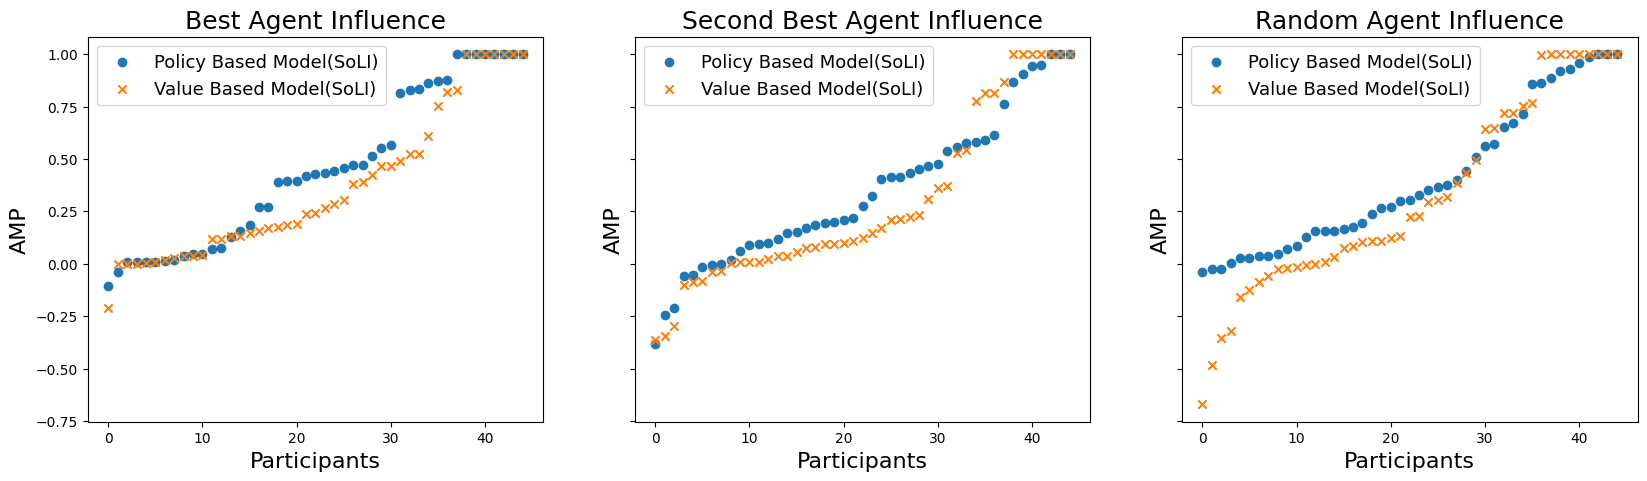

In [93]:
fig, axs = plt.subplots(1, 3, sharey='all', figsize=(20, 5))
x1 = [i for i in range(45)]
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 0]), marker='o', label='Policy Based Model(SoLI)')
axs[0].scatter(x1, np.sort(sorted_g_m[:g1_len, 0]), marker = 'x', label='Value Based Model(SoLI)')
axs[0].set_title('Best Agent Influence', fontsize=18)
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].legend(loc=2, prop={'size': 13})

axs[1].scatter(x1, np.sort(sorted_pg_m[:g1_len, 1]), marker='o', label='Policy Based Model(SoLI)')
axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 1]), marker = 'x', label='Value Based Model(SoLI)')
axs[1].set_title('Second Best Agent Influence', fontsize=18)
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].legend(loc=2, prop={'size': 13})

axs[2].scatter(x1, np.sort(sorted_pg_m[:g1_len, 2]), marker='o', label='Policy Based Model(SoLI)')
axs[2].scatter(x1, np.sort(sorted_g_m[:g1_len, 2]), marker = 'x', label='Value Based Model(SoLI)')
axs[2].set_title('Random Agent Influence', fontsize=18)
axs[2].set_xlabel('Participants', fontsize=16)
axs[2].set_ylabel('AMP', fontsize=16)
axs[2].legend(loc=2, prop={'size': 13});
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Gammas-Dist.svg')


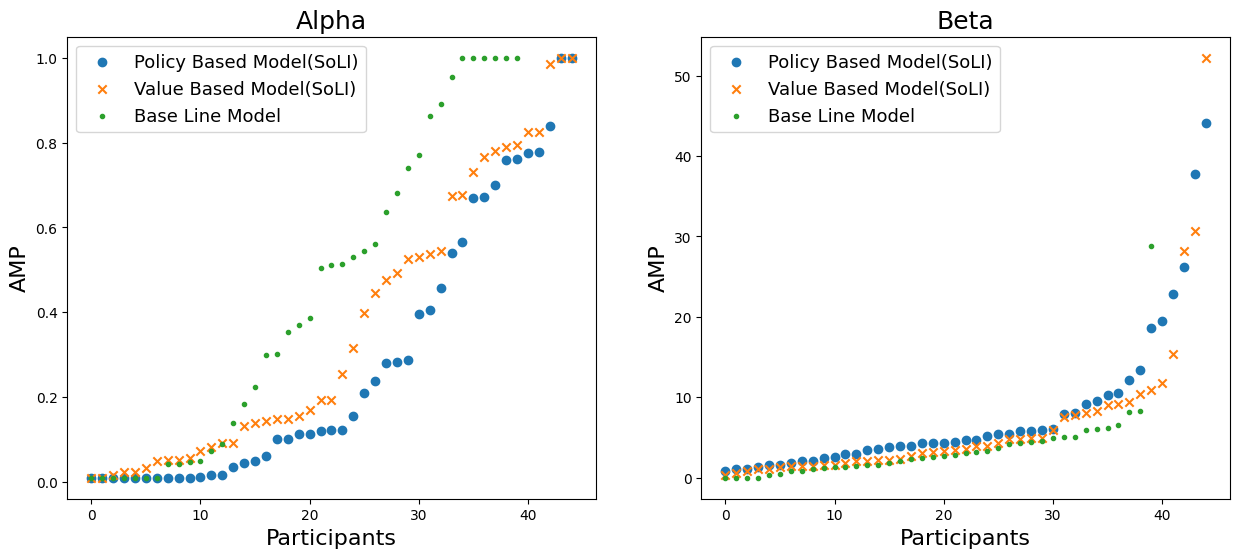

In [94]:
fig, axs = plt.subplots(1, 2, sharex='all', figsize=(15, 6))
x1 = [i for i in range(45)]
x2 = [i for i in range(40)]
axs[0].scatter(x1, np.sort(np.array(all_alpha_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
axs[0].scatter(x1, np.sort(np.array(all_alpha_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
axs[0].scatter(x2, np.sort(np.array(all_bl_alpha)), marker='.', label='Base Line Model')
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Alpha', fontsize=18)
axs[0].legend(loc=2, prop={'size': 13})

axs[1].scatter(x1, np.sort(np.array(all_beta_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
axs[1].scatter(x1, np.sort(np.array(all_epsilon_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
axs[1].scatter(x2, np.sort(np.array(all_bl_epsilon)), marker='.', label='Base Line Model')
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Beta', fontsize=18)
axs[1].legend(loc=2, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/ALpha-Beta.svg')

# RL Visualization

Alpha Beta

In [97]:
p_alpha_idx = np.argsort(np.array(all_alpha_pQmean[:g1_len]))
v_alpha_idx = np.argsort(np.array(all_alpha_Qmean[:g1_len]))
b_alpha_idx = np.argsort(np.array(all_bl_alpha))

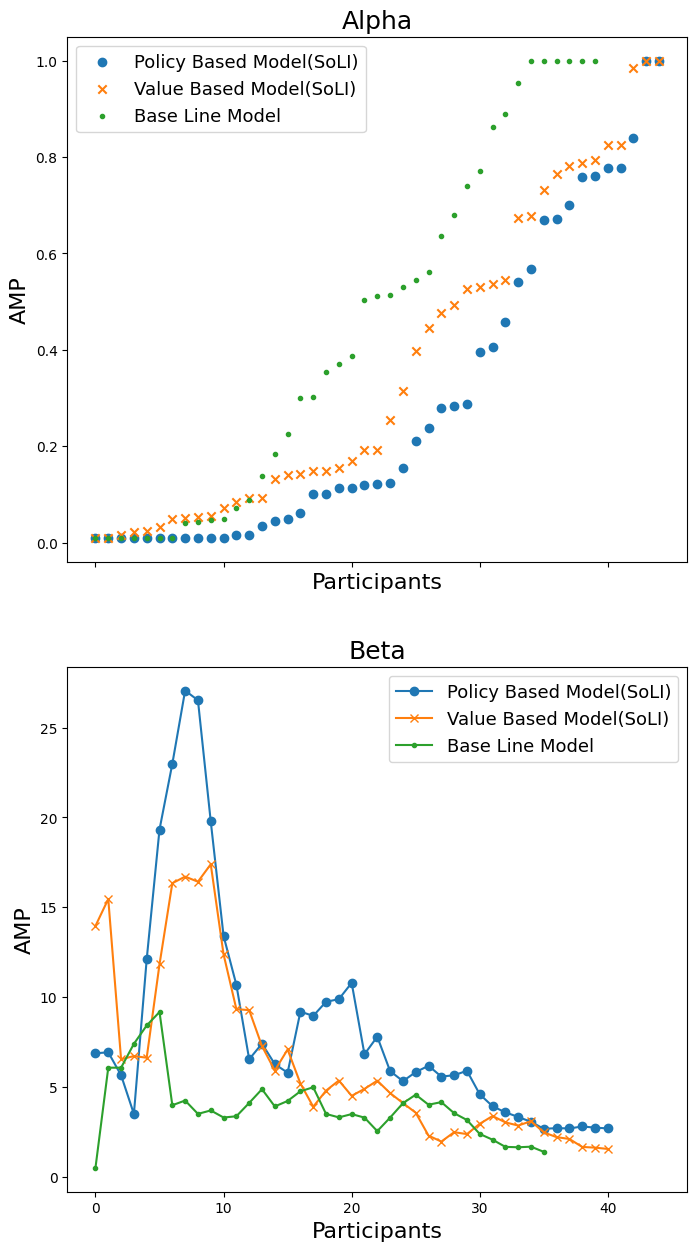

In [98]:
fig, axs = plt.subplots(2, 1, sharex='all', figsize=(8, 15))
x1 = [i for i in range(45)]
x2 = [i for i in range(40)]
axs[0].scatter(x1, np.sort(np.array(all_alpha_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
axs[0].scatter(x1, np.sort(np.array(all_alpha_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
axs[0].scatter(x2, np.sort(np.array(all_bl_alpha)), marker='.', label='Base Line Model')
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Alpha', fontsize=18)
axs[0].legend(loc=2, prop={'size': 13})

axs[1].plot(np.convolve(np.array(all_beta_pQmean[:g1_len])[p_alpha_idx], np.ones(5)/5, mode='valid'), marker='o', label='Policy Based Model(SoLI)')
axs[1].plot(np.convolve(np.array(all_epsilon_Qmean[:g1_len])[v_alpha_idx], np.ones(5)/5, mode='valid'), marker='x', label='Value Based Model(SoLI)')
axs[1].plot(np.convolve(np.array(all_bl_epsilon)[b_alpha_idx], np.ones(5)/5, mode='valid'), marker='.', label='Base Line Model')
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Beta', fontsize=18)
axs[1].legend(loc=1, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/ALpha-Beta2.svg')

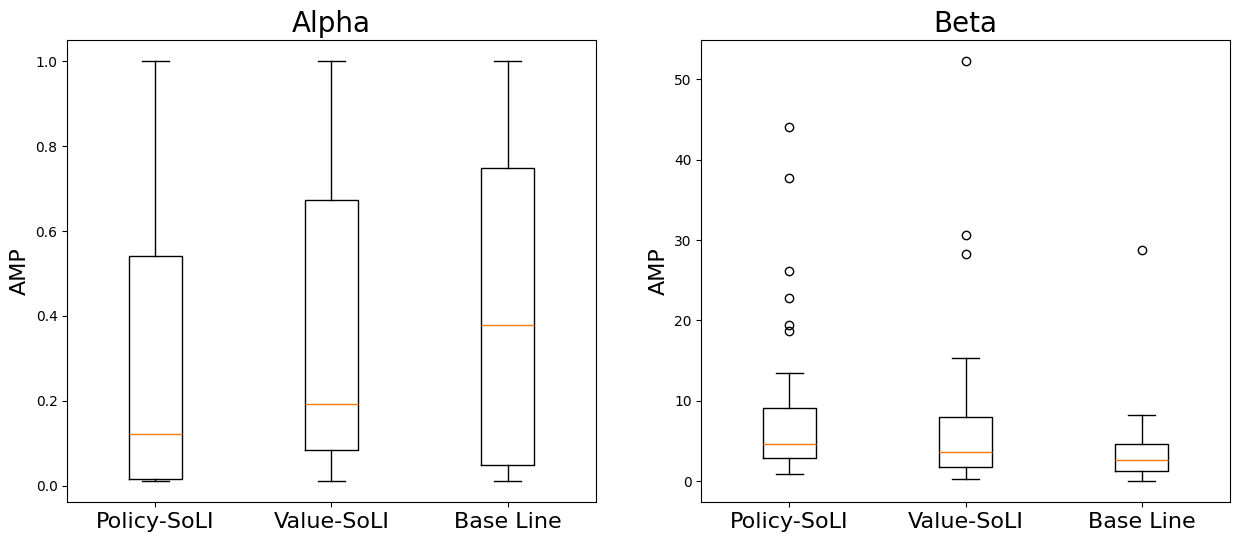

In [99]:

data1 = [np.array(all_alpha_pQmean[:g1_len]), np.array(all_alpha_Qmean[:g1_len]), np.array(all_bl_alpha)]
data2 = [np.array(all_beta_pQmean[:g1_len]), np.array(all_epsilon_Qmean[:g1_len]), np.array(all_bl_epsilon)]
ls = ['Policy-SoLI', 'Value-SoLI', 'Base Line']

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

axs[0].boxplot(data1, labels=ls)
axs[0].set_xticklabels(ls, fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Alpha', fontsize=20)

axs[1].boxplot(data2, labels=ls)
axs[1].set_xticklabels(ls, fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Beta', fontsize=20)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/ALpha-Beta-bplot.svg')

Gamma

In [100]:
trained_pg_best_idx = np.argsort(sorted_pg_m[:g1_len, 0])

sorted_trained_pg_best = sorted_pg_m[:g1_len, 0][trained_pg_best_idx]
sorted_trained_pg_second = sorted_pg_m[:g1_len, 1][trained_pg_best_idx]
sorted_trained_pg_worst = sorted_pg_m[:g1_len, 2][trained_pg_best_idx]

In [101]:
trained_g_best_idx = np.argsort(sorted_g_m[:g1_len, 0])

sorted_trained_g_best = sorted_g_m[:g1_len, 0][trained_g_best_idx]
sorted_trained_g_second = sorted_g_m[:g1_len, 1][trained_g_best_idx]
sorted_trained_g_worst = sorted_g_m[:g1_len, 2][trained_g_best_idx]

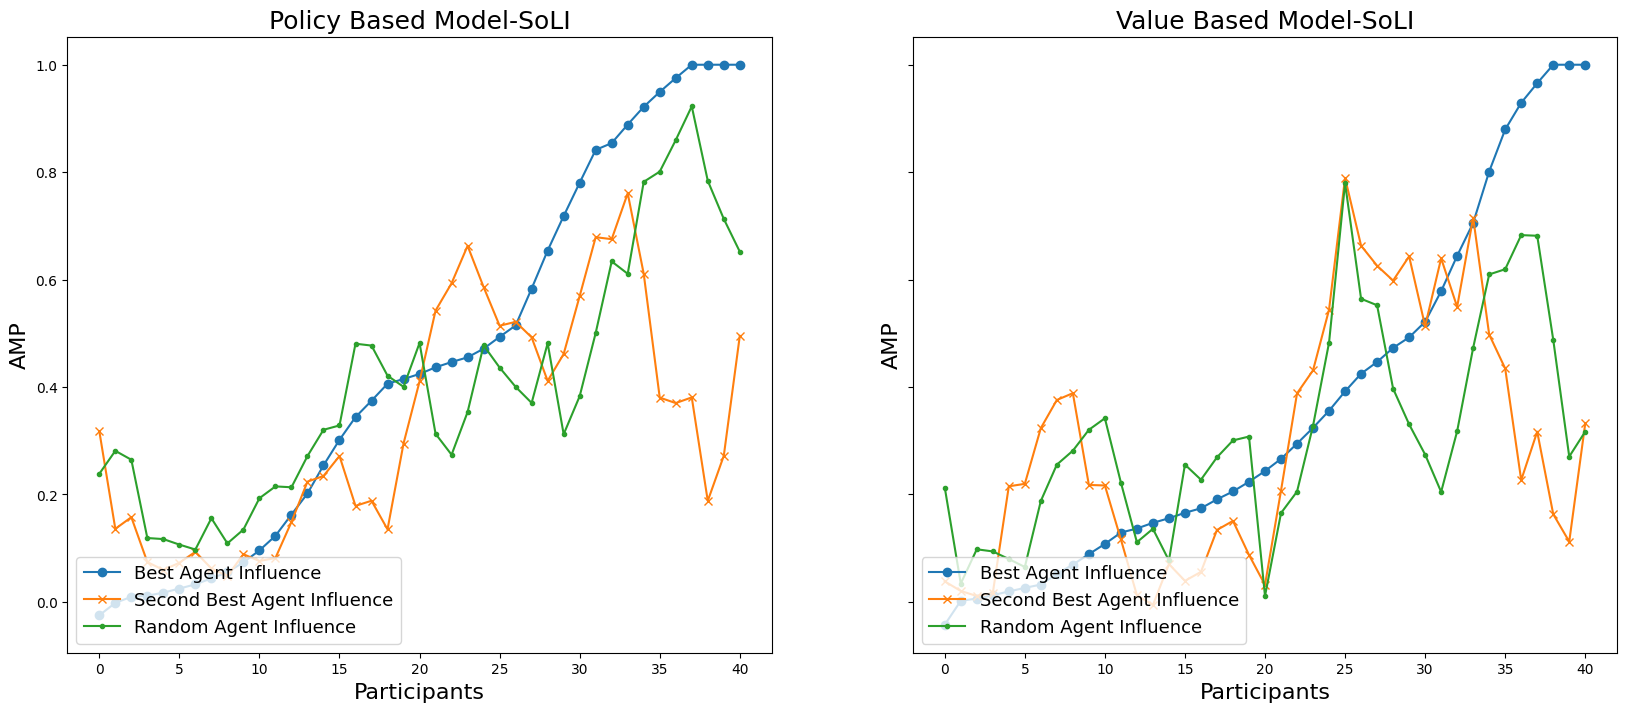

In [102]:
fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 8))
x1 = [i for i in range(45)]


# np.convolve(sorted_trained_g_best, np.ones(3)/3, mode='valid')

axs[0].plot(np.convolve(sorted_trained_pg_best, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence')
axs[0].plot(np.convolve(sorted_trained_pg_second, np.ones(5)/5, mode='valid'), marker='x', label='Second Best Agent Influence')
axs[0].plot(np.convolve(sorted_trained_pg_worst, np.ones(5)/5, mode='valid'), marker='.', label='Random Agent Influence')
axs[0].set_title('Policy Based Model-SoLI', fontsize=18)
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].legend(loc=3, prop={'size': 13})

axs[1].plot(np.convolve(sorted_trained_g_best, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence')
axs[1].plot(np.convolve(sorted_trained_g_second, np.ones(5)/5, mode='valid'), marker='x', label='Second Best Agent Influence')
axs[1].plot(np.convolve(sorted_trained_g_worst, np.ones(5)/5, mode='valid'), marker='.', label='Random Agent Influence')
axs[1].set_title('Value Based Model-SoLI', fontsize=18)
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].legend(loc=3, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/Gammas-1.svg')

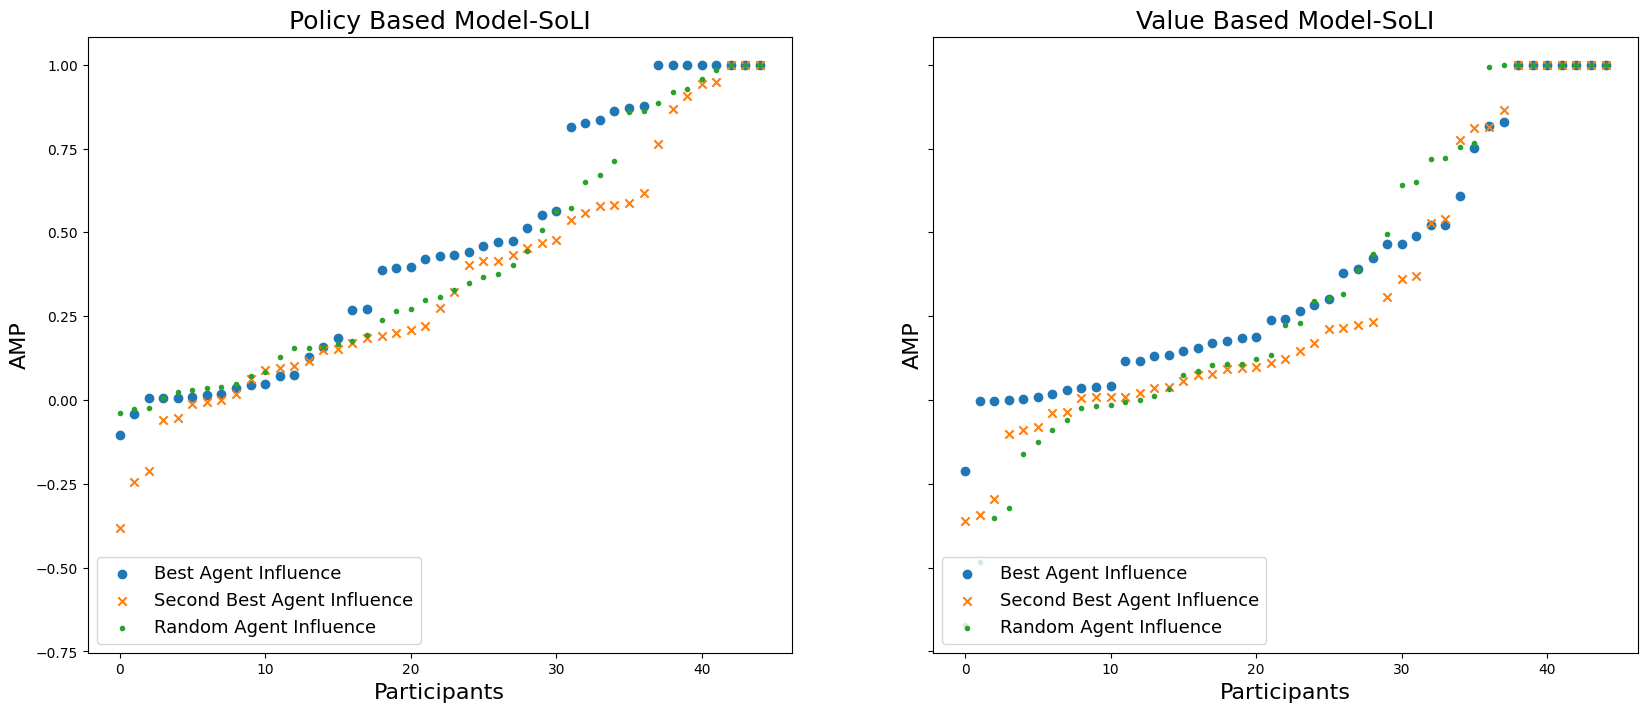

In [103]:
fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 8))
x1 = [i for i in range(45)]
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 0]), marker='o', label='Best Agent Influence')
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 1]), marker='x', label='Second Best Agent Influence')
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 2]), marker='.', label='Random Agent Influence')
axs[0].set_title('Policy Based Model-SoLI', fontsize=18)
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].legend(loc=3, prop={'size': 13})

axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 0]), marker='o', label='Best Agent Influence')
axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 1]), marker='x', label='Second Best Agent Influence')
axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 2]), marker='.', label='Random Agent Influence')
axs[1].set_title('Value Based Model-SoLI', fontsize=18)
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].legend(loc=3, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/Gammas-2.svg')

Gamma box plots

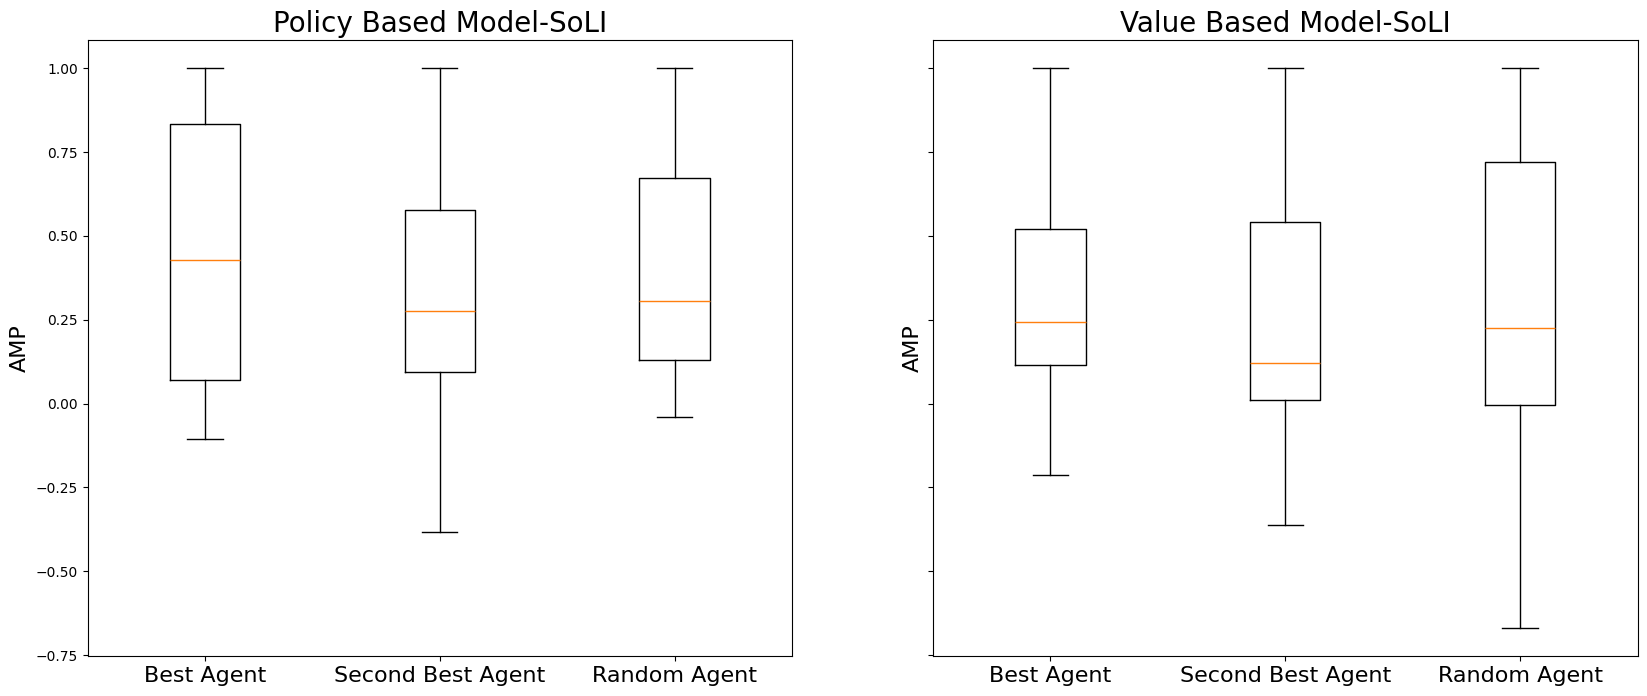

In [104]:
data1 = [sorted_pg_m[:g1_len, 0], sorted_pg_m[:g1_len, 1], sorted_pg_m[:g1_len, 2]]
data2 = [sorted_g_m[:g1_len, 0], sorted_g_m[:g1_len, 1], sorted_g_m[:g1_len, 2]]

fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 8))
ls = ['Best Agent', 'Second Best Agent', 'Random Agent']
axs[0].boxplot(data1, labels=ls)
axs[0].set_xticklabels(ls, fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Policy Based Model-SoLI', fontsize=20)

axs[1].boxplot(data2, labels=ls)
axs[1].set_xticklabels(ls, fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Value Based Model-SoLI', fontsize=20)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/Gammas-bplot.svg')

# RL VIS LAST VERSION

## value based model data sorting (by beta)

SoLI

In [105]:
# sorted_numbers, indices = np.array(numbers)[np.argsort(numbers)], np.argsort(numbers)

v_sorted_beta_m, v_sorted_idx_m = np.array(all_epsilon_Qmean[:45])[np.argsort(all_epsilon_Qmean[:45])], np.argsort(all_epsilon_Qmean[:45])
v_sorted_alpha_m = np.array(all_alpha_Qmean[:45])[list(v_sorted_idx_m)]
v_sorted_best_m = sorted_g_m[:45, 0][list(v_sorted_idx_m)]
v_sorted_second_m = sorted_g_m[:45, 1][list(v_sorted_idx_m)]
v_sorted_worst_m = sorted_g_m[:45, 2][list(v_sorted_idx_m)]

SoLU

In [106]:
U_v_sorted_beta_m, U_v_sorted_idx_m = np.array(all_epsilon_Qmean[45:])[np.argsort(all_epsilon_Qmean[45:])], np.argsort(all_epsilon_Qmean[45:])
U_v_sorted_alpha_m = np.array(all_alpha_Qmean[45:])[list(U_v_sorted_idx_m)]
U_v_sorted_best_m = sorted_g_m[45:, 0][list(U_v_sorted_idx_m)]
U_v_sorted_second_m = sorted_g_m[45:, 1][list(U_v_sorted_idx_m)]
U_v_sorted_worst_m = sorted_g_m[45:, 2][list(U_v_sorted_idx_m)]

## Policy based model data sorting (by beta)

SoLI

In [107]:
p_sorted_beta_m, p_sorted_idx_m = np.array(all_beta_pQmean[:45])[np.argsort(all_beta_pQmean[:45])], np.argsort(all_beta_pQmean[:45])
p_sorted_alpha_m = np.array(all_alpha_pQmean[:45])[list(p_sorted_idx_m)]
p_sorted_best_m = sorted_pg_m[:45, 0][list(p_sorted_idx_m)]
p_sorted_second_m = sorted_pg_m[:45, 1][list(p_sorted_idx_m)]
p_sorted_worst_m = sorted_pg_m[:45, 2][list(p_sorted_idx_m)]

SoLU

In [108]:
U_p_sorted_beta_m, U_p_sorted_idx_m = np.array(all_beta_pQmean[45:])[np.argsort(all_beta_pQmean[45:])], np.argsort(all_beta_pQmean[45:])
U_p_sorted_alpha_m = np.array(all_alpha_pQmean[45:])[list(U_p_sorted_idx_m)]
U_p_sorted_best_m = sorted_pg_m[45:, 0][list(U_p_sorted_idx_m)]
U_p_sorted_second_m = sorted_pg_m[45:, 1][list(U_p_sorted_idx_m)]
U_p_sorted_worst_m = sorted_pg_m[45:, 2][list(U_p_sorted_idx_m)]

## Visualizing

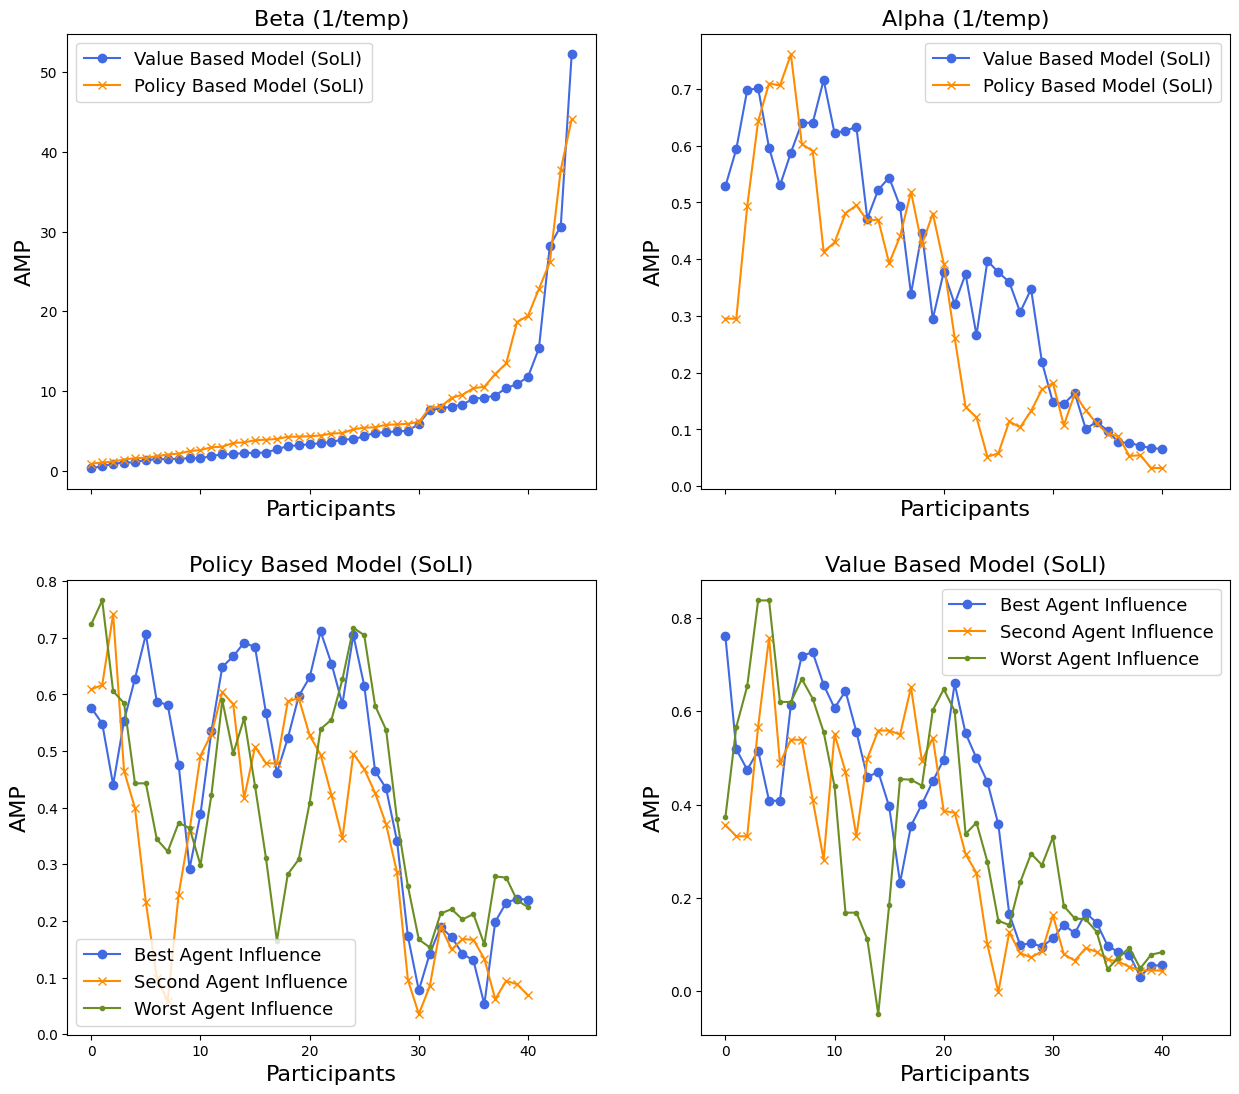

In [109]:
fig, axs = plt.subplots(2, 2, sharex='all', figsize=(15, 13))

x1 = [i for i in range(45)]

axs[0, 0].plot(v_sorted_beta_m, marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 0].plot(p_sorted_beta_m, marker='x', label='Policy Based Model (SoLI)', color='darkorange')
# axs[0, 0].plot(U_v_sorted_beta_m, marker='o', label='Value Based Model (SoLI)', color='olivedrab')
# axs[0, 0].plot(U_p_sorted_beta_m, marker='x', label='Policy Based Model (SoLI)', color='firebrick')
axs[0, 0].set_title('Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(v_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 1].plot(np.convolve(p_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='Policy Based Model (SoLI)', color='darkorange')
axs[0, 1].set_title('Alpha (1/temp)', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[1, 0].plot(np.convolve(p_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 0].plot(np.convolve(p_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 0].plot(np.convolve(p_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 0].set_title('Policy Based Model (SoLI)', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(np.convolve(v_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 1].plot(np.convolve(v_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 1].plot(np.convolve(v_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 1].set_title('Value Based Model (SoLI)', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})
# np.convolve(p_sorted_best_m, np.ones(5)/5, mode='valid')

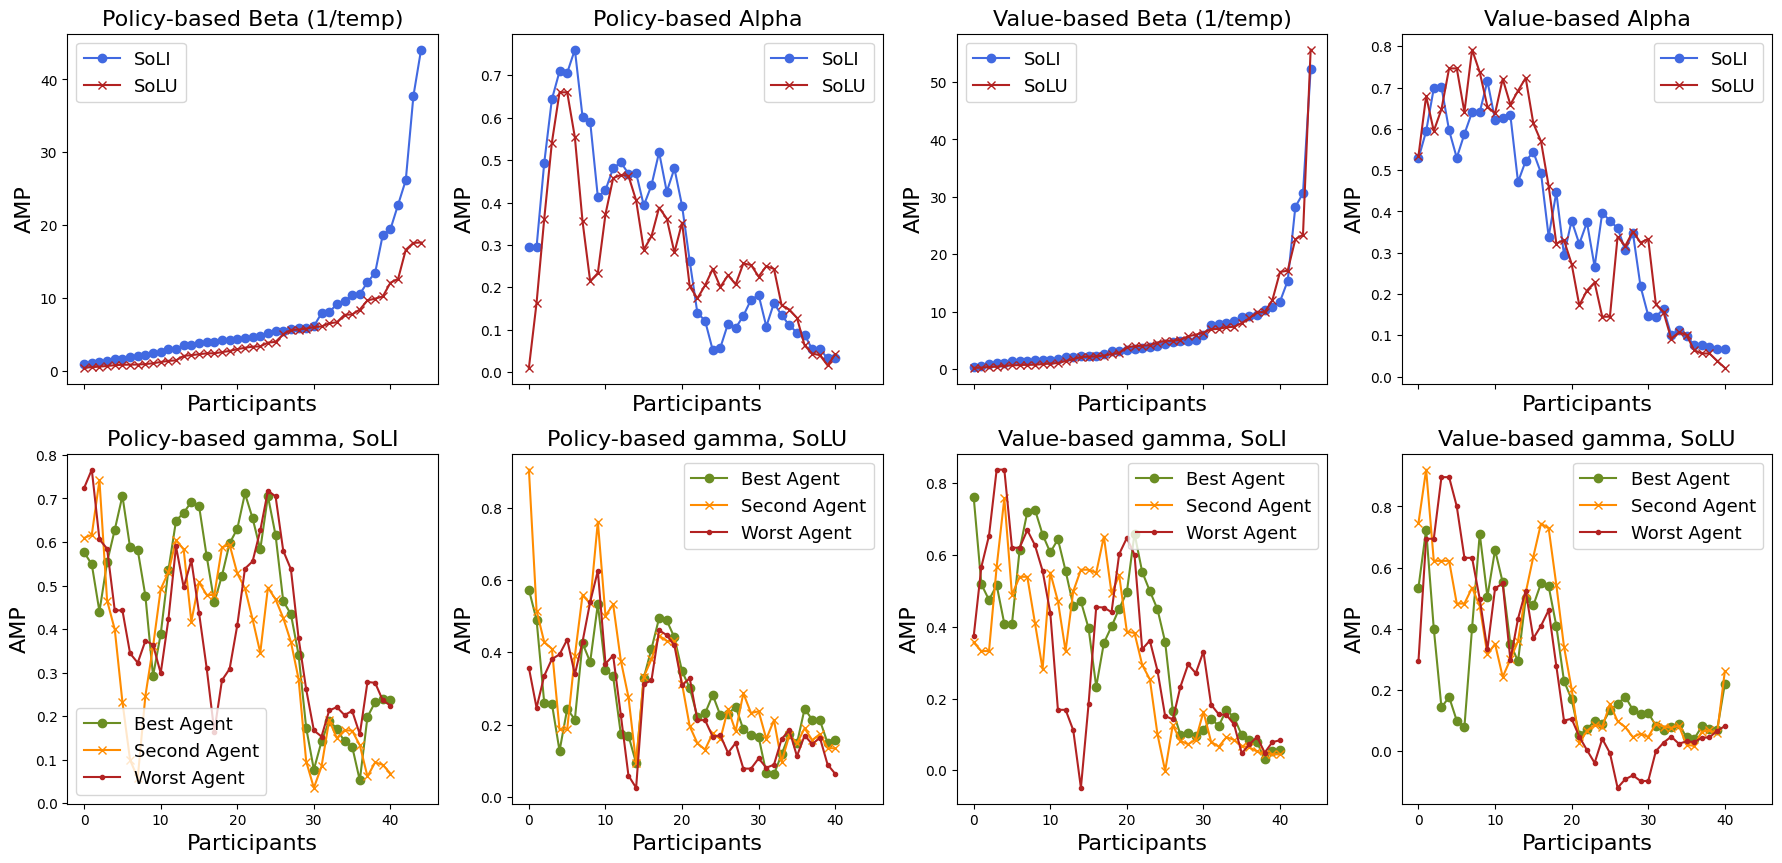

In [110]:
fig, axs = plt.subplots(2, 4, sharex='all', figsize=(22, 10))

x1 = [i for i in range(45)]
axs[0, 0].plot(p_sorted_beta_m, marker='o', label='SoLI', color='royalblue')
axs[0, 0].plot(U_p_sorted_beta_m, marker='x', label='SoLU', color='firebrick')
axs[0, 0].set_title('Policy-based Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(p_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 1].plot(np.convolve(U_p_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 1].set_title('Policy-based Alpha', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[0, 2].plot(v_sorted_beta_m, marker='o', label='SoLI', color='royalblue')
axs[0, 2].plot(U_v_sorted_beta_m, marker='x', label='SoLU', color='firebrick')
axs[0, 2].set_title('Value-based Beta (1/temp)', fontsize=16)
axs[0, 2].set_xlabel('Participants', fontsize=16)
axs[0, 2].set_ylabel('AMP', fontsize=16)
axs[0, 2].legend(loc=0, prop={'size':13})

axs[0, 3].plot(np.convolve(v_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 3].plot(np.convolve(U_v_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 3].set_title('Value-based Alpha', fontsize=16)
axs[0, 3].set_xlabel('Participants', fontsize=16)
axs[0, 3].set_ylabel('AMP', fontsize=16)
axs[0, 3].legend(loc=0, prop={'size':13})

axs[1, 0].plot(np.convolve(p_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 0].plot(np.convolve(p_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 0].plot(np.convolve(p_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 0].set_title('Policy-based gamma, SoLI', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(np.convolve(U_p_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 1].plot(np.convolve(U_p_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 1].plot(np.convolve(U_p_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 1].set_title('Policy-based gamma, SoLU', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

axs[1, 2].plot(np.convolve(v_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 2].plot(np.convolve(v_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 2].plot(np.convolve(v_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 2].set_title('Value-based gamma, SoLI', fontsize=16)
axs[1, 2].set_xlabel('Participants', fontsize=16)
axs[1, 2].set_ylabel('AMP', fontsize=16)
axs[1, 2].legend(loc=0, prop={'size':13})

axs[1, 3].plot(np.convolve(U_v_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 3].plot(np.convolve(U_v_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 3].plot(np.convolve(U_v_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 3].set_title('Value-based gamma, SoLU', fontsize=16)
axs[1, 3].set_xlabel('Participants', fontsize=16)
axs[1, 3].set_ylabel('AMP', fontsize=16)
axs[1, 3].legend(loc=0, prop={'size':13})


fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/newRL1.svg')

## Value based data sorting by best agent influence

SoLI

In [111]:
agv_sorted_best_m, agv_sorted_idx_m = sorted_g_m[:45, 0][np.argsort(sorted_g_m[:45, 0])], np.argsort(sorted_g_m[:45, 0])
agv_sorted_beta_m = np.array(all_epsilon_Qmean[:45])[list(agv_sorted_idx_m)]
agv_sorted_alpha_m = np.array(all_alpha_Qmean[:45])[list(agv_sorted_idx_m)]
agv_sorted_second_m = sorted_g_m[:45, 1][list(agv_sorted_idx_m)]
agv_sorted_worst_m = sorted_g_m[:45, 2][list(agv_sorted_idx_m)]

SoLU

In [112]:
U_agv_sorted_best_m, U_agv_sorted_idx_m = sorted_g_m[45:, 0][np.argsort(sorted_g_m[45:, 0])], np.argsort(sorted_g_m[45:, 0])
U_agv_sorted_beta_m = np.array(all_epsilon_Qmean[45:])[list(U_agv_sorted_idx_m)]
U_agv_sorted_alpha_m = np.array(all_alpha_Qmean[45:])[list(U_agv_sorted_idx_m)]
U_agv_sorted_second_m = sorted_g_m[45:, 1][list(U_agv_sorted_idx_m)]
U_agv_sorted_worst_m = sorted_g_m[45:, 2][list(U_agv_sorted_idx_m)]

## Policy based data sorting by best agent influence

SoLI

In [113]:
agp_sorted_best_m, agp_sorted_idx_m = sorted_pg_m[:45, 0][np.argsort(sorted_pg_m[:45, 0])], np.argsort(sorted_pg_m[:45, 0])
agp_sorted_beta_m = np.array(all_beta_pQmean[:45])[list(agp_sorted_idx_m)]
agp_sorted_alpha_m = np.array(all_alpha_pQmean[:45])[list(agp_sorted_idx_m)]
agp_sorted_second_m = sorted_pg_m[:45, 1][list(agp_sorted_idx_m)]
agp_sorted_worst_m = sorted_pg_m[:45, 2][list(agp_sorted_idx_m)]

SoLU

In [114]:
U_agp_sorted_best_m, U_agp_sorted_idx_m = sorted_pg_m[45:, 0][np.argsort(sorted_pg_m[45:, 0])], np.argsort(sorted_pg_m[45:, 0])
U_agp_sorted_beta_m = np.array(all_beta_pQmean[45:])[list(U_agp_sorted_idx_m)]
U_agp_sorted_alpha_m = np.array(all_alpha_pQmean[45:])[list(U_agp_sorted_idx_m)]
U_agp_sorted_second_m = sorted_pg_m[45:, 1][list(U_agp_sorted_idx_m)]
U_agp_sorted_worst_m = sorted_pg_m[45:, 2][list(U_agp_sorted_idx_m)]

## Visualizing

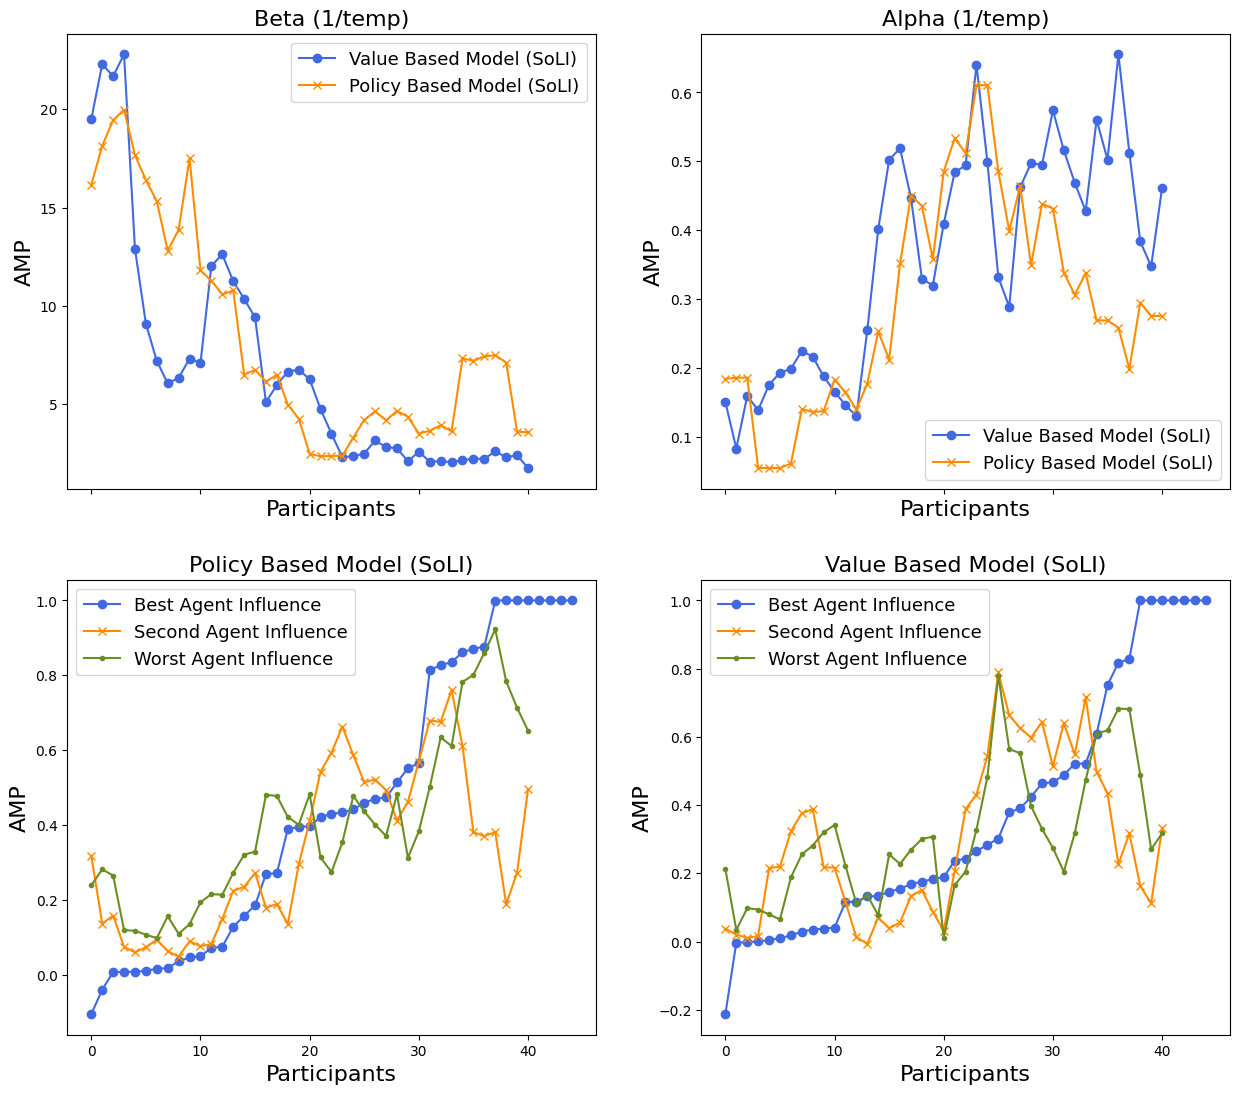

In [115]:
fig, axs = plt.subplots(2, 2, sharex='all', figsize=(15, 13))

x1 = [i for i in range(45)]

axs[0, 0].plot(np.convolve(agv_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 0].plot(np.convolve(agp_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='x', label='Policy Based Model (SoLI)', color='darkorange')
axs[0, 0].set_title('Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(agv_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 1].plot(np.convolve(agp_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='Policy Based Model (SoLI)', color='darkorange')
axs[0, 1].set_title('Alpha (1/temp)', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[1, 0].plot(agp_sorted_best_m, marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 0].plot(np.convolve(agp_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 0].plot(np.convolve(agp_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 0].set_title('Policy Based Model (SoLI)', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(agv_sorted_best_m, marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 1].plot(np.convolve(agv_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 1].plot(np.convolve(agv_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 1].set_title('Value Based Model (SoLI)', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

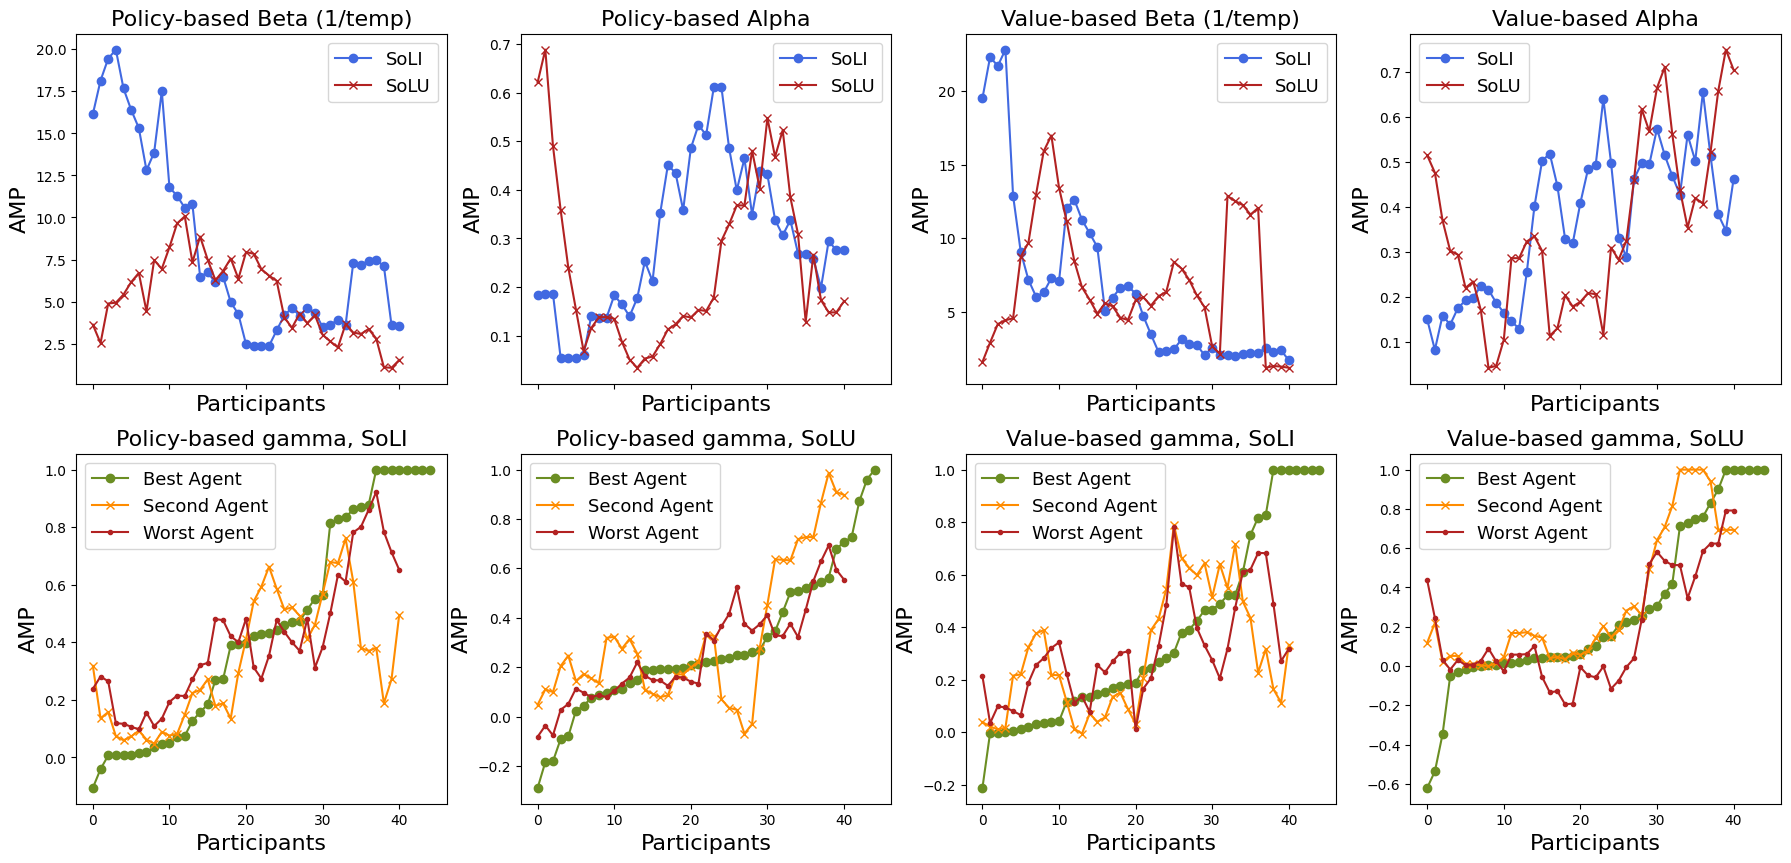

In [116]:
fig, axs = plt.subplots(2, 4, sharex='all', figsize=(22, 10))

x1 = [i for i in range(45)]




axs[0, 0].plot(np.convolve(agp_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 0].plot(np.convolve(U_agp_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 0].set_title('Policy-based Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(agp_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 1].plot(np.convolve(U_agp_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 1].set_title('Policy-based Alpha', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[0, 2].plot(np.convolve(agv_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 2].plot(np.convolve(U_agv_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 2].set_title('Value-based Beta (1/temp)', fontsize=16)
axs[0, 2].set_xlabel('Participants', fontsize=16)
axs[0, 2].set_ylabel('AMP', fontsize=16)
axs[0, 2].legend(loc=0, prop={'size':13})

axs[0, 3].plot(np.convolve(agv_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 3].plot(np.convolve(U_agv_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 3].set_title('Value-based Alpha', fontsize=16)
axs[0, 3].set_xlabel('Participants', fontsize=16)
axs[0, 3].set_ylabel('AMP', fontsize=16)
axs[0, 3].legend(loc=0, prop={'size':13})

axs[1, 0].plot(agp_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 0].plot(np.convolve(agp_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 0].plot(np.convolve(agp_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 0].set_title('Policy-based gamma, SoLI', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(U_agp_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 1].plot(np.convolve(U_agp_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 1].plot(np.convolve(U_agp_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 1].set_title('Policy-based gamma, SoLU', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

axs[1, 2].plot(agv_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 2].plot(np.convolve(agv_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 2].plot(np.convolve(agv_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 2].set_title('Value-based gamma, SoLI', fontsize=16)
axs[1, 2].set_xlabel('Participants', fontsize=16)
axs[1, 2].set_ylabel('AMP', fontsize=16)
axs[1, 2].legend(loc=0, prop={'size':13})

axs[1, 3].plot(U_agv_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 3].plot(np.convolve(U_agv_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 3].plot(np.convolve(U_agv_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 3].set_title('Value-based gamma, SoLU', fontsize=16)
axs[1, 3].set_xlabel('Participants', fontsize=16)
axs[1, 3].set_ylabel('AMP', fontsize=16)
axs[1, 3].legend(loc=0, prop={'size':13})

fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/newRL2.svg')

# Clustering

Performance

In [91]:
def perf_perc(sub_df):
    all_sub_b1_perf = []
    all_sub_b2_perf = []
    all_sub_b3_perf = []
    for sub in sub_df:
        b1_bc_count = 0
        b2_bc_count = 0
        b3_bc_count = 0
        for trial in range(0, 15):
            ch = sub['choice'][trial]
            card_probs = eval(sub['card probs'][trial])
            if ch == card_probs.index(0.7):
                b1_bc_count += 1
        all_sub_b1_perf.append(b1_bc_count/15)
        for trial in range(15, 45):
            ch = sub['choice'][trial]
            card_probs = eval(sub['card probs'][trial])
            if ch == card_probs.index(0.7):
                b2_bc_count += 1
        all_sub_b2_perf.append(b2_bc_count/30)
        for trial in range(45, 105):
            ch = sub['choice'][trial]
            card_probs = eval(sub['card probs'][trial])
            if ch == card_probs.index(0.7):
                b3_bc_count += 1
        all_sub_b3_perf.append(b3_bc_count/60)   
    return all_sub_b1_perf, all_sub_b2_perf, all_sub_b3_perf

In [92]:
def perff_2arm(sub_df):
    perf = []
    for idx, sub in enumerate(sub_df):
        bc_count = 0
        card_probs = eval(sub['probs'][0])
        bc_idx = card_probs.index(0.8)
        for trial in range(30):
            ch = sub['choice'][trial]
            if ch == bc_idx:
                bc_count += 1
        perf.append(bc_count/30)
    return perf

In [93]:
soli_b1_perf, soli_b2_perf, soli_b3_perf = perf_perc(all_trained_4arm_df)
soli_2arm_perf = perff_2arm(all_trained_2arm_df)

In [94]:
soli_b1_perf = np.array(soli_b1_perf)
soli_b2_perf = np.array(soli_b2_perf)
soli_b3_perf = np.array(soli_b3_perf)
soli_2arm_perf = np.array(soli_2arm_perf)

In [95]:
all_df = all_trained_4arm_df
b1_perf = soli_b1_perf
b2_perf = soli_b2_perf
b3_perf = soli_b3_perf
perf_2arm = soli_2arm_perf

In [96]:
def imitation_check(sub_df, start_trial, end_trial):
    sub_one_imit = 0
    sub_all_imit = 0
    ag_choice = 'x'
    for trial in range(start_trial, end_trial):
        sub_choice = sub_df['choice'][trial]
        if trial % 3 == 0:
            try:
                ag_choice = eval(sub_df['agent_choices'][trial])
            except:
                ag_choice = 100
            if sub_choice == ag_choice:
                sub_one_imit += 1
            
        if sub_choice == ag_choice:
            sub_all_imit += 1
    return sub_one_imit, sub_all_imit

In [97]:
joint_one_imit = []
joint_all_imit = []
for sub in all_df:
    one_imit, all_imit = imitation_check(sub, 45, 105)
    joint_one_imit.append(one_imit)
    joint_all_imit.append(all_imit)
    
joint_one_imit = np.array(joint_one_imit)
joint_all_imit = np.array(joint_all_imit)

Z Scoring

In [98]:
from scipy.stats import zscore

z_norm_b1_perf = zscore(b1_perf)
z_norm_b2_perf = zscore(b2_perf)
z_norm_b3_perf = zscore(b3_perf)
z_norm_2arm_perf = zscore(perf_2arm)

In [99]:
X = np.column_stack((z_norm_2arm_perf, z_norm_b1_perf, z_norm_b2_perf, z_norm_b3_perf))

In [100]:
Y = np.column_stack((perf_2arm, b1_perf, b2_perf, b3_perf))

In [101]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

agg_clustering = AgglomerativeClustering(n_clusters=3)
y_pred = agg_clustering.fit_predict(X)

In [102]:
labels = agg_clustering.labels_

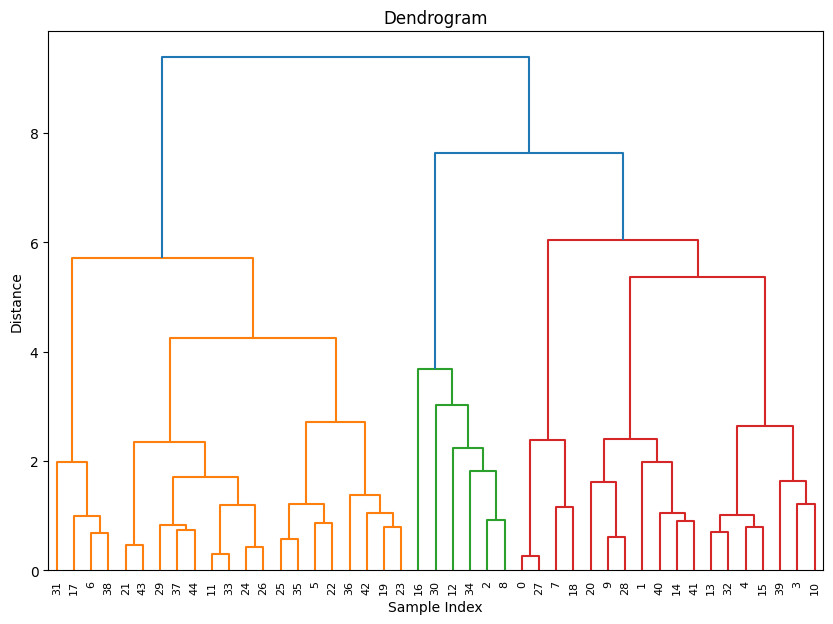

FileNotFoundError: [Errno 2] No such file or directory: 'D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Dendogram.svg'

In [103]:
Z = linkage(X, method='ward')

fig = plt.figure(figsize=(10, 7))
dendrogram(Z)
plt.title('Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Dendogram.svg')

In [104]:
c1_all_imit = []
c1_one_imit = []
c2_all_imit = []
c2_one_imit = []
c3_all_imit = []
c3_one_imit = []
for idx, sub_cluster in enumerate(labels):
    if sub_cluster == 0:
        c1_all_imit.append(joint_all_imit[idx])
        c1_one_imit.append(joint_one_imit[idx])
    elif sub_cluster == 1:
        c2_all_imit.append(joint_all_imit[idx])
        c2_one_imit.append(joint_one_imit[idx])
    else:
        c3_all_imit.append(joint_all_imit[idx])
        c3_one_imit.append(joint_one_imit[idx])

Text(0.5, 1.0, 'All imitation')

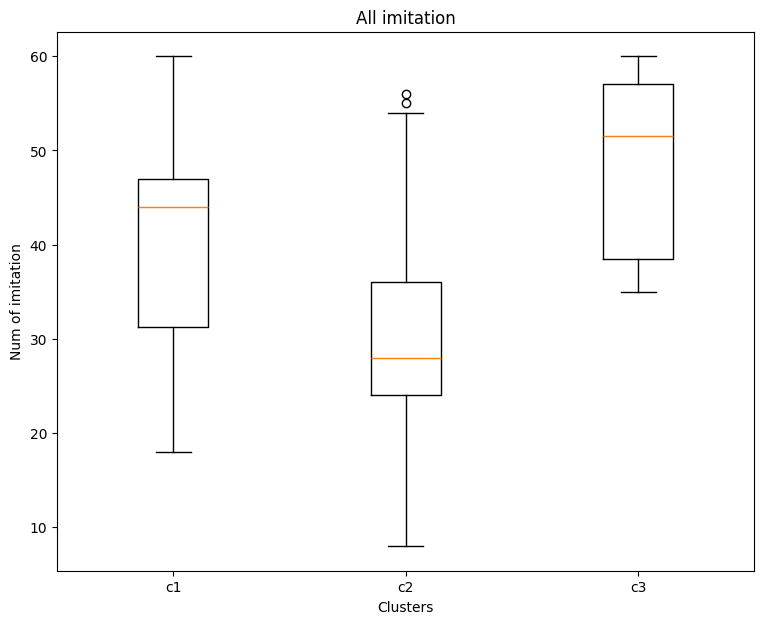

In [105]:
data1 = [c1_all_imit, c2_all_imit, c3_all_imit]
# data2 = [c1_one_imit, c2_one_imit, c3_one_imit]
cluster_labels = ['c1', 'c2', 'c3']


fig, axs = plt.subplots(1, 1, figsize=(9, 7))

# fig.suptitle('Entire block imitation')
axs.boxplot(data1)
# axs[1].boxplot(data2)

axs.set_xticklabels(cluster_labels)
# axs[1].set_xticklabels(cluster_labels)
axs.set_xlabel('Clusters')
axs.set_ylabel('Num of imitation')
# axs[1].set_xlabel('Clusters')
# axs[1].set_ylabel('Num of imitation')

axs.set_title('All imitation')
# axs[1].set_title('One imitation')

C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\3975629373.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


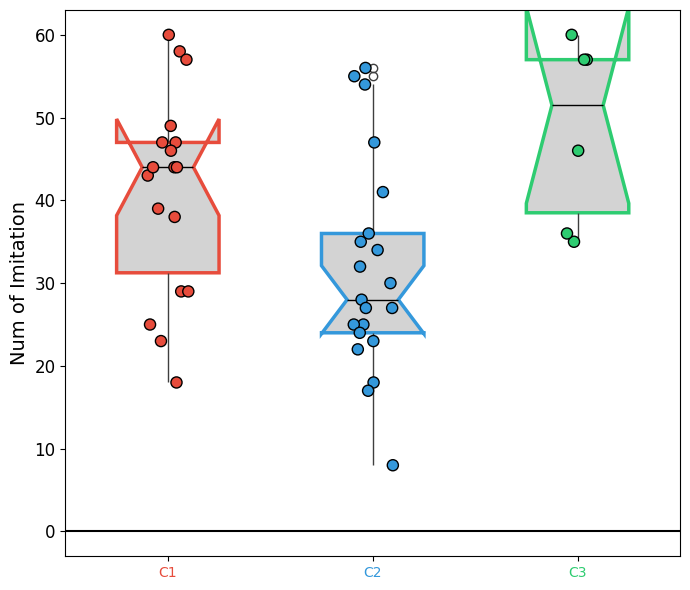

FileNotFoundError: [Errno 2] No such file or directory: 'D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Clustering.svg'

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Sample Data (Replace with your actual lists)
data1 = [c1_all_imit, c2_all_imit, c3_all_imit]
cluster_labels = ['C1', 'C2', 'C3']
colors = {'C1': '#E74C3C', 'C2': '#3498DB', 'C3': '#2ECC71'}  # Red, Blue, Green

# Convert data to long-form DataFrame
df = pd.DataFrame({
    'Clusters': sum([[cluster_labels[i]] * len(data1[i]) for i in range(3)], []),
    'Num of Imitation': sum(data1, [])
})

# Create the figure
fig = plt.figure(figsize=(7, 6))

# Boxplot with grey fill
boxplot = sns.boxplot(
    x='Clusters', y='Num of Imitation', data=df, 
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Initially set fill color
    medianprops={'color': 'black'}
)

# Manually set the edge color of each box
for i, artist in enumerate(boxplot.patches[:3]):  # Only first 3 are box bodies
    artist.set_edgecolor(colors[cluster_labels[i]])  # Set edge color
    artist.set_linewidth(2.5)  # Increase edge thickness

# Overlay a strip plot (Scatter points)
sns.stripplot(
    x='Clusters', y='Num of Imitation', data=df, 
    jitter=True, size=8, edgecolor='black', linewidth=1, 
    palette=[colors[c] for c in df['Clusters'].unique()]
)

# Add a horizontal reference line at 0
plt.axhline(0, color='black', linewidth=1.5)

# Set tick label colors
for tick, c in zip(plt.gca().get_xticklabels(), cluster_labels):
    tick.set_color(colors[c])

# Customizing the labels & title
plt.yticks(fontsize=12)
plt.ylabel('Num of Imitation', fontsize=14)
plt.xlabel('')
# plt.title('All Imitation', fontsize=16, fontweight='bold')

# P-value annotation
# plt.annotate(r'$P = 0.003$', xy=(1, max(df['Num of Imitation']) * 0.9), 
#              fontsize=14, fontstyle='italic', ha='center')

plt.tight_layout()
plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Clustering.svg')

gamma 

In [107]:
all_gamma = np.loadtxt('D:/University/University of Tehran/MSc/Thesis/task/Analysis/pgqm.txt')
trained_gamma = all_gamma[:45, :]
not_trained_gamma = all_gamma[45:, :]

In [108]:
c1_gamma = []
c2_gamma = []
c3_gamma = []

for idx, gm in enumerate(trained_gamma):
    if labels[idx] == 0:
        c1_gamma.append(gm)
    elif labels[idx] == 1:
        c2_gamma.append(gm)
    else:
        c3_gamma.append(gm)
        
c1_gamma = np.array(c1_gamma)
c2_gamma = np.array(c2_gamma)
c3_gamma = np.array(c3_gamma)

C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\2204926194.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\2204926194.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\2204926194.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


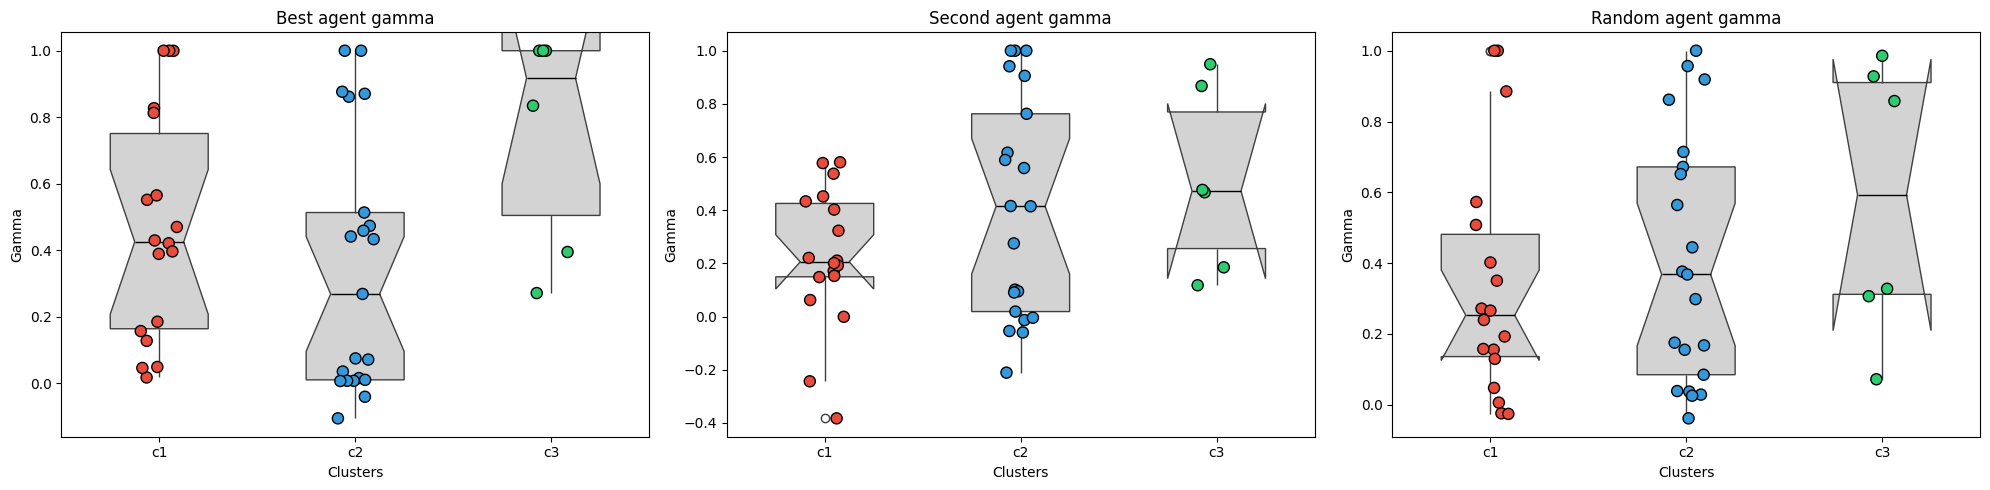

FileNotFoundError: [Errno 2] No such file or directory: 'D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/G-Clustering.svg'

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Sample data (replace with your actual arrays)
data1 = [c1_gamma[:, 0], c2_gamma[:, 0], c3_gamma[:, 0]]
data2 = [c1_gamma[:, 1], c2_gamma[:, 1], c3_gamma[:, 1]]
data3 = [c1_gamma[:, 2], c2_gamma[:, 2], c3_gamma[:, 2]]
cluster_labels = ['c1', 'c2', 'c3']
colors = {'c1': '#E74C3C', 'c2': '#3498DB', 'c3': '#2ECC71'}

# Create the figure with subplots
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
# fig.suptitle('SoLU Gammas for each cluster', fontsize=16)

# Concatenate the data using numpy
def create_df(data, cluster_labels):
    concatenated_data = np.concatenate(data)  # Concatenate the lists
    clusters = np.concatenate([[cluster_labels[i]] * len(data[i]) for i in range(len(data))])
    return pd.DataFrame({'Clusters': clusters, 'Gamma': concatenated_data})

# Create DataFrames for each gamma set
df1 = create_df(data1, cluster_labels)
df2 = create_df(data2, cluster_labels)
df3 = create_df(data3, cluster_labels)

# First subplot (Best agent gamma)
sns.boxplot(
    x='Clusters', y='Gamma', data=df1,
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Grey fill color for the boxes
    medianprops={'color': 'black'}, ax=axs[0]
)
# Overlay strip plot
sns.stripplot(
    x='Clusters', y='Gamma', data=df1,
    jitter=True, size=8, edgecolor='black', linewidth=1,
    palette=[colors[c] for c in cluster_labels], ax=axs[0]
)
axs[0].set_title('Best agent gamma')
axs[0].set_xlabel('Clusters')
axs[0].set_ylabel('Gamma')

# Second subplot (Second agent gamma)
sns.boxplot(
    x='Clusters', y='Gamma', data=df2,
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Grey fill color for the boxes
    medianprops={'color': 'black'}, ax=axs[1]
)
# Overlay strip plot
sns.stripplot(
    x='Clusters', y='Gamma', data=df2,
    jitter=True, size=8, edgecolor='black', linewidth=1,
    palette=[colors[c] for c in cluster_labels], ax=axs[1]
)
axs[1].set_title('Second agent gamma')
axs[1].set_xlabel('Clusters')
axs[1].set_ylabel('Gamma')

# Third subplot (Random agent gamma)
sns.boxplot(
    x='Clusters', y='Gamma', data=df3,
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Grey fill color for the boxes
    medianprops={'color': 'black'}, ax=axs[2]
)
# Overlay strip plot
sns.stripplot(
    x='Clusters', y='Gamma', data=df3,
    jitter=True, size=8, edgecolor='black', linewidth=1,
    palette=[colors[c] for c in cluster_labels], ax=axs[2]
)
axs[2].set_title('Random agent gamma')
axs[2].set_xlabel('Clusters')
axs[2].set_ylabel('Gamma')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/G-Clustering.svg')